# **Brain Tumor MRI Image Classification**    -

##### **Project Type**    - Classification (Deep Learning / Computer Vision / Medical Imaging)
##### **Contribution**    - Individual
##### **Team Member 1 -** *Saloumi Mitre*
##### **Team Member 2 -** *(N/A)*
##### **Team Member 3 -** *(N/A)*
##### **Team Member 4 -** *(N/A)*

# **Project Summary -**

Brain tumours are among the most serious neurological conditions, and the speed and accuracy with which they are recognised on an MRI scan strongly influences treatment planning and patient outcome. Radiologists must inspect large numbers of scans, which is time-consuming and subject to fatigue and inter-observer variability. This project builds a deep-learning system that classifies a brain MRI image into its tumour category (for example *glioma*, *meningioma*, *pituitary tumour* or *no tumour*) and exposes the result through a simple Streamlit web application.

**Data understanding.** The dataset is an image dataset organised in one folder per class (and, depending on the download, in train / validation / test folders). The notebook auto-detects the folder layout, builds a tidy metadata table (one row per image: path, class, split, width, height, colour mode, file size, intensity statistics and an MD5 fingerprint) and stores it as a CSV file and as a SQLite database. Corrupted files, exact duplicate images and *train/test leakage* (the same scan appearing in two splits) are detected and removed so that the reported scores are honest.

**Exploratory analysis.** Fifteen charts following the UBM rule (Univariate, Bivariate, Multivariate) explore class balance, resolution consistency, brightness / contrast per class, sample scans, average scans per class, a correlation heat-map and a pair plot. Three statistical hypothesis tests (Kruskal-Wallis, Chi-square goodness-of-fit and Mann-Whitney U) check whether the classes differ in simple image statistics, whether the classes are balanced and whether tumour scans have higher contrast than healthy scans.

**Pre-processing.** Every image is converted to 3-channel RGB, resized to 224 x 224 and scaled to the 0-1 range. A training-only augmentation pipeline (flips, rotation, zoom, shift, contrast and brightness changes) increases variety and reduces over-fitting. Class weights compensate for any class imbalance. A PCA projection is used to visualise how separable the classes are in raw pixel space.

**Modelling.** Four models are trained and compared: (1) a **custom CNN built from scratch** (four double-convolution blocks with batch-normalisation, progressive dropout and L2 regularisation), tuned with a random hyper-parameter search; and three **transfer-learning models** with ImageNet weights - **MobileNetV2**, **EfficientNetB0** and **ResNet50** - trained in two stages (frozen backbone, then fine-tuning of the top layers with a very small learning rate). EarlyStopping, ModelCheckpoint and ReduceLROnPlateau callbacks monitor the validation loss and keep the best weights.

**Evaluation.** Each model is evaluated on an untouched test set with accuracy, precision, recall, F1-score (macro and weighted), ROC-AUC, per-class recall, confusion matrices and training curves. Model selection uses the *validation* set (so the test set stays unbiased), and the comparison also considers parameter count, model size and inference time to identify the most accurate, efficient and reliable model. Model behaviour is explained with an occlusion-sensitivity analysis that highlights the image regions the final model relies on.

**Deployment.** The best model and every trained model are saved as `.h5` files together with a JSON configuration. A Streamlit application lets a user upload one or more MRI images, choose a model, and instantly see the predicted tumour type, the confidence score for every class, a low-confidence warning and a prediction history stored in SQLite.

**Business value.** The system can act as an AI second reader for radiologists, help prioritise suspicious scans in a hospital work-list, support research cohort building and bring second-opinion tools to under-resourced regions. It is a decision-support prototype and **not** a certified medical device; every prediction must be confirmed by a qualified clinician.

# **GitHub Link -**

Provide your GitHub Link here: `https://github.com/<your-username>/brain-tumor-mri-classification`

# **Problem Statement**

**Develop a deep-learning solution that classifies brain MRI images into tumour categories. Build a custom CNN from scratch, improve performance with transfer learning (ResNet50, MobileNetV2, EfficientNetB0), compare all models with accuracy, precision, recall, F1-score and confusion matrices, and deploy the best model in a Streamlit web application that returns the predicted tumour type with a confidence score for any uploaded MRI image.**

# **How to run this notebook**

1. **Install requirements** (once): `pip install -r requirements.txt`
2. **Put the dataset** next to this notebook in a folder called `Brain_Tumor_MRI_Dataset` (download the Drive folder / zip, extract it there).
   * A `.zip` file placed next to the notebook is extracted automatically.
   * Any folder layout is accepted: `train/valid/test/<class>/...`, `Training/Testing/<class>/...` or simply `<class>/...`.
3. **Run → Restart Kernel and Run All Cells.** The notebook is written to run top-to-bottom without errors.
4. After it finishes, open `Streamlit_Deployment.ipynb` (or run `streamlit run app.py`) to use the web app.

**Switches you can change** (cell *Configuration*): `QUICK_TEST = True` runs the whole pipeline on a tiny subset for 2 epochs (a 5-10 minute smoke test); `MODELS_TO_TRAIN` selects which transfer-learning models to train; `EPOCHS_*` and `BATCH_SIZE` control the runtime. A GPU (or Google Colab) is strongly recommended for the full run.

**Folders created automatically:** `models/` (.h5 files + JSON config), `outputs/` (all saved charts and tables), `data/` (metadata CSV + SQLite database), `checkpoints/` (best-weight checkpoints).

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # keep TensorFlow start-up messages quiet

import sys, re, json, time, math, random, hashlib, shutil, sqlite3, warnings, zipfile, gc
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve, auc)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
print("TensorFlow :", tf.__version__, "| Keras :", getattr(keras, "__version__", "n/a"))
print("GPU devices:", tf.config.list_physical_devices("GPU") or "none (training will run on CPU - it works, but is slower)")


TensorFlow : 2.15.1 | Keras : n/a
GPU devices: none (training will run on CPU - it works, but is slower)


### Configuration
All paths and hyper-parameters live in this single cell so the rest of the notebook never needs editing.

In [2]:
# ----------------------------- Configuration -----------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- folders (relative to the folder that contains this notebook)
BASE_DIR      = Path.cwd()
DATA_DIR      = BASE_DIR / "Brain_Tumor_MRI_Dataset"     # <- the dataset goes here (or change this path)
MODEL_DIR     = BASE_DIR / "models"
OUTPUT_DIR    = BASE_DIR / "outputs"
META_DIR      = BASE_DIR / "data"
CKPT_DIR      = BASE_DIR / "checkpoints"
for _d in (MODEL_DIR, OUTPUT_DIR, META_DIR, CKPT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ---- image settings
IMG_SIZE   = (160, 160)
IMG_SHAPE  = IMG_SIZE + (3,)
VALID_EXT  = (".jpg", ".jpeg", ".png", ".bmp")              # formats TensorFlow can decode
BATCH_SIZE = 32

# ---- experiment switches
QUICK_TEST        = False        # True  -> tiny subset + 2 epochs (smoke test of the whole notebook)
REMOVE_DUPLICATES = True         # remove exact duplicate images and train/test leakage
MODELS_TO_TRAIN   = ["MobileNetV2", "EfficientNetB0", "ResNet50"]   # transfer-learning models
RUN_CNN_TUNING    = True         # random hyper-parameter search for the custom CNN

if QUICK_TEST:
    EPOCHS_CNN, EPOCHS_HEAD, EPOCHS_FT = 2, 2, 2
    TUNE_TRIALS, TUNE_EPOCHS, FT_LAYERS = 2, 1, 20
else:
    EPOCHS_CNN, EPOCHS_HEAD, EPOCHS_FT = 25, 8, 10
    TUNE_TRIALS, TUNE_EPOCHS, FT_LAYERS = 4, 3, 30

def finish_plot(name=None):
    """Tidy layout, optionally save the figure into outputs/, then show it."""
    plt.tight_layout()
    if name:
        plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Project folder :", BASE_DIR)
print("QUICK_TEST     :", QUICK_TEST, "| epochs (CNN/head/fine-tune):", EPOCHS_CNN, EPOCHS_HEAD, EPOCHS_FT)

Project folder : C:\Users\Saloumi\Brain Tumor MRI Image Classification (Labmentix)
QUICK_TEST     : False | epochs (CNN/head/fine-tune): 25 8 10


### Dataset Loading
The helper functions below (1) find the dataset folder, (2) walk through it and create **one row per image** (this table is our "database"), (3) normalise class names and (4) make sure every image belongs to a *train / valid / test* split. If the dataset already ships with official splits they are used; if a split is missing it is created with a stratified random split.

In [3]:
# Load Dataset
SPLIT_ALIASES  = {"train": "train", "training": "train",
                  "valid": "valid", "val": "valid", "validation": "valid",
                  "test": "test", "testing": "test"}
GENERIC_FOLDERS = {"images", "image", "img", "imgs", "data", "dataset"}

def count_images(folder):
    """Number of decodable image files below a folder."""
    n = 0
    for _, _, files in os.walk(folder):
        n += sum(1 for f in files if f.lower().endswith(VALID_EXT) and not f.startswith("."))
    return n

def locate_dataset(preferred):
    """Find the dataset: preferred folder -> unzip a .zip next to the notebook -> scan sub-folders."""
    if preferred.exists() and count_images(preferred) > 0:
        return preferred
    for z in sorted(BASE_DIR.glob("*.zip")):                       # 1) a downloaded zip file
        try:
            print(f"Extracting {z.name} ...")
            with zipfile.ZipFile(z) as zf:
                zf.extractall(preferred)
            if count_images(preferred) > 0:
                return preferred
        except Exception as exc:
            print("  could not extract", z.name, "->", exc)
    skip = {MODEL_DIR.name, OUTPUT_DIR.name, META_DIR.name, CKPT_DIR.name, "__pycache__"}
    best, best_n = None, 0                                           # 2) any folder full of images
    for sub in BASE_DIR.iterdir():
        if sub.is_dir() and sub.name not in skip and not sub.name.startswith("."):
            n = count_images(sub)
            if n > best_n:
                best, best_n = sub, n
    if best is not None and best_n >= 50:
        print(f"Using '{best.name}' ({best_n:,} images found).")
        return best
    raise FileNotFoundError(
        f"Dataset not found. Download the dataset, extract it and place it in:\n  {preferred}\n"
        "(or change DATA_DIR in the Configuration cell).")

def build_file_index(root):
    """One row per image file: path, raw class folder name and raw split name (if any)."""
    rows = []
    for dirpath, dirnames, files in os.walk(root):
        dirnames[:] = [d for d in dirnames if not d.startswith((".", "__"))]
        rel = Path(dirpath).relative_to(root).parts
        for f in files:
            if f.startswith(".") or not f.lower().endswith(VALID_EXT):
                continue
            split = next((SPLIT_ALIASES[p.lower()] for p in rel if p.lower() in SPLIT_ALIASES), None)
            label = next((p for p in reversed(rel)
                          if p.lower() not in SPLIT_ALIASES and p.lower() not in GENERIC_FOLDERS), "unknown")
            rows.append({"filepath": str(Path(dirpath) / f), "filename": f,
                         "label_raw": label, "split_raw": split})
    return pd.DataFrame(rows)

def clean_name(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")

def canonical_name(name):
    """glioma_tumor -> glioma, notumor / no_tumour / normal -> no_tumor  (only used if class names differ between splits)."""
    n = clean_name(name)
    if re.fullmatch(r"no_?tumou?rs?|normal|healthy", n):
        return "no_tumor"
    stripped = re.sub(r"_?tumou?rs?$", "", n)
    return stripped or n

def safe_split(frame, test_size, seed=SEED):
    """Stratified split with a graceful fallback if a class is too small."""
    try:
        return train_test_split(frame, test_size=test_size, stratify=frame["label"], random_state=seed)
    except ValueError:
        return train_test_split(frame, test_size=test_size, random_state=seed)

def assign_splits(frame, val_size=0.15, test_size=0.15, seed=SEED):
    """Use official splits when present, otherwise create stratified ones. Returns (frame, note)."""
    frame = frame.copy()
    present = set(frame["split_raw"].dropna())
    if "train" not in present or not (present - {"train"}):          # no usable official split
        tr, tmp = safe_split(frame, val_size + test_size, seed)
        va, te = safe_split(tmp, test_size / (val_size + test_size), seed)
        out = pd.concat([tr.assign(split="train"), va.assign(split="valid"), te.assign(split="test")])
        return out.sort_index(), "No official split found -> created a stratified 70/15/15 split."
    frame["split"] = frame["split_raw"].fillna("train")
    note = "Official split folders were used."
    if "test" not in present:                                       # only train + valid -> halve valid
        _, te = safe_split(frame[frame["split"] == "valid"], 0.5, seed)
        frame.loc[te.index, "split"] = "test"
        note += " (no test folder -> half of 'valid' became the test set)"
    elif "valid" not in present:                                    # only train + test -> carve valid from train
        _, va = safe_split(frame[frame["split"] == "train"], val_size, seed)
        frame.loc[va.index, "split"] = "valid"
        note += " (no valid folder -> 15% of 'train' became the validation set)"
    return frame, note

# ---- run the loading pipeline ----
DATA_ROOT = locate_dataset(DATA_DIR)
df = build_file_index(DATA_ROOT)
if df.empty:
    raise RuntimeError(f"No images found under {DATA_ROOT}")

df["label_raw"] = df["label_raw"].map(clean_name)
sets_per_split = df.dropna(subset=["split_raw"]).groupby("split_raw")["label_raw"].agg(lambda s: frozenset(s))
if sets_per_split.nunique() > 1:                                     # class folders are named differently per split
    print("Class names differ between splits -> harmonising them:", {k: sorted(v) for k, v in sets_per_split.items()})
    df["label"] = df["label_raw"].map(canonical_name)
else:
    df["label"] = df["label_raw"]
if df["label"].nunique() < 2:
    raise RuntimeError("Fewer than 2 classes were detected. Expected one sub-folder per class, e.g. glioma/, meningioma/ ...")

df = df.reset_index(drop=True)
df, split_note = assign_splits(df)
df = df.sort_values(["split", "label", "filepath"]).reset_index(drop=True)

print("Dataset folder :", DATA_ROOT)
print("Split handling :", split_note)
print("Classes found  :", sorted(df["label"].unique()))
print(f"Images indexed : {len(df):,}")

Dataset folder : C:\Users\Saloumi\Brain Tumor MRI Image Classification (Labmentix)\Brain_Tumor_MRI_Dataset
Split handling : Official split folders were used.
Classes found  : ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Images indexed : 2,443


### Dataset First View

,filepath,filename,label_raw,split_raw,label,split
0,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,glioma,test,glioma,test
1,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a6...,glioma,test,glioma,test
2,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c4504...,glioma,test,glioma,test
3,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad...,glioma,test,glioma,test
4,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf42a0c86b97f8...,glioma,test,glioma,test
5,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0037_jpg.rf.6ac80086817a5d840d3b63495629...,glioma,test,glioma,test
6,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0040_jpg.rf.4e8e95e2b510b798b62954aa8d3e...,glioma,test,glioma,test
7,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0042_jpg.rf.c825249fca17c0579976c6455ed0...,glioma,test,glioma,test
8,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0075_jpg.rf.687ed8298bed6c85cb35c9c8f3ec...,glioma,test,glioma,test
9,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,Tr-gl_0081_jpg.rf.cd6ff4a250465f60361ab931fe2c...,glioma,test,glioma,test


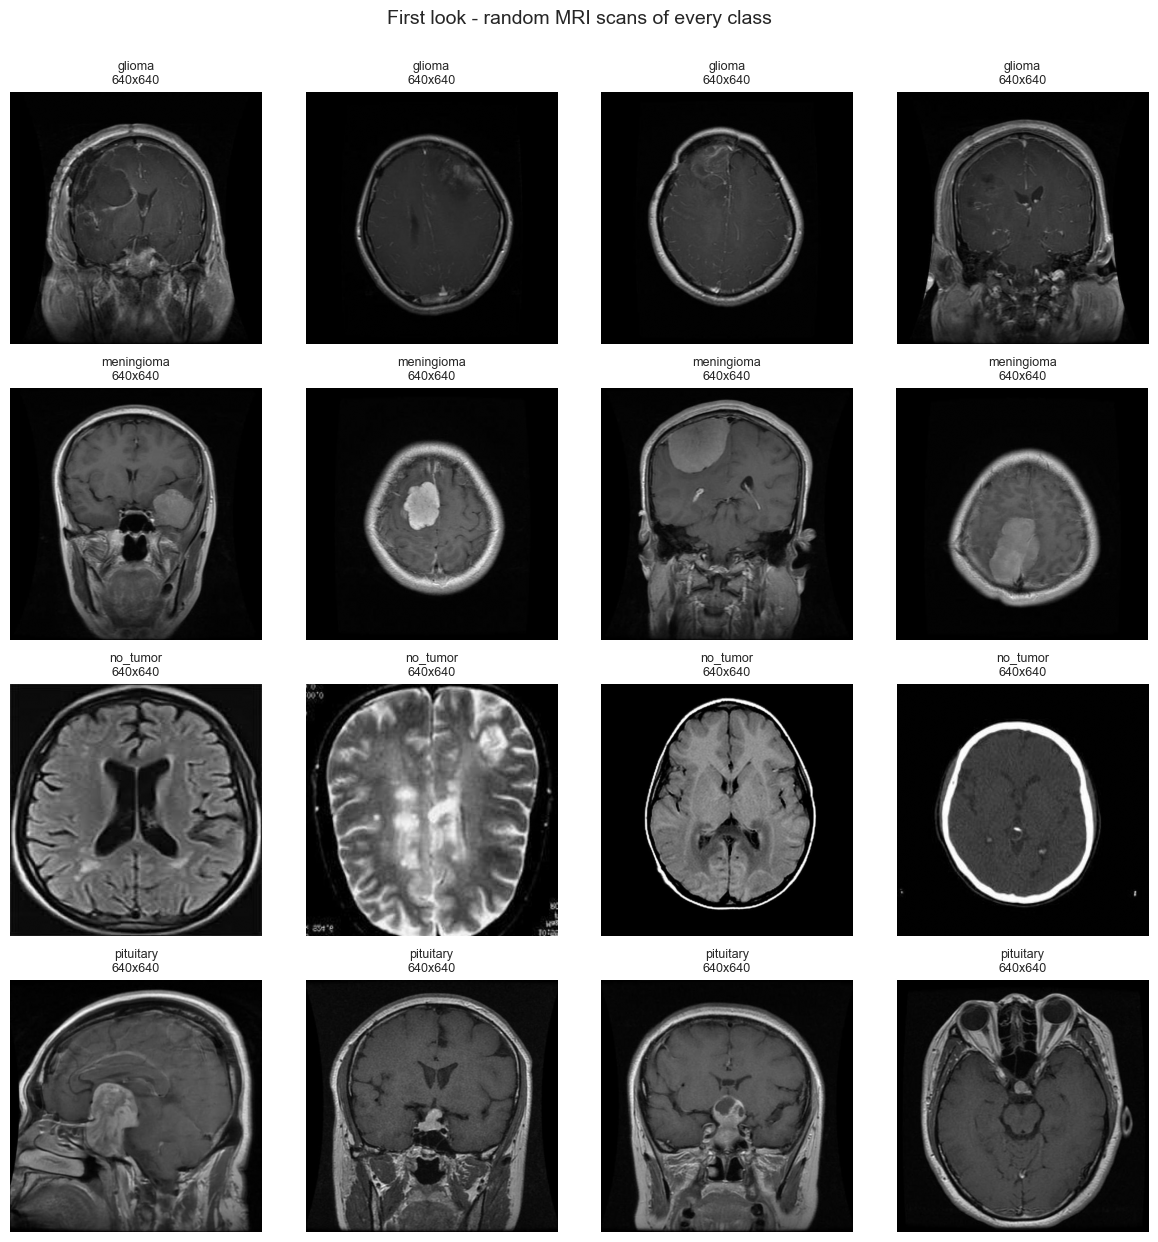

In [4]:
# Dataset First Look
display(df.head(10))

def show_samples(frame, n_per_class=4, title="Sample MRI images", save_as=None):
    """Grid of random scans: one row per class."""
    classes = sorted(frame["label"].unique())
    fig, axes = plt.subplots(len(classes), n_per_class, figsize=(3 * n_per_class, 3.1 * len(classes)), squeeze=False)
    for i, c in enumerate(classes):
        pool = frame[frame["label"] == c]
        sub = pool.sample(min(n_per_class, len(pool)), random_state=SEED)
        for j in range(n_per_class):
            ax = axes[i, j]; ax.axis("off")
            if j < len(sub):
                try:
                    with Image.open(sub.iloc[j]["filepath"]) as im:
                        ax.imshow(im.convert("L"), cmap="gray")
                        ax.set_title(f"{c}\n{im.size[0]}x{im.size[1]}", fontsize=9)
                except Exception:
                    ax.set_title("unreadable", fontsize=9)
    fig.suptitle(title, fontsize=14, y=1.0)
    finish_plot(save_as)

show_samples(df, n_per_class=4, title="First look - random MRI scans of every class")

### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(f"Number of rows (images)      : {df.shape[0]:,}")
print(f"Number of columns (variables): {df.shape[1]}")
print("\nImages per split and class (as found in the dataset):")
display(pd.crosstab(df["label"], df["split"], margins=True))

Number of rows (images)      : 2,443
Number of columns (variables): 6

Images per split and class (as found in the dataset):


split,test,train,valid,All
label,,,,
glioma,80,564,161,805
meningioma,63,358,124,545
no_tumor,49,335,99,483
pituitary,54,438,118,610
All,246,1695,502,2443


### Dataset Information
An image dataset has no ready-made numeric columns, so we first **extract metadata from every image** (size, colour mode, file size, brightness / contrast statistics and an MD5 fingerprint) using a thread pool. The same pass checks that each file can really be decoded.

In [6]:
# Dataset Info  -> extract the metadata of every image
def extract_metadata(path):
    """Read one image and return its descriptive statistics (never raises)."""
    out = {"width": np.nan, "height": np.nan, "color_mode": None, "file_kb": np.nan,
           "mean_intensity": np.nan, "std_intensity": np.nan, "md5": None, "readable": False}
    try:
        out["file_kb"] = os.path.getsize(path) / 1024
        with open(path, "rb") as fh:
            out["md5"] = hashlib.md5(fh.read()).hexdigest()          # fingerprint -> duplicate detection
        with Image.open(path) as im:
            out["width"], out["height"] = im.size
            out["color_mode"] = im.mode
            g = np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32) / 255.0   # forces a full decode
            out["mean_intensity"], out["std_intensity"] = float(g.mean()), float(g.std())
            out["readable"] = True
    except Exception:
        pass
    return out

t0 = time.time()
with ThreadPoolExecutor(max_workers=min(8, (os.cpu_count() or 4))) as pool:
    meta = list(pool.map(extract_metadata, df["filepath"].tolist()))
df = pd.concat([df.reset_index(drop=True), pd.DataFrame(meta)], axis=1)
df["aspect_ratio"] = df["width"] / df["height"]
df["megapixels"]   = df["width"] * df["height"] / 1e6
print(f"Metadata extracted for {len(df):,} images in {time.time() - t0:.1f} s\n")
df.info()

Metadata extracted for 2,443 images in 6.9 s

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443 entries, 0 to 2442
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   filepath        2443 non-null   object 
 1   filename        2443 non-null   object 
 2   label_raw       2443 non-null   object 
 3   split_raw       2443 non-null   object 
 4   label           2443 non-null   object 
 5   split           2443 non-null   object 
 6   width           2443 non-null   int64  
 7   height          2443 non-null   int64  
 8   color_mode      2443 non-null   object 
 9   file_kb         2443 non-null   float64
 10  mean_intensity  2443 non-null   float64
 11  std_intensity   2443 non-null   float64
 12  md5             2443 non-null   object 
 13  readable        2443 non-null   bool   
 14  aspect_ratio    2443 non-null   float64
 15  megapixels      2443 non-null   float64
dtypes: bool(1), float64(5), int64(2)

#### Duplicate Values
Two *different file names* can contain the *same scan*. We detect them with the MD5 fingerprint. Duplicates are dangerous because a copy that sits in both the training and the test set inflates the test score (**data leakage**).

In [7]:
# Dataset Duplicate Value Count
dup_all    = df.duplicated(subset="md5", keep="first") & df["md5"].notna()
dup_groups = df[df["md5"].notna()].groupby("md5").filter(lambda g: len(g) > 1)
cross_split = dup_groups.groupby("md5")["split"].nunique().gt(1).sum() if len(dup_groups) else 0
conflict    = dup_groups.groupby("md5")["label"].nunique().gt(1).sum() if len(dup_groups) else 0

print(f"Duplicate image files (identical content)  : {dup_all.sum():,}")
print(f"Duplicate groups                           : {dup_groups['md5'].nunique():,}")
print(f"Groups that cross train/valid/test (LEAKAGE): {cross_split:,}")
print(f"Groups carrying conflicting class labels    : {conflict:,}")
print(f"Duplicate rows in the table itself          : {df.duplicated(subset=['filepath']).sum()}")

Duplicate image files (identical content)  : 0
Duplicate groups                           : 0
Groups that cross train/valid/test (LEAKAGE): 0
Groups carrying conflicting class labels    : 0
Duplicate rows in the table itself          : 0


#### Missing Values/Null Values
For images, "missing" means a file that cannot be opened/decoded (corrupted or truncated), which shows up as empty metadata.

In [8]:
# Missing Values/Null Values Count
meta_cols = ["width", "height", "color_mode", "file_kb", "mean_intensity", "std_intensity", "md5"]
missing = df[meta_cols].isnull().sum()
print("Null values per metadata column:\n", missing.to_string())
print(f"\nUnreadable / corrupted images: {(~df['readable']).sum():,}")

Null values per metadata column:
 width             0
height            0
color_mode        0
file_kb           0
mean_intensity    0
std_intensity     0
md5               0

Unreadable / corrupted images: 0


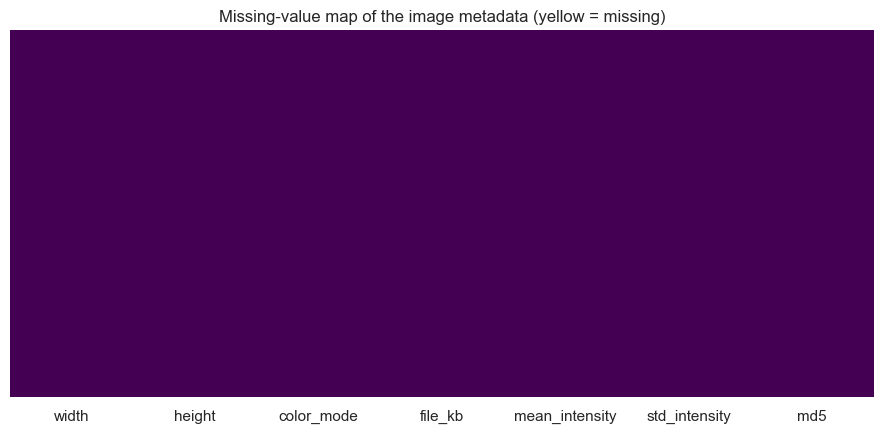

Nothing is missing: every image could be opened and decoded.


In [9]:
# Visualizing the missing values
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(df[meta_cols].isnull().astype(int), cbar=False, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title("Missing-value map of the image metadata (yellow = missing)")
finish_plot("00_missing_values")
if missing.sum() == 0:
    print("Nothing is missing: every image could be opened and decoded.")

### What did you know about your dataset?

* The dataset is a **multi-class image dataset of brain MRI scans**; the class is given by the **folder name** (e.g. glioma, meningioma, pituitary, no tumour). The exact classes, counts and split sizes are printed in the cells above.
* There is **no tabular data and no database** shipped with the project, so the notebook *creates* its own metadata table (one row per image) and stores it as `data/image_metadata.csv` and in a SQLite database.
* The images can differ in **resolution, colour mode and aspect ratio**, so they must be resized to one fixed input shape.
* Exact **duplicates** and **train/test leakage** are checked with MD5 fingerprints; unreadable files are counted as missing values. Both issues are handled in the next sections.
* Class sizes are usually **not perfectly equal**, which is why we later use class weights and macro-averaged metrics (not accuracy alone).

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print(df.columns.tolist())

['filepath', 'filename', 'label_raw', 'split_raw', 'label', 'split', 'width', 'height', 'color_mode', 'file_kb', 'mean_intensity', 'std_intensity', 'md5', 'readable', 'aspect_ratio', 'megapixels']


In [11]:
# Dataset Describe
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
filepath,2443,2443,C:\Users\Saloumi\Brain Tumor MRI Image Classif...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
filename,2443,2443,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label_raw,2443,4,glioma,805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split_raw,2443,3,train,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,2443,4,glioma,805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,2443,3,train,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
width,2443.0,NaN,NaN,NaN,640.0,0.0,640.0,640.0,640.0,640.0,640.0
height,2443.0,NaN,NaN,NaN,640.0,0.0,640.0,640.0,640.0,640.0,640.0
color_mode,2443,1,RGB,2443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
file_kb,2443.0,NaN,NaN,NaN,31.165728,9.092209,16.444336,24.048828,30.009766,36.708008,121.681641


### Variables Description

| Variable | Type | Description |
|---|---|---|
| `filepath`, `filename` | text | Location / name of the image file |
| `label_raw` | categorical | Class folder name exactly as found on disk (normalised to lower-case) |
| `label` | categorical (**target**) | Tumour class used for training (harmonised across splits) |
| `split_raw`, `split` | categorical | Split found on disk / final split (`train`, `valid`, `test`) |
| `width`, `height` | numeric | Image size in pixels |
| `aspect_ratio` | numeric | `width / height` |
| `megapixels` | numeric | `width x height / 1e6` |
| `color_mode` | categorical | PIL mode: `L` (grayscale), `RGB`, ... |
| `file_kb` | numeric | File size in kilobytes (a rough proxy for image detail) |
| `mean_intensity` | numeric | Average pixel brightness (0 = black, 1 = white) of the 64x64 grayscale version |
| `std_intensity` | numeric | Standard deviation of the brightness = contrast |
| `md5` | text | Content fingerprint used to find duplicates |
| `readable` | boolean | `True` if the file could be decoded |

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in df.columns:
    n_unique = df[col].nunique(dropna=True)
    preview = f" -> {sorted(df[col].dropna().unique().tolist())[:8]}" if n_unique <= 8 else ""
    print(f"{col:<16} : {n_unique:>6,} unique values{preview}")

filepath         :  2,443 unique values
filename         :  2,443 unique values
label_raw        :      4 unique values -> ['glioma', 'meningioma', 'no_tumor', 'pituitary']
split_raw        :      3 unique values -> ['test', 'train', 'valid']
label            :      4 unique values -> ['glioma', 'meningioma', 'no_tumor', 'pituitary']
split            :      3 unique values -> ['test', 'train', 'valid']
width            :      1 unique values -> [640]
height           :      1 unique values -> [640]
color_mode       :      1 unique values -> ['RGB']
file_kb          :  2,340 unique values
mean_intensity   :  2,386 unique values
std_intensity    :  2,442 unique values
md5              :  2,443 unique values
readable         :      1 unique values -> [True]
aspect_ratio     :      1 unique values -> [1.0]
megapixels       :      1 unique values -> [0.4096]


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
n_start = len(df)

# 1) Drop unreadable (corrupted) images -------------------------------------------------------
n_bad = int((~df["readable"]).sum())
df = df[df["readable"]].copy()

# 2) Remove exact duplicates and train/test leakage ---------------------------------------------
#    Priority test > valid > train: when the same scan exists in several places the copy in the
#    most "protected" split is kept and the others are dropped (so no test image is ever seen in training).
n_dup = 0
if REMOVE_DUPLICATES:
    df["_prio"] = df["split"].map({"test": 0, "valid": 1, "train": 2})
    df = df.sort_values(["_prio", "filepath"]).reset_index(drop=True)
    mask = df.duplicated(subset="md5", keep="first")
    n_dup = int(mask.sum())
    df = df[~mask].drop(columns="_prio")

# 3) Tidy-up -------------------------------------------------------------------------------------
df["resolution"] = df["width"].astype(int).astype(str) + "x" + df["height"].astype(int).astype(str)
df["color_mode"] = df["color_mode"].fillna("unknown")

# 4) Optional tiny subset for the smoke test ----------------------------------------------------
if QUICK_TEST:
    df = df.groupby(["split", "label"], group_keys=False).head(40)
    print("QUICK_TEST is ON -> using at most 40 images per class and split.")

df = df.sort_values(["split", "label", "filepath"]).reset_index(drop=True)

class_names = sorted(df["label"].unique().tolist())
NUM_CLASSES = len(class_names)
palette     = dict(zip(class_names, sns.color_palette("Set2", NUM_CLASSES)))
NUM_COLS    = ["width", "height", "aspect_ratio", "megapixels", "file_kb", "mean_intensity", "std_intensity"]

print(f"Images at start            : {n_start:,}")
print(f"Removed (unreadable)       : {n_bad:,}")
print(f"Removed (duplicates/leak)  : {n_dup:,}")
print(f"Images after wrangling     : {len(df):,}")
print(f"Classes ({NUM_CLASSES})              : {class_names}\n")
display(pd.crosstab(df["label"], df["split"], margins=True))

# 5) Save the analysis-ready metadata: CSV + SQLite database -----------------------------------------
df.to_csv(META_DIR / "image_metadata.csv", index=False)
DB_PATH = META_DIR / "brain_tumor_mri.db"
with sqlite3.connect(DB_PATH) as con:
    df.drop(columns=["readable"]).to_sql("image_metadata", con, if_exists="replace", index=False)
    con.execute("CREATE INDEX IF NOT EXISTS idx_label_split ON image_metadata(label, split)")
print(f"\nSaved: {META_DIR / 'image_metadata.csv'}  and SQLite table 'image_metadata' in {DB_PATH}")

Images at start            : 2,443
Removed (unreadable)       : 0
Removed (duplicates/leak)  : 0
Images after wrangling     : 2,443
Classes (4)              : ['glioma', 'meningioma', 'no_tumor', 'pituitary']



split,test,train,valid,All
label,,,,
glioma,80,564,161,805
meningioma,63,358,124,545
no_tumor,49,335,99,483
pituitary,54,438,118,610
All,246,1695,502,2443



Saved: C:\Users\Saloumi\Brain Tumor MRI Image Classification (Labmentix)\data\image_metadata.csv  and SQLite table 'image_metadata' in C:\Users\Saloumi\Brain Tumor MRI Image Classification (Labmentix)\data\brain_tumor_mri.db


### What all manipulations have you done and insights you found?

* **Indexed** every image file and derived the class from its folder name; class names were harmonised if the splits used different spellings (e.g. `glioma_tumor` vs `glioma`).
* **Created / validated the train-valid-test split** (official folders are used if present; otherwise a stratified 70/15/15 split).
* **Extracted metadata** (size, colour mode, file size, brightness, contrast, MD5) to turn an image folder into an analysable table.
* **Removed corrupted files** (they would crash the training input pipeline) and **removed exact duplicates / leakage** (they would inflate the test accuracy).
* **Saved** the cleaned table as a CSV file and as a SQLite database so that the analysis can be repeated or queried with SQL.
* **Insight:** the counts printed above show the real class balance after cleaning, and the resolution / intensity columns will be used in the charts below to check whether simple image statistics could act as an unintended *shortcut* for the model.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

The charts follow the **UBM rule** - **U**nivariate (charts 1-6), **B**ivariate (charts 7-13) and **M**ultivariate (charts 14-15). Each chart prints a short *data-driven insight line* below it, so the numbers quoted always match the dataset you are running.

#### Chart - 1 : Class distribution (bar chart)

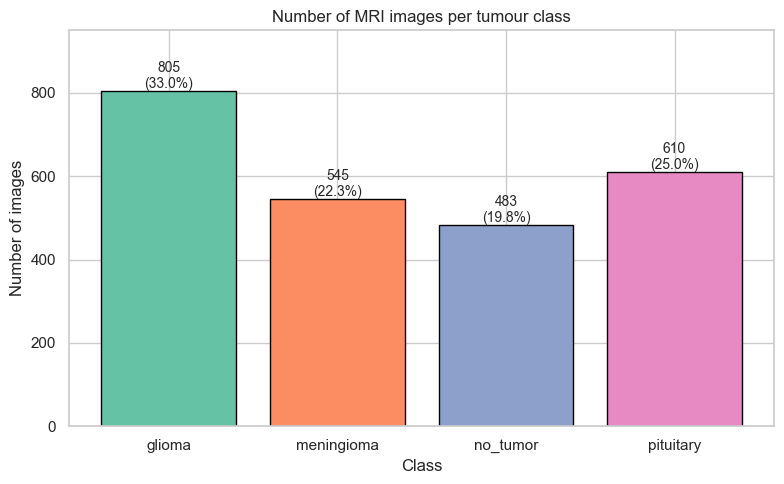

Largest class: glioma (805) | Smallest class: no_tumor (483) | Imbalance ratio (max/min) = 1.67


In [14]:
# Chart - 1 visualization code
counts = df["label"].value_counts().reindex(class_names)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index, counts.values, color=[palette[c] for c in counts.index], edgecolor="black")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Number of MRI images per tumour class")
ax.set_xlabel("Class"); ax.set_ylabel("Number of images")
finish_plot("01_class_distribution")
print(f"Largest class: {counts.idxmax()} ({counts.max():,}) | Smallest class: {counts.idxmin()} ({counts.min():,}) "
      f"| Imbalance ratio (max/min) = {counts.max() / counts.min():.2f}")

##### 1. Why did you pick the specific chart?

A bar chart is the clearest way to compare the **size of categories**. The target variable is categorical, so its balance is the first thing to check: it decides whether accuracy is a trustworthy metric and whether class weights are needed.

##### 2. What is/are the insight(s) found from the chart?

The chart shows how many scans each class has and the imbalance ratio (printed under the chart). A ratio close to 1 means a balanced dataset; a larger ratio means the model will see some tumour types far more often than others.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing the balance lets us choose the right remedy (class weights, macro-F1, per-class recall) so that no tumour type is neglected - important because a missed tumour is clinically costly. **Negative risk:** if a class is clearly under-represented, an accuracy-only model would look good while failing on that tumour type, which would reduce trust in the product.

#### Chart - 2 : Class share (donut chart)

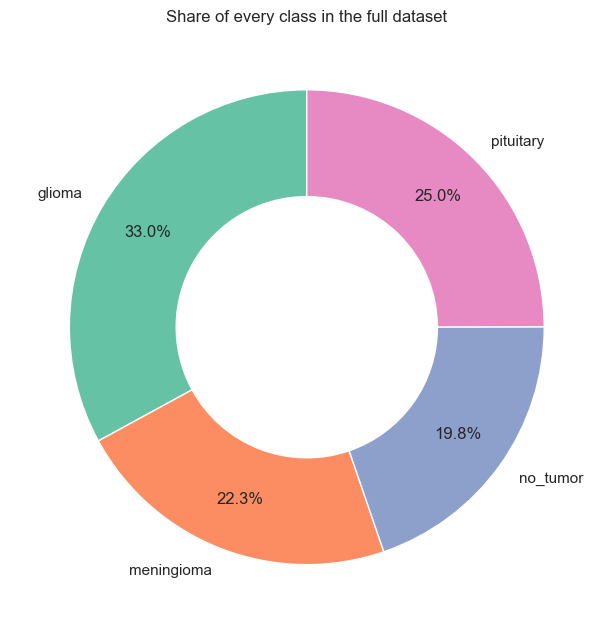

A perfectly balanced dataset would give 25.0% per class. Biggest deviation: 8.0 percentage points.


In [15]:
# Chart - 2 visualization code
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
       colors=[palette[c] for c in counts.index], wedgeprops=dict(width=0.45, edgecolor="white"))
ax.set_title("Share of every class in the full dataset")
finish_plot("02_class_share_donut")
uniform = 100 / NUM_CLASSES
print(f"A perfectly balanced dataset would give {uniform:.1f}% per class. Biggest deviation: "
      f"{(counts / counts.sum() * 100 - uniform).abs().max():.1f} percentage points.")

##### 1. Why did you pick the specific chart?

A donut chart shows **part-to-whole** relationships, which complements chart 1 (absolute numbers) with relative shares. It is only used because the number of categories is small (<= 6), where a pie-type chart is still readable.

##### 2. What is/are the insight(s) found from the chart?

Each slice is the percentage of the dataset belonging to a class; the printed line compares it with the perfectly balanced share (100 / number of classes).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** stakeholders instantly see the 'prevalence' of every tumour type in the training data, which can be compared with the real hospital case-mix before deployment. **Negative risk:** if the training prevalence differs strongly from the hospital's real prevalence, predicted probabilities may be mis-calibrated and need re-calibration.

#### Chart - 3 : Train / validation / test sizes (bar chart)

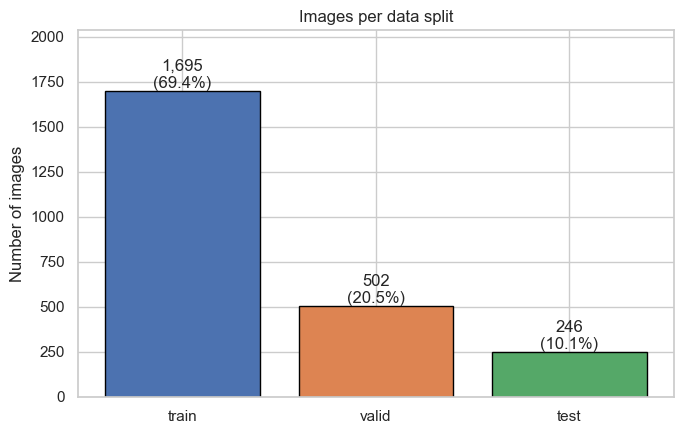

Split ratio (train : valid : test) = 69% : 21% : 10%


In [16]:
# Chart - 3 visualization code
split_counts = df["split"].value_counts().reindex(["train", "valid", "test"]).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(split_counts.index, split_counts.values, color=["#4C72B0", "#DD8452", "#55A868"], edgecolor="black")
for b, v in zip(bars, split_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / split_counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylim(0, split_counts.max() * 1.2)
ax.set_title("Images per data split"); ax.set_ylabel("Number of images")
finish_plot("03_split_sizes")
print("Split ratio (train : valid : test) =", " : ".join(f"{v / split_counts.sum():.0%}" for v in split_counts.values))

##### 1. Why did you pick the specific chart?

A simple bar chart is ideal for comparing three counts. Checking split sizes confirms that the model is trained on enough data and evaluated on a large enough, separate test set.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the proportion of data used for learning (train), tuning / early stopping (valid) and final reporting (test).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a sufficiently large, untouched test set gives a reliable estimate of real-world performance, which is what a hospital buyer needs. **Negative risk:** a very small validation or test set would give noisy scores; in that case results should be reported with caution.

#### Chart - 4 : Image width and height (histograms)

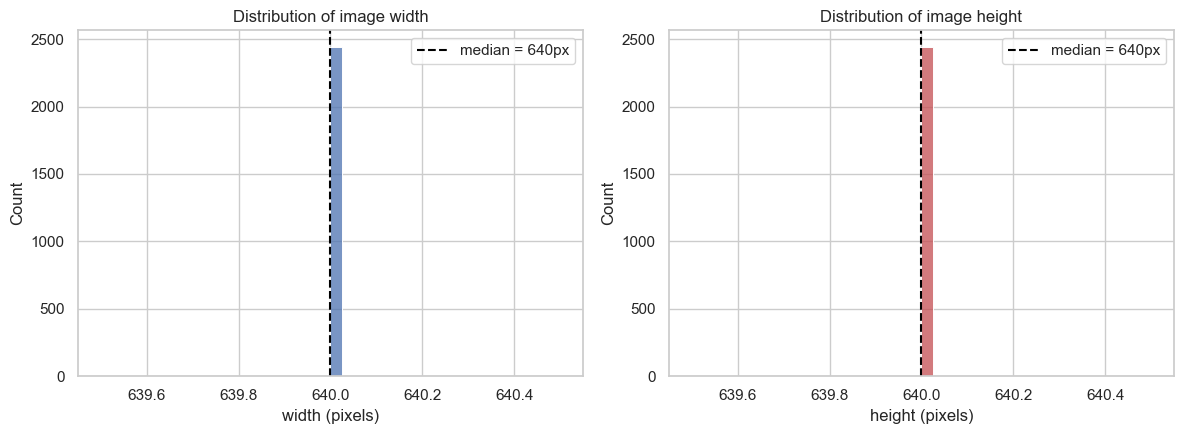

Distinct resolutions: 1 | most common: 640x640 (2,443 images)


In [17]:
# Chart - 4 visualization code
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, color in zip(axes, ["width", "height"], ["#4C72B0", "#C44E52"]):
    sns.histplot(df[col], bins=40, kde=df[col].nunique() > 5, color=color, ax=ax)
    ax.axvline(df[col].median(), color="black", ls="--", label=f"median = {df[col].median():.0f}px")
    ax.set_title(f"Distribution of image {col}"); ax.set_xlabel(f"{col} (pixels)"); ax.legend()
finish_plot("04_width_height_hist")
print(f"Distinct resolutions: {df['resolution'].nunique()} | most common: {df['resolution'].value_counts().idxmax()} "
      f"({df['resolution'].value_counts().max():,} images)")

##### 1. Why did you pick the specific chart?

Histograms show the **distribution of a numeric variable**. Width and height tell us whether the raw images already share one size or whether resizing will distort some of them.

##### 2. What is/are the insight(s) found from the chart?

The spread of the histograms and the number of distinct resolutions (printed below the chart) show how consistent the image sizes are. Several peaks mean several scanners / export settings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies the resize-to-224x224 step and warns us about extreme sizes. **Negative risk:** if one class was exported at a different resolution than another, the network could learn the *resolution* instead of the *tumour* (shortcut learning) - this is checked again in charts 10 and 11.

#### Chart - 5 : File size distribution (histogram + KDE)

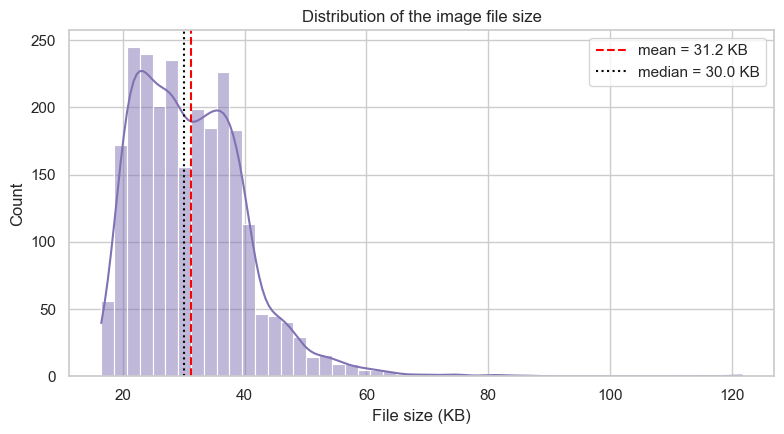

File size: min 16.4 KB | max 121.7 KB | skewness 1.37


In [18]:
# Chart - 5 visualization code
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["file_kb"], bins=50, kde=df["file_kb"].nunique() > 5, color="#8172B3", ax=ax)
ax.axvline(df["file_kb"].mean(), color="red", ls="--", label=f"mean = {df['file_kb'].mean():.1f} KB")
ax.axvline(df["file_kb"].median(), color="black", ls=":", label=f"median = {df['file_kb'].median():.1f} KB")
ax.set_title("Distribution of the image file size"); ax.set_xlabel("File size (KB)"); ax.legend()
finish_plot("05_file_size_hist")
print(f"File size: min {df['file_kb'].min():.1f} KB | max {df['file_kb'].max():.1f} KB | skewness {df['file_kb'].skew():.2f}")

##### 1. Why did you pick the specific chart?

File size is a rough proxy for **image detail / compression**. A histogram with a KDE curve shows the shape (skew, outliers) of this numeric variable.

##### 2. What is/are the insight(s) found from the chart?

A right-skewed shape (mean > median) means that a few images are much larger than the rest; very small files can indicate low-detail or heavily compressed images.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** helps decide the storage and bandwidth needs for deployment and flags suspicious files. **Negative risk:** extremely small or large files might be low-quality scans; the model could be less reliable on such inputs, so the app should warn users about poor-quality uploads.

#### Chart - 6 : Mean brightness distribution (histogram)

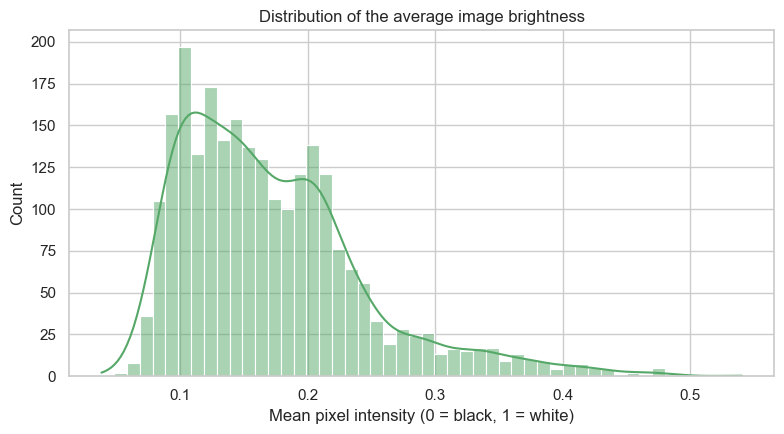

Mean brightness: average 0.172, std 0.073, range 0.038 - 0.540


In [19]:
# Chart - 6 visualization code
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["mean_intensity"], bins=50, kde=df["mean_intensity"].nunique() > 5, color="#55A868", ax=ax)
ax.set_title("Distribution of the average image brightness"); ax.set_xlabel("Mean pixel intensity (0 = black, 1 = white)")
finish_plot("06_mean_intensity_hist")
print(f"Mean brightness: average {df['mean_intensity'].mean():.3f}, std {df['mean_intensity'].std():.3f}, "
      f"range {df['mean_intensity'].min():.3f} - {df['mean_intensity'].max():.3f}")

##### 1. Why did you pick the specific chart?

Brightness is the simplest summary of how a scan looks. A histogram shows whether the scans are exposed consistently, which affects whether pixel normalisation is enough or contrast augmentation is needed.

##### 2. What is/are the insight(s) found from the chart?

The printed range and the width of the histogram show how much brightness varies between scans (different scanners, windowing, sequences).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a wide brightness range supports the use of brightness / contrast augmentation so the model generalises across scanners in different hospitals. **Negative risk:** a model trained on a narrow brightness range may fail on scans from a new hospital with a different calibration.

#### Chart - 7 : Class vs. split (grouped bar - categorical vs categorical)

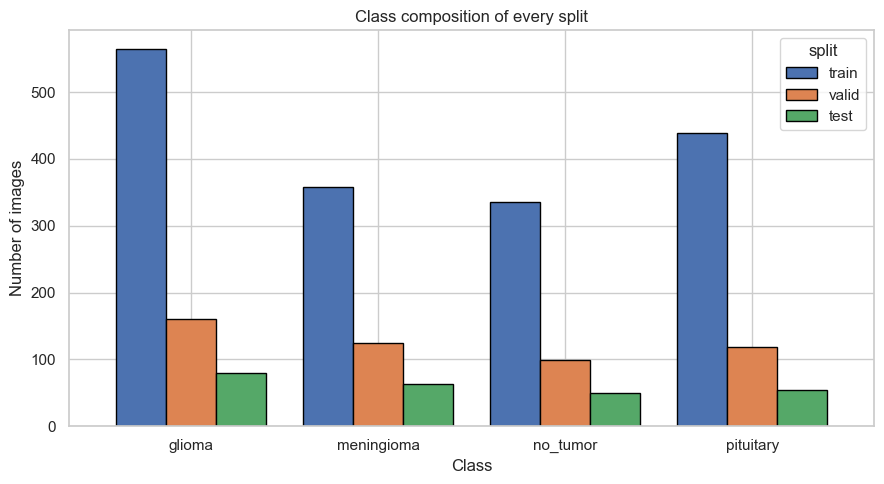

Class share (%) inside every split:


split,train,valid,test
label,,,
glioma,33.3,32.1,32.5
meningioma,21.1,24.7,25.6
no_tumor,19.8,19.7,19.9
pituitary,25.8,23.5,22.0


In [20]:
# Chart - 7 visualization code
ct = pd.crosstab(df["label"], df["split"]).reindex(columns=["train", "valid", "test"]).fillna(0)
ax = ct.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#DD8452", "#55A868"], edgecolor="black", width=0.8)
ax.set_title("Class composition of every split"); ax.set_xlabel("Class"); ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
finish_plot("07_class_by_split")
share = ct.div(ct.sum(axis=0), axis=1) * 100
print("Class share (%) inside every split:"); display(share.round(1))

##### 1. Why did you pick the specific chart?

A grouped bar chart compares **two categorical variables** (class x split). It verifies that every split contains all classes in similar proportions.

##### 2. What is/are the insight(s) found from the chart?

If the shares inside train / valid / test are almost identical, the split is *stratified* and the test score represents the whole data. Large differences would mean the test set is not representative.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a representative split makes the reported performance trustworthy for business decisions. **Negative risk:** a class that is missing or tiny in the test set would hide poor performance on that tumour type.

#### Chart - 8 : Brightness by class (box plot - numerical vs categorical)

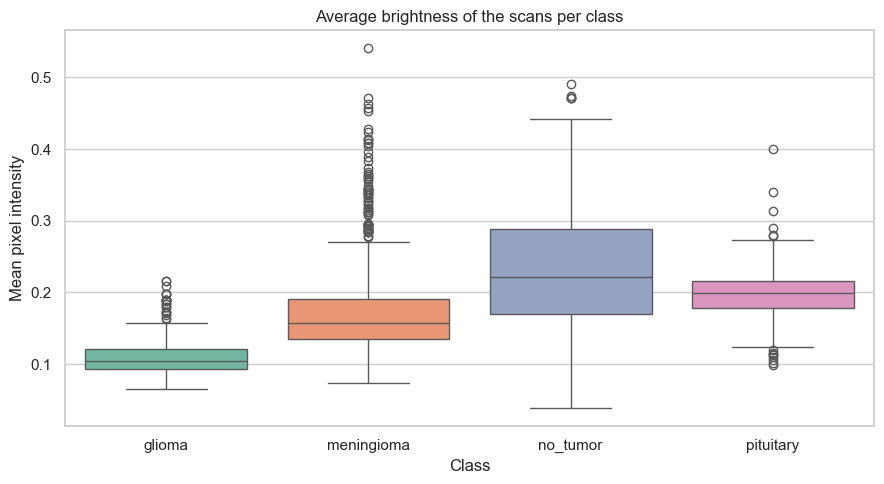

Median brightness per class:
label
glioma        0.104
meningioma    0.157
no_tumor      0.221
pituitary     0.200
Gap between brightest and darkest class median: 0.117


In [21]:
# Chart - 8 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="label", y="mean_intensity", order=class_names, palette=palette, ax=ax)
ax.set_title("Average brightness of the scans per class"); ax.set_xlabel("Class"); ax.set_ylabel("Mean pixel intensity")
finish_plot("08_brightness_by_class")
med = df.groupby("label")["mean_intensity"].median().reindex(class_names)
print("Median brightness per class:"); print(med.round(3).to_string())
print(f"Gap between brightest and darkest class median: {med.max() - med.min():.3f}")

##### 1. Why did you pick the specific chart?

A box plot summarises the **median, spread and outliers** of a numeric variable for every category, which is the standard way to compare numerical vs categorical data.

##### 2. What is/are the insight(s) found from the chart?

If the class medians are noticeably different, brightness alone carries some class information (hypothesis test 1 confirms this statistically). Overlapping boxes mean brightness is not enough to separate the classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** shows which classes differ in appearance and supports augmentation choices. **Negative risk:** if brightness differs strongly between classes because of the scanner and not because of biology, the model may learn a spurious shortcut and fail in other hospitals.

#### Chart - 9 : Contrast by class (violin plot)

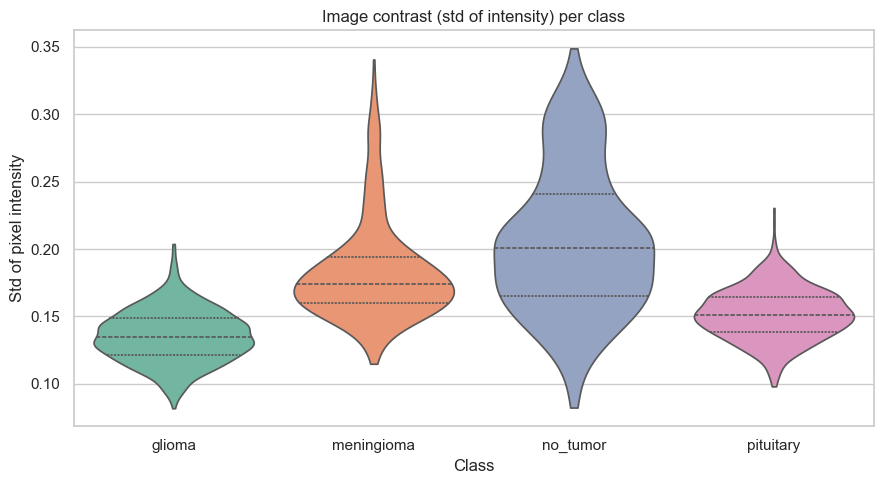

             mean  median    std
label                           
glioma      0.135   0.135  0.019
meningioma  0.183   0.174  0.038
no_tumor    0.206   0.201  0.054
pituitary   0.152   0.151  0.019


In [22]:
# Chart - 9 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=df, x="label", y="std_intensity", order=class_names, palette=palette, cut=0, inner="quartile", ax=ax)
ax.set_title("Image contrast (std of intensity) per class"); ax.set_xlabel("Class"); ax.set_ylabel("Std of pixel intensity")
finish_plot("09_contrast_by_class")
print(df.groupby("label")["std_intensity"].agg(["mean", "median", "std"]).reindex(class_names).round(3))

##### 1. Why did you pick the specific chart?

A violin plot shows the **full shape of the distribution** (not only quartiles), so bimodal or skewed contrast distributions inside a class become visible.

##### 2. What is/are the insight(s) found from the chart?

The width of every violin shows how many scans have a given contrast. Different shapes between classes (e.g. one class with a long tail) show that the classes differ in texture or acquisition.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** texture / contrast differences suggest that CNN filters can find discriminating patterns, supporting the feasibility of the project. **Negative risk:** classes with almost identical distributions are harder to separate and need more data or better models.

#### Chart - 10 : Width vs. height (scatter plot - numerical vs numerical)

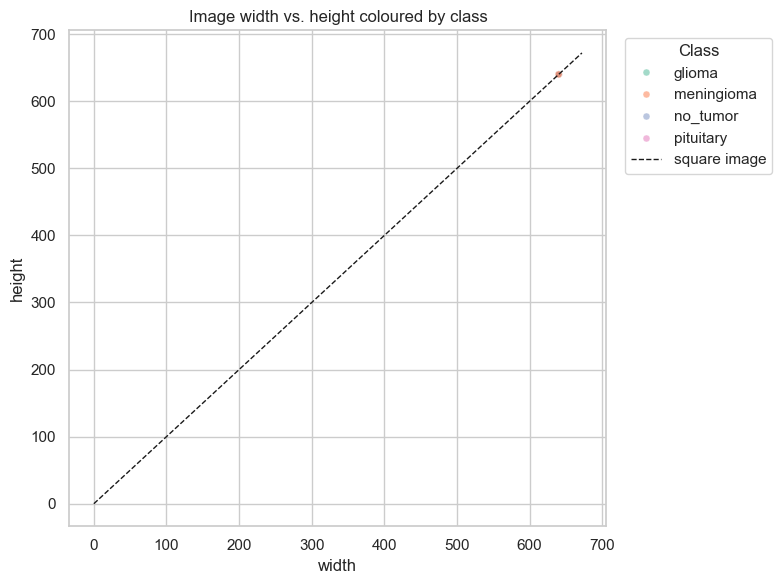

Square images: 100.0% | median aspect ratio 1.00


In [23]:
# Chart - 10 visualization code
sample = df.sample(min(len(df), 3000), random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=sample, x="width", y="height", hue="label", hue_order=class_names, palette=palette, alpha=0.6, s=25, ax=ax)
lim = [0, max(df["width"].max(), df["height"].max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="square image")
ax.set_title("Image width vs. height coloured by class"); ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
finish_plot("10_width_vs_height")
print(f"Square images: {(df['width'] == df['height']).mean():.1%} | median aspect ratio {df['aspect_ratio'].median():.2f}")

##### 1. Why did you pick the specific chart?

A scatter plot shows the **relationship between two numeric variables**. Colouring by class reveals whether a class occupies its own region (a possible acquisition shortcut).

##### 2. What is/are the insight(s) found from the chart?

Points on the dashed diagonal are square images. Clusters of one colour in a separate region would mean that a class was scanned/exported differently from the rest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** if all classes overlap, resizing is safe and the model must rely on anatomy. **Negative risk:** separate clusters would mean the network can 'cheat' by image size; we would then crop / pad consistently before training.

#### Chart - 11 : Most common resolutions by class (stacked bar)

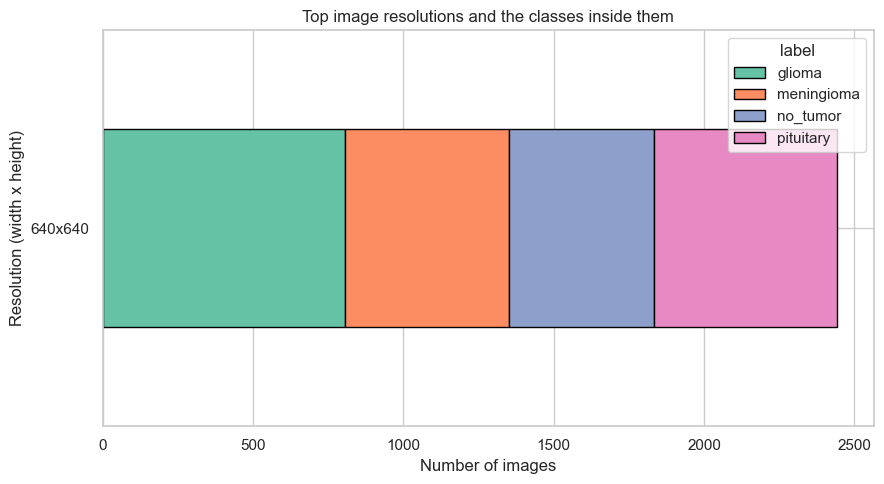

Share of the dominant class inside each top resolution:
resolution
640x640    33.0


In [24]:
# Chart - 11 visualization code
top_res = df["resolution"].value_counts().head(8).index
ct = pd.crosstab(df[df["resolution"].isin(top_res)]["resolution"], df[df["resolution"].isin(top_res)]["label"])
ct = ct.reindex(top_res)[[c for c in class_names if c in ct.columns]]
ax = ct.plot(kind="barh", stacked=True, figsize=(9, 5), color=[palette[c] for c in ct.columns], edgecolor="black")
ax.invert_yaxis(); ax.set_title("Top image resolutions and the classes inside them")
ax.set_xlabel("Number of images"); ax.set_ylabel("Resolution (width x height)")
finish_plot("11_resolution_by_class")
purity = ct.div(ct.sum(axis=1), axis=0).max(axis=1)
print("Share of the dominant class inside each top resolution:"); print((purity * 100).round(1).to_string())

##### 1. Why did you pick the specific chart?

A stacked horizontal bar chart is the best tool to compare **two categorical variables** (resolution x class) when one has long labels such as '512x512'.

##### 2. What is/are the insight(s) found from the chart?

If a resolution is occupied by only one class (100% dominant share), the resolution would leak the label. Mixed bars show that resolution is not a reliable label predictor.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** confirms data quality and tells us whether a standard resize pipeline is fair to all classes. **Negative risk:** purely class-specific resolutions would create a hidden bias that makes lab accuracy look better than real-world accuracy.

#### Chart - 12 : Sample MRI scans of every class (image gallery)

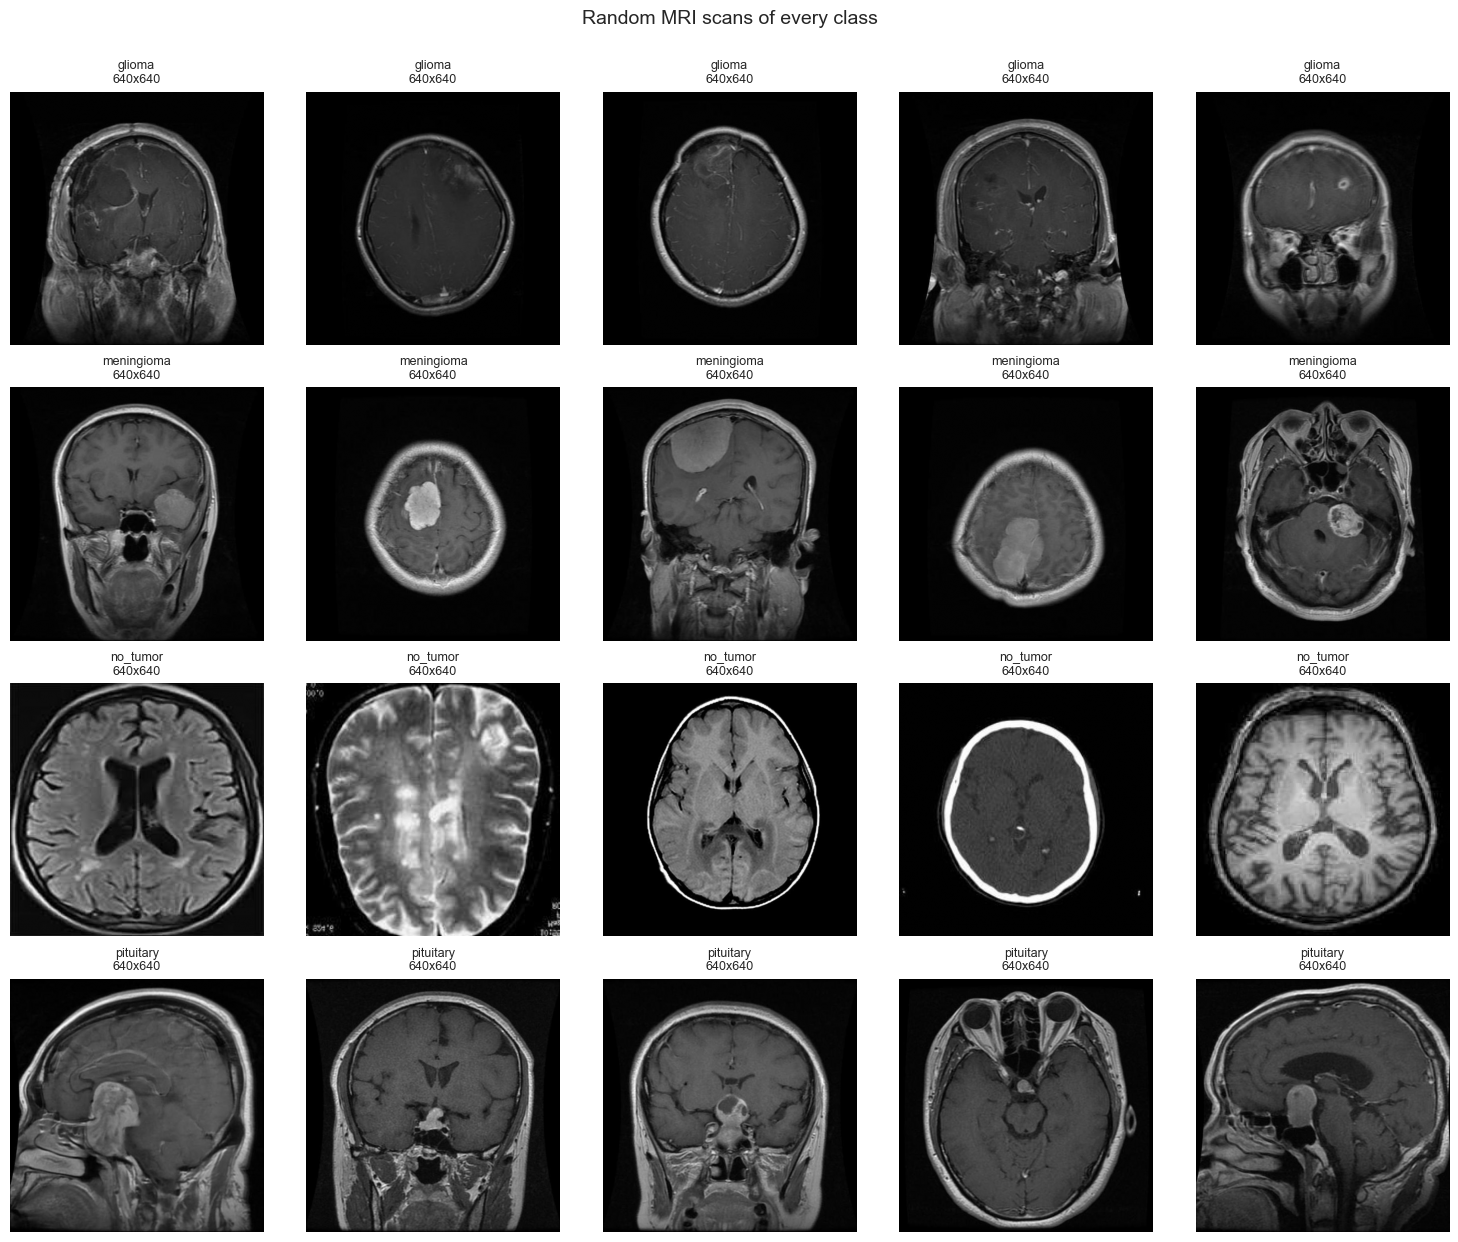

In [25]:
# Chart - 12 visualization code
show_samples(df, n_per_class=5, title="Random MRI scans of every class", save_as="12_sample_scans")

##### 1. Why did you pick the specific chart?

For image data, looking at real examples is the most important sanity check. A gallery with one row per class lets us compare the visual appearance of the classes directly, which no numeric chart can do.

##### 2. What is/are the insight(s) found from the chart?

Scans of the same class differ in head orientation, slice level (axial / sagittal / coronal), zoom and brightness, and the tumour often occupies only a small part of the image. This shows that the task is genuinely visual and that rotation / zoom / shift augmentation is realistic.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** domain experts can quickly confirm the labels look sensible, which builds trust in the data. **Negative risk:** large variation in slice orientation means the model needs enough diverse training data; otherwise performance may drop on unusual views.

#### Chart - 13 : Average scan and pixel-intensity profile per class

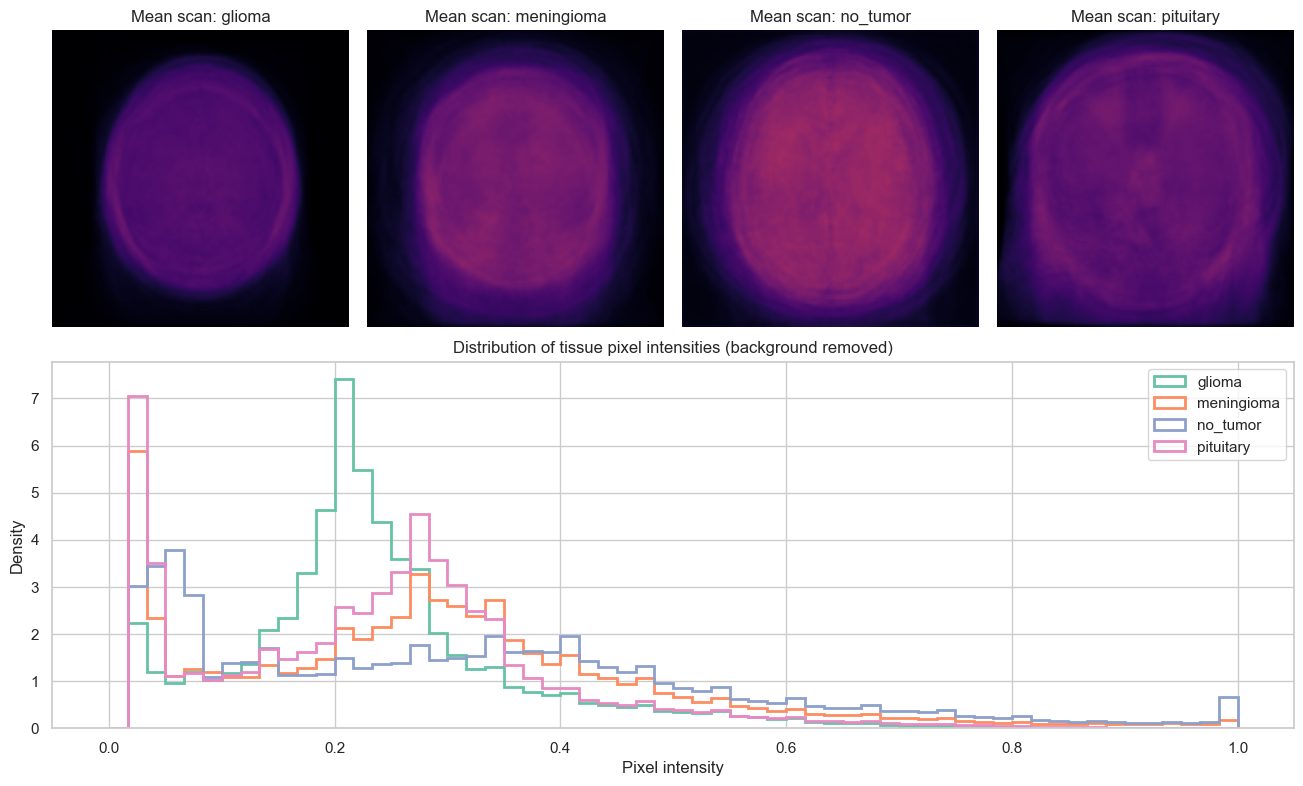

In [26]:
# Chart - 13 visualization code
def load_gray(path, size=(128, 128)):
    """Load an image as a float grayscale array in [0, 1]."""
    with Image.open(path) as im:
        return np.asarray(im.convert("L").resize(size), dtype=np.float32) / 255.0

mean_imgs, pixel_pool = {}, {}
for c in class_names:
    paths = df[df["label"] == c]["filepath"].sample(min(150, (df["label"] == c).sum()), random_state=SEED)
    stack = np.stack([load_gray(p) for p in paths])
    mean_imgs[c] = stack.mean(axis=0)
    pixel_pool[c] = stack[stack > 0.02]                    # ignore the black background

fig = plt.figure(figsize=(3.3 * NUM_CLASSES, 8))
gs = fig.add_gridspec(2, NUM_CLASSES, height_ratios=[1, 1.1])
for i, c in enumerate(class_names):
    ax = fig.add_subplot(gs[0, i]); ax.imshow(mean_imgs[c], cmap="inferno", vmin=0, vmax=1)
    ax.set_title(f"Mean scan: {c}"); ax.axis("off")
ax2 = fig.add_subplot(gs[1, :])
for c in class_names:
    if len(pixel_pool[c]) > 0:
        ax2.hist(pixel_pool[c], bins=60, range=(0, 1), density=True, histtype="step", linewidth=2, label=c, color=palette[c])
ax2.set_title("Distribution of tissue pixel intensities (background removed)")
ax2.set_xlabel("Pixel intensity"); ax2.set_ylabel("Density"); ax2.legend()
finish_plot("13_mean_scan_and_intensity_profile")

##### 1. Why did you pick the specific chart?

The **mean image** of a class (the pixel-wise average of many scans) reveals the typical anatomy and position that the class has, and the **intensity histogram** shows how tissue brightness is distributed. Together they summarise thousands of pixels per class in one picture.

##### 2. What is/are the insight(s) found from the chart?

The mean scans are blurry because the heads are not perfectly aligned, and bright regions show where tissue (and sometimes tumour) is usually located; differences between the mean scans (for example a bright region near the centre for pituitary tumours) show where class-specific information lives. Overlapping intensity curves show that brightness alone does not separate the classes - a CNN must learn shape and texture.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it explains *why* a deep model is needed and which regions matter, which is helpful when communicating with radiologists. **Negative risk:** if mean scans differ because of different image framing instead of pathology, the model might learn framing; occlusion analysis later checks what the model really uses.

#### Chart - 14 - Correlation Heatmap : Correlation heat-map of the numeric image variables

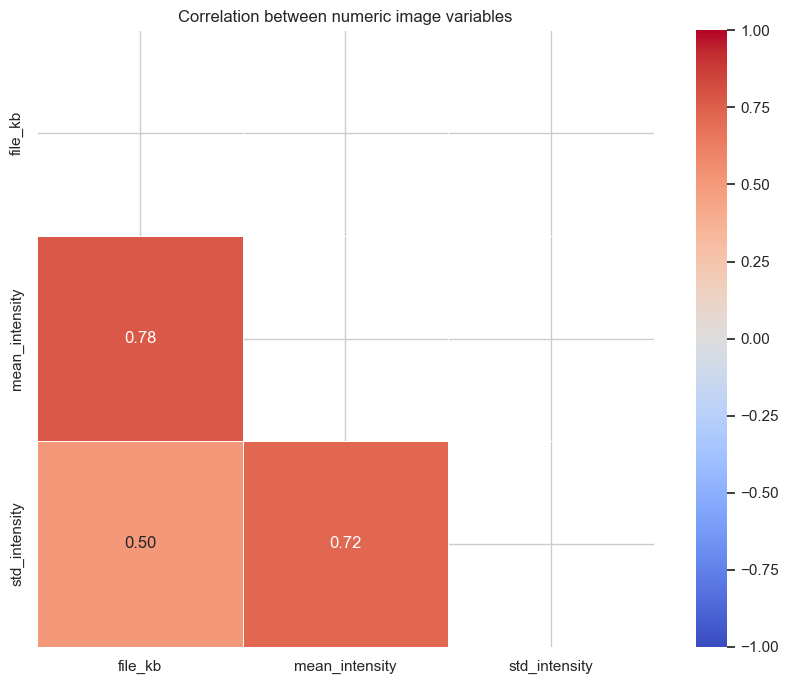

Strongest correlations:
mean_intensity  file_kb           0.779
std_intensity   mean_intensity    0.721
                file_kb           0.502


In [27]:
# Correlation Heatmap visualization code
num_df = df[NUM_COLS]
num_df = num_df.loc[:, num_df.nunique() > 1]                      # constant columns have no correlation
corr = num_df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, square=True, ax=ax)
ax.set_title("Correlation between numeric image variables")
finish_plot("14_correlation_heatmap")
pairs = corr.where(~mask).stack().abs().sort_values(ascending=False)
print("Strongest correlations:"); print(pairs.head(4).round(3).to_string())

##### 1. Why did you pick the specific chart?

A correlation heat-map is the standard **multivariate** tool: it shows the linear relationship between *every pair* of numeric variables at once.

##### 2. What is/are the insight(s) found from the chart?

Width, height and megapixels are mathematically linked and therefore highly correlated; file size usually correlates with image size and contrast. Weak correlations between brightness / contrast and size mean they describe different properties of the image.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** highly redundant variables (width, height, megapixels) do not need to be used together if these metadata were used for a model. **Negative risk:** none for the deep model itself, because the CNN learns directly from pixels - these variables are only used for data-quality analysis.

#### Chart - 15 - Pair Plot : Pair plot of image statistics coloured by class

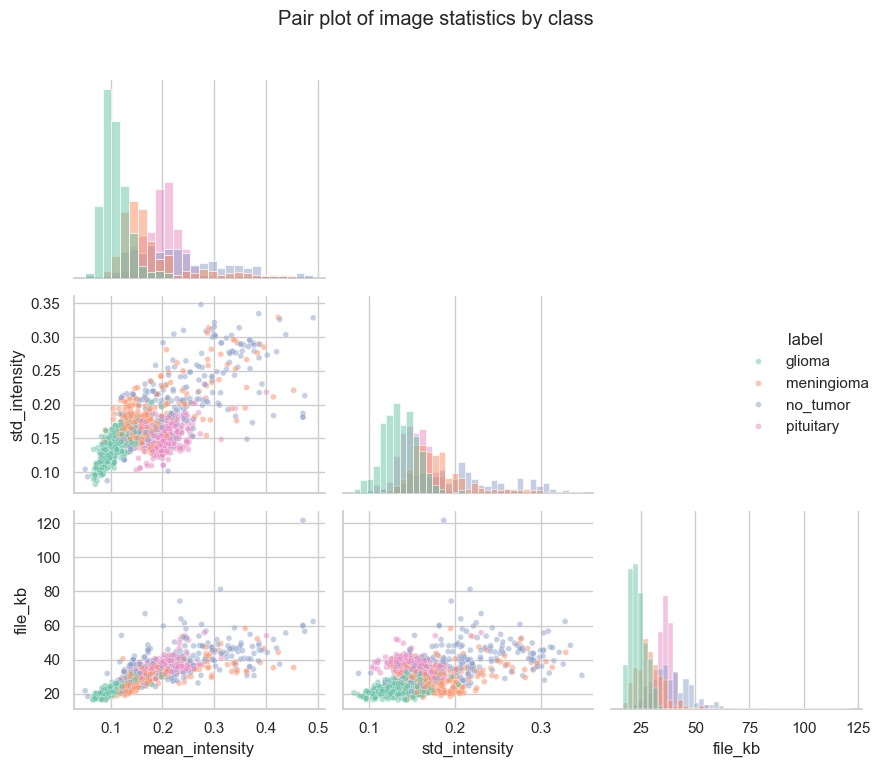

In [28]:
# Pair Plot visualization code
pair_vars = [c for c in ["mean_intensity", "std_intensity", "file_kb", "megapixels"] if df[c].nunique() > 1]
pp_sample = df.sample(min(len(df), 1200), random_state=SEED)
g = sns.pairplot(pp_sample, vars=pair_vars, hue="label", hue_order=class_names, palette=palette,
                 corner=True, diag_kind="hist", plot_kws=dict(alpha=0.5, s=18))
g.fig.suptitle("Pair plot of image statistics by class", y=1.02)
finish_plot("15_pair_plot")

##### 1. Why did you pick the specific chart?

A pair plot shows **all pairwise scatter plots and the distribution of every variable in one figure**, coloured by class - the best multivariate view of whether the classes separate in the simple-statistics space.

##### 2. What is/are the insight(s) found from the chart?

Strongly overlapping colours mean that simple statistics (brightness, contrast, file size) cannot separate the classes. This tells us a classical model on such features would fail and a CNN on raw pixels is needed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies investing in deep learning rather than a simple rule-based approach. **Negative risk:** if one class does separate clearly from the others on these simple statistics, part of the model's accuracy could come from acquisition differences rather than tumour appearance.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

All tests use a significance level of **alpha = 0.05**.

### Hypothetical Statement - 1 : *The average image brightness is the same for all tumour classes.*

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** the distribution of `mean_intensity` is identical in every class.
* **H1:** at least one class has a different `mean_intensity` distribution.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
ALPHA = 0.05
groups = [g["mean_intensity"].values for _, g in df.groupby("label")]

# Normality check on a sample of every class (decides parametric vs. non-parametric test)
normal_flags = []
for g in groups:
    s = np.random.RandomState(SEED).choice(g, size=min(len(g), 500), replace=False)
    normal_flags.append(stats.shapiro(s).pvalue > ALPHA if len(s) >= 3 and np.ptp(s) > 0 else False)
print(f"Classes that look normally distributed (Shapiro-Wilk): {sum(normal_flags)} of {len(groups)}")

h_stat, p_value = stats.kruskal(*groups)
f_stat, p_anova = stats.f_oneway(*groups)
print(f"Kruskal-Wallis H = {h_stat:.3f}, p-value = {p_value:.3e}")
print(f"(One-way ANOVA for reference: F = {f_stat:.3f}, p-value = {p_anova:.3e})")
print("Decision:", "REJECT H0 -> brightness differs between classes" if p_value < ALPHA else "FAIL TO REJECT H0 -> no evidence of a brightness difference")

Classes that look normally distributed (Shapiro-Wilk): 0 of 4
Kruskal-Wallis H = 1415.812, p-value = 1.092e-306
(One-way ANOVA for reference: F = 598.369, p-value = 1.899e-291)
Decision: REJECT H0 -> brightness differs between classes


##### Which statistical test have you done to obtain P-Value?

The **Kruskal-Wallis H-test** (with a one-way ANOVA printed for reference).

##### Why did you choose the specific statistical test?

We compare a numeric variable across **more than two independent groups**, which calls for ANOVA or its non-parametric equivalent. Pixel statistics are often not normally distributed (Shapiro-Wilk check above) and the class sizes differ, so the rank-based Kruskal-Wallis test, which does not assume normality, is the safer choice.

**Business meaning:** a significant result means brightness is not distributed equally across classes - useful for augmentation design, but also a warning that the model might exploit brightness as a shortcut.

### Hypothetical Statement - 2 : *All tumour classes are equally frequent in the dataset.*

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** every class has the same probability (1 / number of classes) - the dataset is balanced.
* **H1:** the classes are not equally frequent - the dataset is imbalanced.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
observed = df["label"].value_counts().reindex(class_names).values
chi2, p_value = stats.chisquare(f_obs=observed)          # expected = equal counts
cramers = np.sqrt(chi2 / (observed.sum() * (NUM_CLASSES - 1)))   # effect size (0 = balanced)
print("Observed counts:", dict(zip(class_names, observed.tolist())))
print(f"Chi-square = {chi2:.2f}, p-value = {p_value:.3e}, effect size (Cramer's V) = {cramers:.3f}")
print("Decision:", "REJECT H0 -> the classes are NOT equally frequent" if p_value < ALPHA else "FAIL TO REJECT H0 -> classes are balanced")

Observed counts: {'glioma': 805, 'meningioma': 545, 'no_tumor': 483, 'pituitary': 610}
Chi-square = 95.58, p-value = 1.384e-20, effect size (Cramer's V) = 0.114
Decision: REJECT H0 -> the classes are NOT equally frequent


##### Which statistical test have you done to obtain P-Value?

The **Chi-square goodness-of-fit test**, plus Cramer's V as an effect size.

##### Why did you choose the specific statistical test?

The variable (class) is categorical and we want to know whether the observed frequencies match a *theoretical* distribution (all classes equal). That is exactly what the goodness-of-fit test does. With thousands of images even small differences become "significant", so the effect size tells us whether the imbalance is practically important.

**Business meaning:** a significant imbalance means we must not rely on accuracy alone and should use class weights and macro-averaged metrics so that no tumour type is under-served.

### Hypothetical Statement - 3 : *Tumour scans have a higher contrast than scans without a tumour.*

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** the contrast (`std_intensity`) of tumour scans is **not greater** than that of no-tumour scans.
* **H1:** tumour scans have a **greater** contrast than no-tumour scans.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
no_tumor_cls = next((c for c in class_names if re.match(r"^(no|normal|healthy)", c)), None)
if no_tumor_cls is None:                                   # fallback: compare the two largest classes
    no_tumor_cls = df["label"].value_counts().index[1]
    print(f"No 'no tumour' class found -> comparing the two largest classes instead ('{no_tumor_cls}' as reference).")

tumor_vals = df.loc[df["label"] != no_tumor_cls, "std_intensity"].values
healthy_vals = df.loc[df["label"] == no_tumor_cls, "std_intensity"].values
u_stat, p_value = stats.mannwhitneyu(tumor_vals, healthy_vals, alternative="greater")
effect = u_stat / (len(tumor_vals) * len(healthy_vals))            # probability of superiority
print(f"Reference class: {no_tumor_cls} | n(tumour) = {len(tumor_vals):,}, n(reference) = {len(healthy_vals):,}")
print(f"Median contrast: tumour = {np.median(tumor_vals):.4f}, reference = {np.median(healthy_vals):.4f}")
print(f"Mann-Whitney U = {u_stat:,.0f}, p-value = {p_value:.3e}, P(tumour contrast > reference) = {effect:.3f}")
print("Decision:", "REJECT H0 -> tumour scans have higher contrast" if p_value < ALPHA else "FAIL TO REJECT H0 -> no evidence of higher contrast")

Reference class: no_tumor | n(tumour) = 1,960, n(reference) = 483
Median contrast: tumour = 0.1502, reference = 0.2006
Mann-Whitney U = 182,865, p-value = 1.000e+00, P(tumour contrast > reference) = 0.193
Decision: FAIL TO REJECT H0 -> no evidence of higher contrast


##### Which statistical test have you done to obtain P-Value?

A one-sided **Mann-Whitney U test** (Wilcoxon rank-sum).

##### Why did you choose the specific statistical test?

We compare a numeric variable between **two independent groups** with unequal sizes, and the contrast values are not guaranteed to be normal, so the non-parametric Mann-Whitney U test is appropriate. The one-sided alternative matches the directional statement ("greater"). The printed probability of superiority shows how large the difference is in practice.

**Business meaning:** if tumour scans are systematically more contrasted, a model could partly rely on this simple signal; it is a reminder to validate the final model on scans from other hospitals before clinical use.

## ***6. Feature Engineering & Data Pre-processing***

For an image-classification CNN the "features" are learned automatically from pixels, so this section adapts the template headings to images: cleaning, label encoding, augmentation (feature manipulation), resizing / scaling, dimensionality reduction (for visualisation), splitting and class-imbalance handling.

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
print("Remaining missing values after wrangling:")
print(df[["filepath", "label", "split"] + NUM_COLS].isnull().sum().to_string())
assert df[["filepath", "label", "split"]].isnull().sum().sum() == 0, "Unexpected missing values"
print("\nNo imputation is needed: unreadable images were removed in Section 3.")

Remaining missing values after wrangling:
filepath          0
label             0
split             0
width             0
height            0
aspect_ratio      0
megapixels        0
file_kb           0
mean_intensity    0
std_intensity     0

No imputation is needed: unreadable images were removed in Section 3.


#### What all missing value imputation techniques have you used and why did you use those techniques?

No numerical imputation was necessary. For images, a "missing value" is a **corrupted or unreadable file**, and it cannot be imputed - it was **dropped** (Section 3) so it cannot crash the training pipeline. Dropping is safe because it affects only a handful of files, if any.

### 2. Handling Outliers

In [33]:
# Handling Outliers & Outlier treatments
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

rows = []
for col in ["megapixels", "aspect_ratio", "file_kb", "mean_intensity"]:
    flag = iqr_outliers(df[col])
    rows.append({"variable": col, "outliers (IQR rule)": int(flag.sum()), "share": f"{flag.mean():.2%}"})
display(pd.DataFrame(rows))

# Treatment: images smaller than 32 px on any side carry almost no information -> remove. All other outliers are kept
# (a very large / bright scan is still a valid scan; resizing and augmentation make the network robust to them).
tiny = (df["width"] < 32) | (df["height"] < 32)
print(f"\nImages smaller than 32 px (removed): {int(tiny.sum())}")
df = df[~tiny].reset_index(drop=True)

,variable,outliers (IQR rule),share
0,megapixels,0,0.00%
1,aspect_ratio,0,0.00%
2,file_kb,37,1.51%
3,mean_intensity,81,3.32%



Images smaller than 32 px (removed): 0


##### What all outlier treatment techniques have you used and why did you use those techniques?

Outliers were **detected with the IQR rule** and only *meaningless* ones (images smaller than 32 pixels) were removed. Unusual sizes or brightness values are **kept** because they are real scans, and capping them would destroy medical information; the resize + normalisation + augmentation pipeline already makes the model robust to them.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
label2id = {c: i for i, c in enumerate(class_names)}
id2label = {i: c for c, i in label2id.items()}
df["label_id"] = df["label"].map(label2id).astype(int)
print("Label encoding:", label2id)

Label encoding: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


#### What all categorical encoding techniques have you used & why did you use those techniques?

**Integer (label) encoding** of the target class, used together with `sparse_categorical_crossentropy`. It is memory-efficient, works directly with Keras and class-weights, and avoids building a one-hot matrix. No other categorical columns are used as model input.

### 4. Textual Data Preprocessing
*(Not applicable - this is an image-classification project without text data, so none of the NLP steps - contraction expansion, lower-casing, punctuation / stop-word removal, tokenisation, lemmatisation, POS tagging, vectorisation - are required.)*

### 4. Feature Manipulation & Selection
#### 1. Feature Manipulation
For images, feature manipulation means **data augmentation**: generating realistic variations (flip, rotation, zoom, shift, contrast, brightness) of the *training* images only. The pipeline below is used later inside the `tf.data` input pipeline.

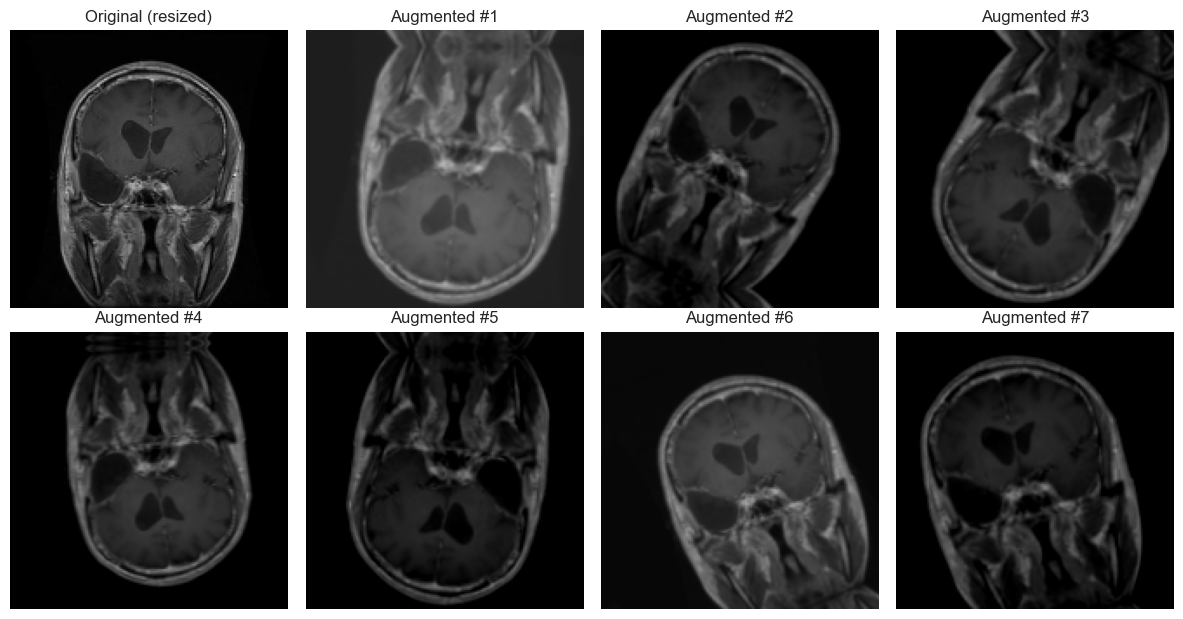

In [35]:
# Manipulate Features to minimize feature correlation and create new features  ->  data augmentation
def build_augmenter():
    """Random transformations applied to TRAINING batches only (validation / test images stay untouched)."""
    ops = [
        layers.RandomFlip("horizontal_and_vertical"),   # flips
        layers.RandomRotation(0.08),                      # +-29 degrees
        layers.RandomZoom(0.15),                          # zoom in / out by up to 15 %
        layers.RandomTranslation(0.08, 0.08),             # shifts by up to 8 %
        layers.RandomContrast(0.15),                      # contrast jitter
    ]
    if hasattr(layers, "RandomBrightness"):               # brightness jitter (TF >= 2.9)
        ops.append(layers.RandomBrightness(0.15, value_range=(0.0, 1.0)))
    return keras.Sequential(ops, name="augmentation")

augmenter = build_augmenter()

# ---- identical pre-processing for training, evaluation and the Streamlit app ----
def preprocess_bytes(raw):
    """raw file bytes -> float32 RGB tensor (224, 224, 3) scaled to [0, 1]."""
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # grayscale -> RGB automatically
    img = tf.image.resize(img, IMG_SIZE)                                 # consistent input shape
    return tf.cast(img, tf.float32) / 255.0                              # normalise to 0-1

# ---- preview: original vs. augmented versions of one training image ----
demo_path = df[df["split"] == "train"].iloc[0]["filepath"]
demo_img = preprocess_bytes(tf.io.read_file(demo_path)).numpy()
aug_batch = augmenter(tf.repeat(demo_img[None], 7, axis=0), training=True).numpy().clip(0, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.3))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(demo_img if i == 0 else aug_batch[i - 1]); ax.axis("off")
    ax.set_title("Original (resized)" if i == 0 else f"Augmented #{i}")
finish_plot("16_augmentation_preview")

#### 2. Feature Selection
CNNs learn their own features from the raw pixels, so no manual feature selection is needed. Over-fitting is controlled with augmentation, dropout, batch-normalisation, L2 weight decay, early stopping and (for transfer learning) frozen pretrained layers.

##### What all feature selection methods have you used and why?

None manually - **the convolution filters are the learned feature extractors**. Regularisation (dropout, L2, early stopping) plays the role of feature selection by preventing the model from memorising noise.

##### Which all features you found important and why?

The occlusion-sensitivity analysis in Section 7 shows which *image regions* the final model finds important (it should focus on the tumour area, not on the borders or on text labels).

### 5. Data Transformation
#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. Neural networks need **one fixed input shape**, so every image is (1) decoded and converted to **3-channel RGB** (pretrained ImageNet models require 3 channels), (2) **resized to 224 x 224** and (3) **cast to float32**. The function `preprocess_bytes` above does this, and it is the *same* function used by the Streamlit app, so there is no training/serving mismatch.

### 6. Data Scaling

In [36]:
# Scaling your data  -> pixel values 0-255  ->  0-1  (done inside preprocess_bytes); verify on a real image
print(f"Before scaling: raw pixel range 0 - 255 | After scaling: min = {demo_img.min():.3f}, max = {demo_img.max():.3f}, "
      f"dtype = {demo_img.dtype}, shape = {demo_img.shape}")
assert 0.0 <= demo_img.min() and demo_img.max() <= 1.0

Before scaling: raw pixel range 0 - 255 | After scaling: min = 0.000, max = 0.962, dtype = float32, shape = (160, 160, 3)


##### Which method have you used to scale you data and why?

**Min-max scaling by dividing by 255** (range 0-1), as required by the project. It makes optimisation stable and fast. The transfer-learning models contain a small `Rescaling` layer that converts the 0-1 input to the range their backbone was pre-trained with (e.g. -1..1 for MobileNetV2), so the *same* 0-1 input works for every model.

### 7. Dimesionality Reduction
##### Do you think that dimensionality reduction is needed? Explain Why?

Not for training - convolutional layers already reduce the dimensionality through pooling. But a **PCA projection** is a useful *visual diagnostic*: it shows how separable the classes are in raw pixel space.

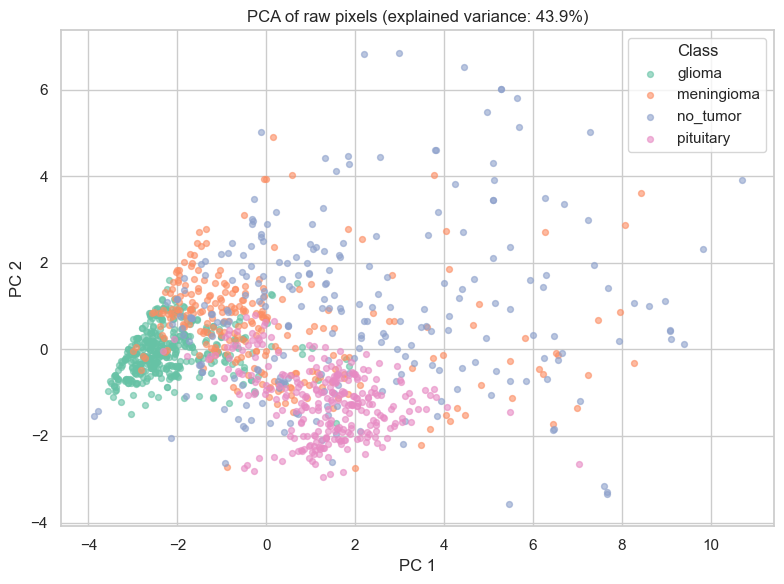

2 components explain 43.9% of the variance; 167 of 1024 components are needed for 95%.


In [37]:
# DImensionality Reduction (If needed)  -> PCA of down-sampled grayscale scans
pca_sample = df.sample(min(len(df), 1200), random_state=SEED)
X_small = np.stack([load_gray(p, size=(32, 32)).ravel() for p in pca_sample["filepath"]])
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_small)
n95 = PCA(n_components=0.95, random_state=SEED).fit(X_small).n_components_

fig, ax = plt.subplots(figsize=(8, 6))
for c in class_names:
    m = (pca_sample["label"] == c).values
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=18, alpha=0.6, label=c, color=palette[c])
ax.set_title(f"PCA of raw pixels (explained variance: {pca.explained_variance_ratio_.sum():.1%})")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(title="Class")
finish_plot("17_pca_projection")
print(f"2 components explain {pca.explained_variance_ratio_.sum():.1%} of the variance; {n95} of {X_small.shape[1]} components are needed for 95%.")

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**PCA** (linear, fast, deterministic) on 32x32 grayscale versions of a sample of the scans, for visualisation only. The strongly overlapping clouds show that the classes are **not linearly separable in pixel space**, which confirms that a non-linear deep model is required.

### 8. Data Splitting

In [38]:
# Split your data to train and test. Choose Splitting ratio wisely.
df = df.reset_index(drop=True)
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "valid"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)
total = len(df)
print(f"Train: {len(train_df):,} ({len(train_df) / total:.1%}) | Validation: {len(val_df):,} ({len(val_df) / total:.1%}) | Test: {len(test_df):,} ({len(test_df) / total:.1%})")
assert len(train_df) > 0 and len(val_df) > 0 and len(test_df) > 0, "One of the splits is empty"
assert set(train_df["md5"]).isdisjoint(test_df["md5"]) or not REMOVE_DUPLICATES, "Leakage between train and test!"
print("Classes per split:", {n: d["label"].nunique() for n, d in [("train", train_df), ("valid", val_df), ("test", test_df)]})

Train: 1,695 (69.4%) | Validation: 502 (20.5%) | Test: 246 (10.1%)
Classes per split: {'train': 4, 'valid': 4, 'test': 4}


##### What data splitting ratio have you used and why?

The dataset's **official split is kept when it exists** (this makes results comparable with other work); otherwise a **stratified 70 / 15 / 15** split is created. *Train* is used to learn, *validation* to stop training and choose between models, and the *test* set is touched only once for the final, unbiased report. Leakage between splits was removed in Section 3 and is asserted above.

### 9. Handling Imbalanced Dataset
##### Do you think the dataset is imbalanced? Explain Why.

See chart 1 and hypothesis 2: if the imbalance ratio is clearly above 1 (and the Chi-square test is significant), the dataset is imbalanced, because some tumour types are photographed / diagnosed more often than others. A model could then reach high accuracy by favouring the large classes.

In [39]:
# Handling Imbalanced Dataset (If needed)  -> class weights computed on the TRAINING set only
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label_id"].values)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
train_counts = train_df["label"].value_counts().reindex(class_names)
print(f"Training imbalance ratio (max/min): {train_counts.max() / train_counts.min():.2f}")
display(pd.DataFrame({"train images": train_counts.values, "class weight": [round(CLASS_WEIGHTS[i], 3) for i in range(NUM_CLASSES)]},
                     index=class_names))

Training imbalance ratio (max/min): 1.68


,train images,class weight
glioma,564,0.751
meningioma,358,1.184
no_tumor,335,1.265
pituitary,438,0.967


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**Class weights** (`balanced` heuristic: `n_samples / (n_classes x n_class_samples)`) inside the loss function. Rare classes get a larger weight, so mistakes on them cost more. We chose this over over-sampling / SMOTE because it adds no duplicated images (no over-fitting risk), needs no extra memory and works naturally with augmentation. Macro-averaged precision / recall / F1 are used for evaluation so that every class counts equally.

#### Building the input pipelines (`tf.data`)

In [40]:
# Build the tf.data input pipelines (read -> decode -> resize -> scale -> [augment] -> batch -> prefetch)
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(path, label):
    return preprocess_bytes(tf.io.read_file(path)), label

def make_dataset(frame, training=False):
    """Training set: shuffled + augmented. Validation / test: fixed order, no augmentation."""
    ds = tf.data.Dataset.from_tensor_slices((frame["filepath"].astype(str).tolist(), frame["label_id"].to_numpy(dtype="int32")))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (tf.clip_by_value(augmenter(x, training=True), 0.0, 1.0), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

xb, yb = next(iter(train_ds))
print("One training batch  ->  images:", xb.shape, xb.dtype, f"| value range [{float(tf.reduce_min(xb)):.2f}, {float(tf.reduce_max(xb)):.2f}]", "| labels:", yb.shape)

One training batch  ->  images: (32, 160, 160, 3) <dtype: 'float32'> | value range [0.00, 1.00] | labels: (32,)


## ***7. ML Model Implementation***

Four models are built, trained, tuned and compared:

| # | Model | Idea |
|---|---|---|
| 1 | **Custom CNN** | Built from scratch: 4 double-conv blocks + batch-norm + progressive dropout + L2; tuned with random search |
| 2 | **MobileNetV2** | Light-weight ImageNet backbone (fast, small) |
| 3 | **EfficientNetB0** | Compound-scaled ImageNet backbone (accuracy / efficiency balance) |
| 4 | **ResNet50** | Deep residual ImageNet backbone (strong, heavier) |

For the transfer-learning models, *Stage 1* trains only a new classification head on top of the frozen backbone and *Stage 2* **fine-tunes** the top backbone layers with a 100x smaller learning rate. "Before vs. after" of each tuning step is reported, as the template requires.

### 7.0 Model-building, training and evaluation utilities

In [41]:
# ----------------------------------------------------------------------------------------------
#  Registries that collect everything we train
# ----------------------------------------------------------------------------------------------
RESULTS    = {}     # tag -> metrics of every evaluated model variant
HISTORIES  = {}     # tag -> Keras training history
FINAL      = {}     # architecture -> the variant that is kept (model, metrics, saved file)
TL_MODELS  = {}     # transfer-learning model objects
PRETRAINED_OK = {}  # did the ImageNet weights load?
METRIC_KEYS   = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
METRIC_LABELS = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]

# ----------------------------------------------------------------------------------------------
#  Architectures
# ----------------------------------------------------------------------------------------------
def build_custom_cnn(num_classes, input_shape=IMG_SHAPE, filters=(32, 64, 128, 256), dropout=0.5, l2=1e-4, name="Custom_CNN"):
    """CNN from scratch: [Conv-BN-ReLU] x2 -> MaxPool -> Dropout per block, then GAP -> Dense -> Dropout -> Softmax."""
    reg = keras.regularizers.l2(l2)
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = inputs
    for i, f in enumerate(filters):
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.10 + 0.05 * i)(x)                 # progressive dropout (0.10 ... 0.25)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, use_bias=False, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=name)

# (keras application builder, (scale, offset) that maps our [0,1] input to the range the backbone was pre-trained on)
BACKBONES = {
    "MobileNetV2":    (keras.applications.MobileNetV2,    (2.0, -1.0)),      # expects [-1, 1]
    "EfficientNetB0": (keras.applications.EfficientNetB0, (255.0, 0.0)),     # expects [0, 255] (has its own normalisation)
    "ResNet50":       (keras.applications.ResNet50,       (255.0, -115.0)),  # expects mean-centred [0, 255]
}

def build_transfer_model(backbone_name, num_classes, dropout=0.4, dense_units=256):
    """Pretrained backbone (frozen) + new classification head."""
    builder, (scale, offset) = BACKBONES[backbone_name]
    try:
        base = builder(include_top=False, weights="imagenet", input_shape=IMG_SHAPE)
        PRETRAINED_OK[backbone_name] = True
    except Exception as exc:                                     # e.g. no internet to download the weights
        print(f"[warning] ImageNet weights for {backbone_name} could not be loaded ({exc}).")
        print("          -> using random initialisation and training the whole network instead.")
        base = builder(include_top=False, weights=None, input_shape=IMG_SHAPE)
        PRETRAINED_OK[backbone_name] = False
    base.trainable = not PRETRAINED_OK[backbone_name]            # frozen when pretrained
    inputs = keras.Input(shape=IMG_SHAPE, name="input_image")
    x = layers.Rescaling(scale, offset=offset, name="to_backbone_range")(inputs)
    x = base(x, training=False)                                  # keep batch-norm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=f"{backbone_name}_transfer")

def unfreeze_top_layers(model, n_layers):
    """Fine-tuning: make the last `n_layers` of the backbone trainable (batch-norm layers stay frozen)."""
    base = next(l for l in model.layers if isinstance(l, keras.Model))
    base.trainable = True
    for l in base.layers[:-n_layers]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    return base

def trainable_params(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

# ----------------------------------------------------------------------------------------------
#  Training
# ----------------------------------------------------------------------------------------------
def compile_model(model, lr):
    model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def get_callbacks(tag, patience):
    """EarlyStopping + ModelCheckpoint (best val_loss) + ReduceLROnPlateau."""
    ckpt = CKPT_DIR / f"{tag}.weights.h5"
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
           callbacks.ModelCheckpoint(filepath=str(ckpt), monitor="val_loss", save_best_only=True,
                                     save_weights_only=True, verbose=0),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1)]
    return cbs, ckpt

def fit_model(model, tag, epochs, lr, patience=4):
    """Compile + train; afterwards the best checkpoint is restored. Returns (history dict, seconds)."""
    compile_model(model, lr)
    cbs, ckpt = get_callbacks(tag, patience)
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=CLASS_WEIGHTS,
                     callbacks=cbs, verbose=2)
    secs = time.time() - t0
    if ckpt.exists():
        try:
            model.load_weights(str(ckpt))                         # guarantee we keep the best epoch
        except Exception as exc:
            print("  (could not reload checkpoint:", exc, ")")
    print(f"  finished in {secs / 60:.1f} min | best val_loss = {min(hist.history['val_loss']):.4f} "
          f"| best val_accuracy = {max(hist.history['val_accuracy']):.4f}")
    return hist.history, secs

def merge_hist(*hists):
    out = {}
    for h in hists:
        for k, v in h.items():
            out.setdefault(k, []).extend(v)
    return out

# ----------------------------------------------------------------------------------------------
#  Evaluation
# ----------------------------------------------------------------------------------------------
BENCH_X = np.concatenate([x.numpy() for x, _ in test_ds.take(2)])[:64]      # fixed batch for fair speed measurement

def benchmark_inference(model, reps=3):
    """Pure model time in milliseconds per image (no disk I/O)."""
    model.predict(BENCH_X[:BATCH_SIZE], verbose=0)                           # warm-up
    t0 = time.time()
    for _ in range(reps):
        model.predict(BENCH_X, batch_size=BATCH_SIZE, verbose=0)
    return (time.time() - t0) / (reps * len(BENCH_X)) * 1000

def evaluate_model(model, tag, train_secs=None):
    """Validation macro-F1 (used for model SELECTION) + full test-set metrics (used for REPORTING)."""
    labels = list(range(NUM_CLASSES))
    val_pred = model.predict(val_ds, verbose=0).argmax(1)
    val_f1 = f1_score(val_df["label_id"].values, val_pred, average="macro", zero_division=0)

    y_true = test_df["label_id"].values
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = y_prob.argmax(1)
    try:
        p64 = y_prob.astype("float64"); p64 /= p64.sum(axis=1, keepdims=True)
        auc_ovr = roc_auc_score(y_true, p64[:, 1] if NUM_CLASSES == 2 else p64,
                                **({} if NUM_CLASSES == 2 else dict(multi_class="ovr", average="macro", labels=labels)))
    except Exception:
        auc_ovr = float("nan")
    per_class_recall = recall_score(y_true, y_pred, average=None, labels=labels, zero_division=0)
    res = {"model": tag,
           "accuracy": accuracy_score(y_true, y_pred),
           "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
           "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
           "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
           "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
           "roc_auc": auc_ovr,
           "min_class_recall": float(per_class_recall.min()),
           "val_f1_macro": val_f1,
           "inference_ms": benchmark_inference(model),
           "params_m": model.count_params() / 1e6,
           "train_minutes": (train_secs or 0) / 60,
           "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob}
    RESULTS[tag] = res
    print(f"  [{tag}] TEST  accuracy={res['accuracy']:.4f}  precision={res['precision_macro']:.4f}  "
          f"recall={res['recall_macro']:.4f}  F1={res['f1_macro']:.4f}  AUC={res['roc_auc']:.4f} | val-F1={val_f1:.4f}")
    return res

# ----------------------------------------------------------------------------------------------
#  Plots
# ----------------------------------------------------------------------------------------------
def plot_history(hist, title, split_at=None, save_as=None):
    """Training / validation accuracy and loss curves (optional vertical line where fine-tuning starts)."""
    ep = np.arange(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key, name in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        ax.plot(ep, hist[key], "o-", label=f"train {key}")
        ax.plot(ep, hist["val_" + key], "s-", label=f"validation {key}")
        if split_at:
            ax.axvline(split_at + 0.5, color="gray", ls="--", label="fine-tuning starts")
        ax.set_title(f"{title} - {name}"); ax.set_xlabel("Epoch"); ax.set_ylabel(name); ax.legend()
    finish_plot(save_as)

def plot_confusion(res, title=None, save_as=None):
    """Confusion matrix: counts (left) and row-normalised recall (right)."""
    cm = confusion_matrix(res["y_true"], res["y_pred"], labels=list(range(NUM_CLASSES)))
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0], cbar=False)
    axes[0].set_title("Confusion matrix (counts)")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names, ax=axes[1], cbar=False)
    axes[1].set_title("Confusion matrix (row-normalised = recall)")
    for ax in axes:
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    fig.suptitle(title or res["model"], y=1.02, fontsize=13)
    finish_plot(save_as)

def show_report(res, save_as=None):
    print(classification_report(res["y_true"], res["y_pred"], target_names=class_names, digits=4, zero_division=0))
    plot_confusion(res, save_as=save_as)

def plot_metric_scores(tags, title="Evaluation metric score chart", save_as=None):
    """Grouped bars: accuracy / precision / recall / F1 for one or several model variants."""
    data = pd.DataFrame({t: [RESULTS[t][k] for k in METRIC_KEYS] for t in tags}, index=METRIC_LABELS)
    ax = data.plot(kind="bar", figsize=(10, 5), width=0.8, edgecolor="black")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_ylim(max(0.0, float(data.values.min()) - 0.1), 1.03)
    ax.set_title(title); ax.set_ylabel("Score (test set)"); plt.xticks(rotation=0); ax.legend(loc="lower right")
    finish_plot(save_as)

def show_improvement(tag_before, tag_after):
    """Table with the change of every metric after tuning / fine-tuning."""
    rows = []
    for k, lab in zip(METRIC_KEYS + ["roc_auc", "min_class_recall"], METRIC_LABELS + ["ROC-AUC (OvR)", "Worst-class recall"]):
        b, a = RESULTS[tag_before][k], RESULTS[tag_after][k]
        rows.append({"metric": lab, "before": round(b, 4), "after": round(a, 4), "change": f"{a - b:+.4f}"})
    display(pd.DataFrame(rows).set_index("metric"))

# ----------------------------------------------------------------------------------------------
#  Saving
# ----------------------------------------------------------------------------------------------
def save_model_h5(model, name):
    """Save as .h5 (project deliverable); falls back to the native .keras format if h5 saving is not supported."""
    h5 = MODEL_DIR / f"{name}.h5"
    try:
        model.save(str(h5))
        return h5
    except Exception as exc:
        print(f"  .h5 saving failed ({exc}) -> saving in .keras format instead")
        h5.unlink(missing_ok=True)
        kp = MODEL_DIR / f"{name}.keras"
        model.save(str(kp))
        return kp

print("Utilities ready.")

Utilities ready.


### ML Model - 1 : Custom CNN (built from scratch)

**Architecture.** Four blocks of *[Conv 3x3 - BatchNorm - ReLU] x 2 - MaxPool - Dropout* with 32 / 64 / 128 / 256 filters, followed by Global Average Pooling, a 256-unit dense layer with batch-norm and dropout, and a softmax output. Convolutions learn local patterns (edges, textures, blobs), pooling adds translation tolerance, **batch normalisation** stabilises learning, **dropout + L2** fight over-fitting, and Global Average Pooling keeps the parameter count low.

In [42]:
# ML Model - 1 Implementation
cnn_base = build_custom_cnn(NUM_CLASSES, dropout=0.5, l2=1e-4, name="Custom_CNN_baseline")
cnn_base.summary()


Model: "Custom_CNN_baseline"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 160, 160, 3)]     0         
                                                                 
 conv2d (Conv2D)             (None, 160, 160, 32)      864       
                                                                 
 batch_normalization (Batch  (None, 160, 160, 32)      128       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 160, 160, 32)      0         
                                                                 
 conv2d_1 (Conv2D)           (None, 160, 160, 32)      9216      
                                                                 
 batch_normalization_1 (Bat  (None, 160, 160, 32)      128       
 chNormalization)                             

Epoch 1/25


53/53 - 250s - loss: 1.2664 - accuracy: 0.5563 - val_loss: 2.9484 - val_accuracy: 0.3207 - lr: 0.0010 - 250s/epoch - 5s/step
Epoch 2/25
53/53 - 240s - loss: 1.1339 - accuracy: 0.6260 - val_loss: 4.0291 - val_accuracy: 0.3207 - lr: 0.0010 - 240s/epoch - 5s/step
Epoch 3/25

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
53/53 - 242s - loss: 1.1341 - accuracy: 0.6277 - val_loss: 4.5527 - val_accuracy: 0.3207 - lr: 0.0010 - 242s/epoch - 5s/step
Epoch 4/25
53/53 - 240s - loss: 1.0174 - accuracy: 0.6608 - val_loss: 4.8973 - val_accuracy: 0.3207 - lr: 3.0000e-04 - 240s/epoch - 5s/step
Epoch 5/25

Epoch 5: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
53/53 - 241s - loss: 0.9616 - accuracy: 0.6850 - val_loss: 4.1332 - val_accuracy: 0.3207 - lr: 3.0000e-04 - 241s/epoch - 5s/step
Epoch 6/25
53/53 - 241s - loss: 0.8943 - accuracy: 0.7091 - val_loss: 3.7179 - val_accuracy: 0.3227 - lr: 9.0000e-05 - 241s/epoch - 5s/step
Epoch 7/25
Resto

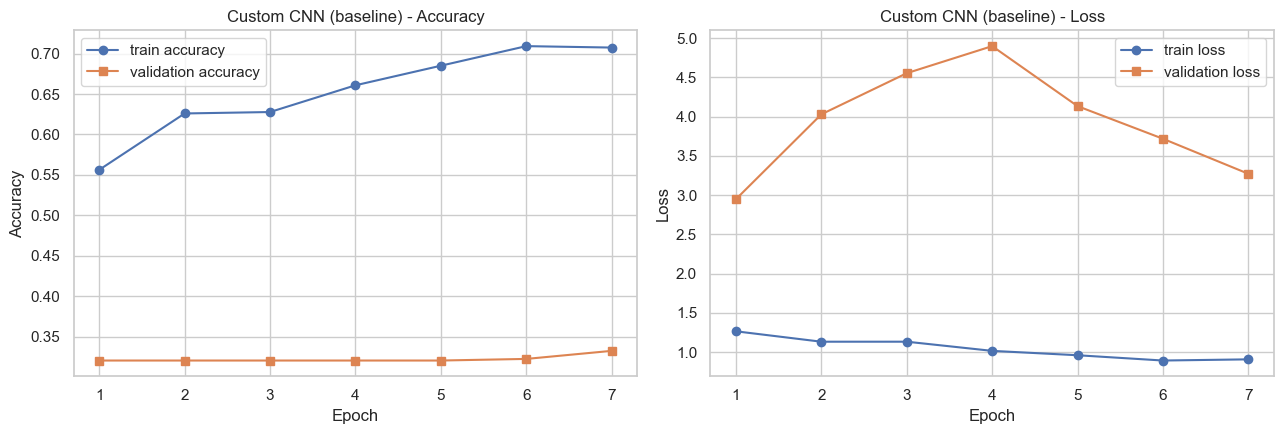

In [43]:
# Fit the Algorithm
hist, secs = fit_model(cnn_base, "custom_cnn_baseline", EPOCHS_CNN, lr=1e-3, patience=6)
HISTORIES["Custom CNN (baseline)"] = hist
plot_history(hist, "Custom CNN (baseline)", save_as="20_custom_cnn_baseline_history")

  [Custom CNN (baseline)] TEST  accuracy=0.3252  precision=0.0813  recall=0.2500  F1=0.1227  AUC=0.6572 | val-F1=0.1214
              precision    recall  f1-score   support

      glioma     0.3252    1.0000    0.4908        80
  meningioma     0.0000    0.0000    0.0000        63
    no_tumor     0.0000    0.0000    0.0000        49
   pituitary     0.0000    0.0000    0.0000        54

    accuracy                         0.3252       246
   macro avg     0.0813    0.2500    0.1227       246
weighted avg     0.1058    0.3252    0.1596       246



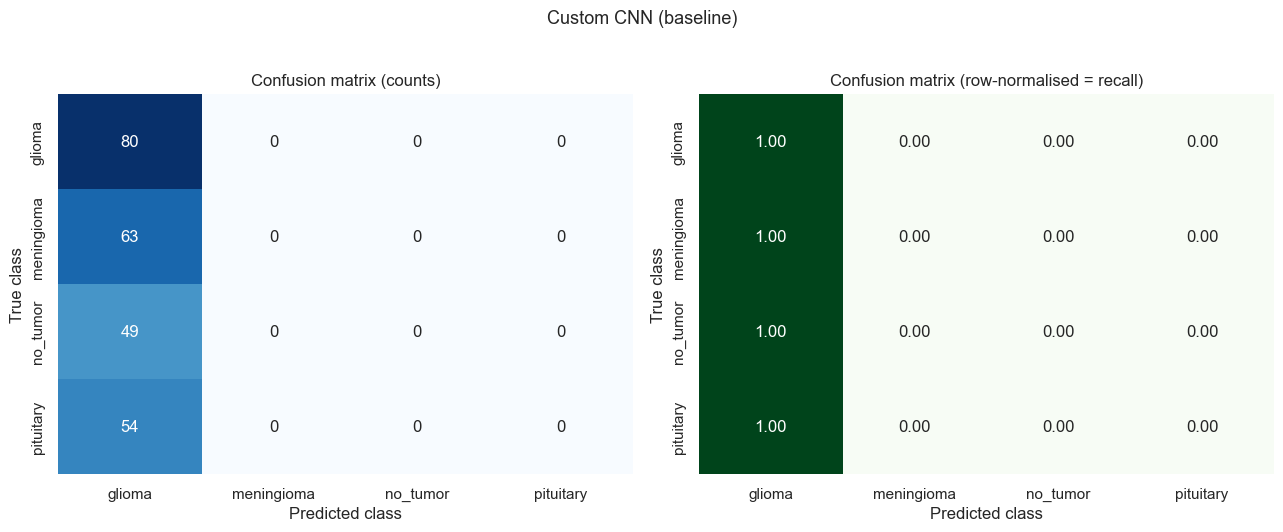

In [44]:
# Predict on the model  (test set - never seen during training or model selection)
res_cnn_base = evaluate_model(cnn_base, "Custom CNN (baseline)", secs)
show_report(res_cnn_base, save_as="21_custom_cnn_baseline_confusion")

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

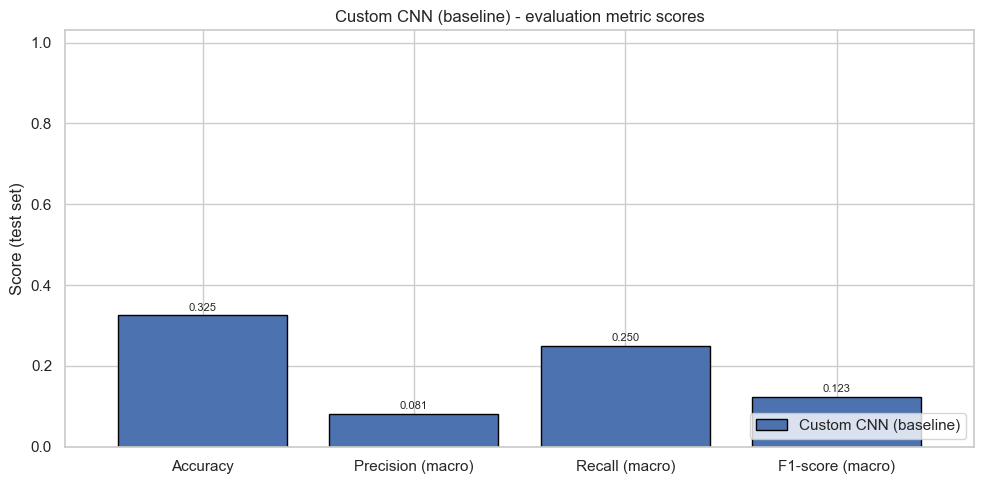

In [45]:
# Visualizing evaluation Metric Score chart
plot_metric_scores(["Custom CNN (baseline)"], "Custom CNN (baseline) - evaluation metric scores", save_as="22_custom_cnn_baseline_scores")

The custom CNN is trained end-to-end with Adam (lr = 1e-3), class-weighted cross-entropy and the three callbacks. The chart shows **accuracy** (overall hit-rate), **macro precision** (when the model says "tumour type X", how often it is right), **macro recall** (how many true cases of each type it finds) and **macro F1** (harmonic mean of both). Because the macro averages treat every class equally, they are not fooled by class imbalance. The training curves above show whether the model over-fits (a growing gap between train and validation curves).

#### 2. Cross- Validation & Hyperparameter Tuning

*Cross-validation note:* a full k-fold cross-validation would mean training this CNN k times, which is impractical for image models. Instead, a dedicated **validation set + early stopping** is used for tuning, and an untouched **test set** for the final estimate - the standard practice for deep learning. The hyper-parameters (learning rate, dropout, L2) are tuned below with a **random search**; every trial is scored on the validation set only.

In [46]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (RandomSearch)
def tune_custom_cnn(n_trials, trial_epochs, seed=SEED):
    """Random search over learning rate, dropout and L2 strength. Each trial trains a fresh CNN for a few epochs."""
    space = {"lr": [1e-3, 5e-4, 2e-4], "dropout": [0.3, 0.5, 0.6], "l2": [1e-5, 1e-4, 1e-3]}
    n_trials = min(n_trials, int(np.prod([len(v) for v in space.values()])))
    rng, seen, rows = random.Random(seed), set(), []
    while len(rows) < n_trials:
        cfg = {k: rng.choice(v) for k, v in space.items()}
        if tuple(cfg.values()) in seen:
            continue
        seen.add(tuple(cfg.values()))
        m = build_custom_cnn(NUM_CLASSES, dropout=cfg["dropout"], l2=cfg["l2"])
        compile_model(m, cfg["lr"])
        h = m.fit(train_ds, validation_data=val_ds, epochs=trial_epochs, class_weight=CLASS_WEIGHTS, verbose=0)
        rows.append({**cfg, "val_accuracy": max(h.history["val_accuracy"]), "val_loss": min(h.history["val_loss"])})
        print(f"  trial {len(rows)}/{n_trials}: {cfg} -> val_accuracy = {rows[-1]['val_accuracy']:.4f}")
        del m; gc.collect()
    return pd.DataFrame(rows).sort_values(["val_accuracy", "val_loss"], ascending=[False, True]).reset_index(drop=True)

cnn_tuned, best_cfg = None, None
if RUN_CNN_TUNING:
    print("Random search ...")
    search_df = tune_custom_cnn(TUNE_TRIALS, TUNE_EPOCHS)
    display(search_df)
    best_cfg = search_df.iloc[0][["lr", "dropout", "l2"]].to_dict()
    print("\nBest configuration:", best_cfg)
else:
    print("RUN_CNN_TUNING = False -> skipped.")

Random search ...
  trial 1/4: {'lr': 0.0002, 'dropout': 0.3, 'l2': 1e-05} -> val_accuracy = 0.3207
  trial 2/4: {'lr': 0.0002, 'dropout': 0.5, 'l2': 1e-05} -> val_accuracy = 0.3207
  trial 3/4: {'lr': 0.001, 'dropout': 0.3, 'l2': 0.001} -> val_accuracy = 0.3207
  trial 4/4: {'lr': 0.001, 'dropout': 0.6, 'l2': 0.001} -> val_accuracy = 0.3207


,lr,dropout,l2,val_accuracy,val_loss
0,0.0002,0.5,0.00001,0.320717,1.545966
1,0.0002,0.3,0.00001,0.320717,1.699669
2,0.0010,0.3,0.00100,0.320717,3.179846
3,0.0010,0.6,0.00100,0.320717,4.644955



Best configuration: {'lr': 0.0002, 'dropout': 0.5, 'l2': 1e-05}


Epoch 1/25
53/53 - 214s - loss: 1.1979 - accuracy: 0.5823 - val_loss: 1.6542 - val_accuracy: 0.3207 - lr: 2.0000e-04 - 214s/epoch - 4s/step
Epoch 2/25
53/53 - 209s - loss: 1.0542 - accuracy: 0.6366 - val_loss: 2.2032 - val_accuracy: 0.3207 - lr: 2.0000e-04 - 209s/epoch - 4s/step
Epoch 3/25

Epoch 3: ReduceLROnPlateau reducing learning rate to 5.999999848427251e-05.
53/53 - 205s - loss: 0.9820 - accuracy: 0.6319 - val_loss: 3.4413 - val_accuracy: 0.3207 - lr: 2.0000e-04 - 205s/epoch - 4s/step
Epoch 4/25
53/53 - 210s - loss: 0.8997 - accuracy: 0.6720 - val_loss: 4.1294 - val_accuracy: 0.3207 - lr: 6.0000e-05 - 210s/epoch - 4s/step
Epoch 5/25

Epoch 5: ReduceLROnPlateau reducing learning rate to 1.7999999545281754e-05.
53/53 - 212s - loss: 0.8665 - accuracy: 0.6897 - val_loss: 3.8577 - val_accuracy: 0.3207 - lr: 6.0000e-05 - 212s/epoch - 4s/step
Epoch 6/25
53/53 - 206s - loss: 0.8194 - accuracy: 0.6973 - val_loss: 3.7198 - val_accuracy: 0.3207 - lr: 1.8000e-05 - 206s/epoch - 4s/step
Epoch

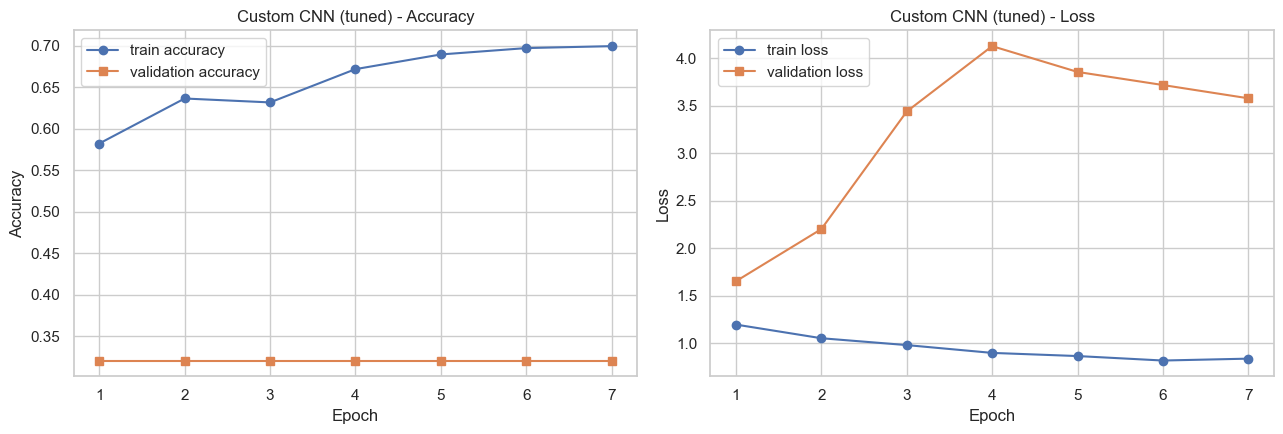

  [Custom CNN (tuned)] TEST  accuracy=0.3252  precision=0.0813  recall=0.2500  F1=0.1227  AUC=0.7705 | val-F1=0.1214
              precision    recall  f1-score   support

      glioma     0.3252    1.0000    0.4908        80
  meningioma     0.0000    0.0000    0.0000        63
    no_tumor     0.0000    0.0000    0.0000        49
   pituitary     0.0000    0.0000    0.0000        54

    accuracy                         0.3252       246
   macro avg     0.0813    0.2500    0.1227       246
weighted avg     0.1058    0.3252    0.1596       246



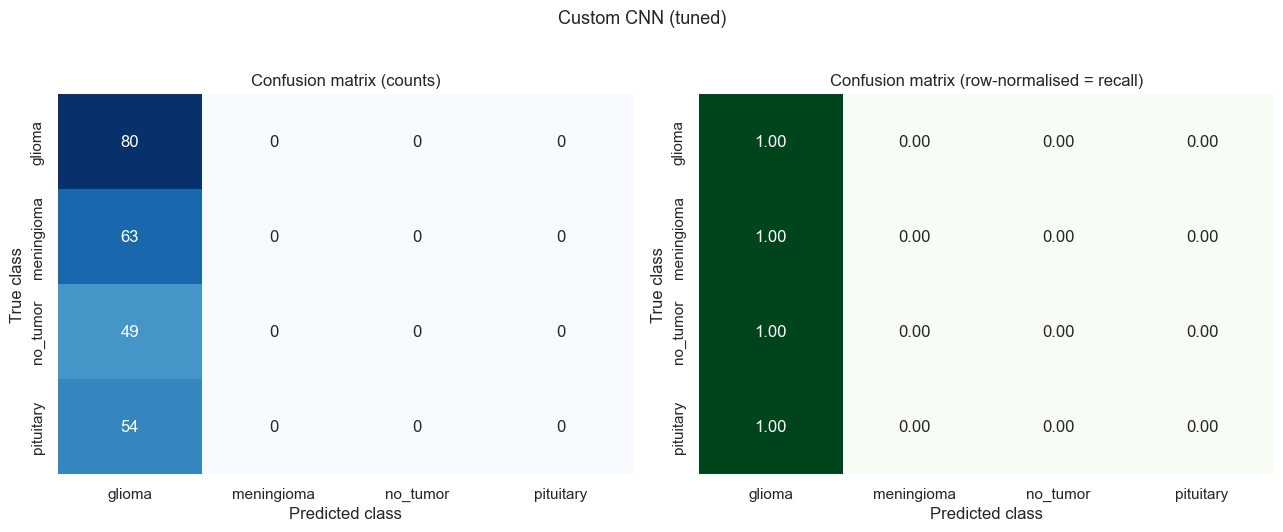

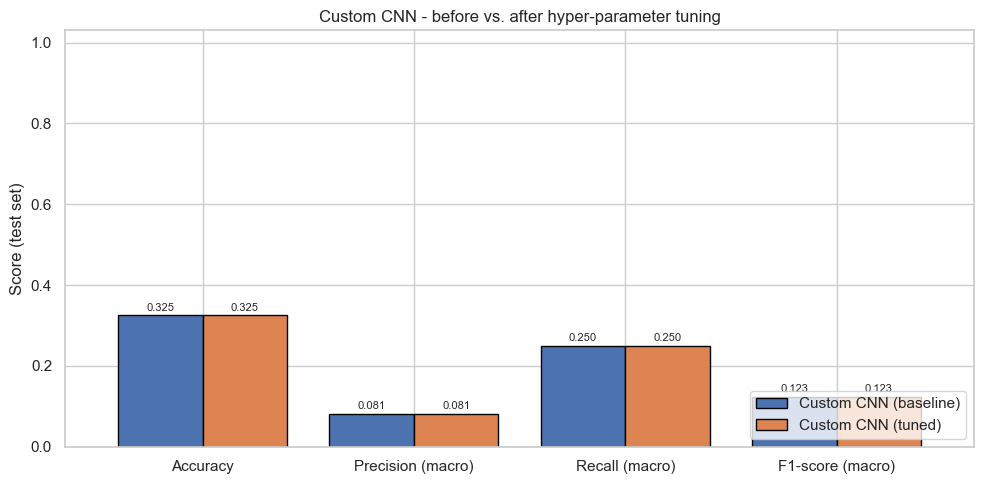

,before,after,change
metric,,,
Accuracy,0.3252,0.3252,+0.0000
Precision (macro),0.0813,0.0813,+0.0000
Recall (macro),0.2500,0.2500,+0.0000
F1-score (macro),0.1227,0.1227,+0.0000
ROC-AUC (OvR),0.6572,0.7705,+0.1134
Worst-class recall,0.0000,0.0000,+0.0000


In [47]:
# Fit the Algorithm (final training with the best hyper-parameters)
# Predict on the model
if best_cfg is not None:
    cnn_tuned = build_custom_cnn(NUM_CLASSES, dropout=float(best_cfg["dropout"]), l2=float(best_cfg["l2"]), name="Custom_CNN_tuned")
    hist, secs_t = fit_model(cnn_tuned, "custom_cnn_tuned", EPOCHS_CNN, lr=float(best_cfg["lr"]), patience=6)
    HISTORIES["Custom CNN (tuned)"] = hist
    plot_history(hist, "Custom CNN (tuned)", save_as="23_custom_cnn_tuned_history")
    res_cnn_tuned = evaluate_model(cnn_tuned, "Custom CNN (tuned)", secs_t)
    show_report(res_cnn_tuned, save_as="24_custom_cnn_tuned_confusion")
    plot_metric_scores(["Custom CNN (baseline)", "Custom CNN (tuned)"], "Custom CNN - before vs. after hyper-parameter tuning",
                       save_as="25_custom_cnn_tuning_comparison")
    show_improvement("Custom CNN (baseline)", "Custom CNN (tuned)")

In [48]:
# Keep the better variant of the custom CNN (selected on VALIDATION macro-F1) and save it as .h5
candidates = [("Custom CNN (baseline)", cnn_base)] + ([("Custom CNN (tuned)", cnn_tuned)] if cnn_tuned is not None else [])
best_tag, best_model_obj = max(candidates, key=lambda t: RESULTS[t[0]]["val_f1_macro"])
path = save_model_h5(best_model_obj, "custom_cnn")
FINAL["Custom CNN"] = {"model": best_model_obj, "result": RESULTS[best_tag], "variant": best_tag, "path": path}
print(f"Kept variant: {best_tag}  ->  {path.name}")

Kept variant: Custom CNN (baseline)  ->  custom_cnn.h5


##### Which hyperparameter optimization technique have you used and why?

**Random search** over learning rate, dropout and L2 strength. With a deep network where one training run takes minutes, an exhaustive grid search would be far too expensive; random search is known to find equally good settings with far fewer trials because it explores more distinct values of the important parameters. Each trial is a short training run scored on the validation set.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

See the *before vs. after* chart and the improvement table above. A positive "change" means tuning helped; a value near zero means the default configuration was already near-optimal (then the validation-based selection simply keeps the better of the two models). With short search runs, small differences are within noise - the table makes that visible instead of hiding it.

### Transfer-learning helper functions
Stage 1 (frozen backbone, new head, lr = 1e-3) and Stage 2 (fine-tune the top backbone layers, lr = 1e-5) are wrapped in two small functions so that the three pretrained models are trained in exactly the same way (a fair comparison).

In [49]:
def stage1_transfer(name):
    """Stage 1: frozen ImageNet backbone, train only the new classification head."""
    model = build_transfer_model(name, NUM_CLASSES)
    print(f"{name}: {model.count_params() / 1e6:.2f} M parameters, {trainable_params(model) / 1e6:.2f} M trainable in stage 1 "
          f"(ImageNet weights loaded: {PRETRAINED_OK[name]})")
    tag = f"{name} (frozen)"
    hist, secs = fit_model(model, f"{name}_stage1", EPOCHS_HEAD, lr=1e-3, patience=4)
    HISTORIES[tag] = hist
    res = evaluate_model(model, tag, secs)
    TL_MODELS[name] = model
    return model, res

def stage2_finetune(name):
    """Stage 2: unfreeze the top backbone layers and continue training with a very small learning rate."""
    model = TL_MODELS[name]
    stage1_secs = RESULTS[f"{name} (frozen)"]["train_minutes"] * 60
    unfreeze_top_layers(model, FT_LAYERS)
    print(f"{name}: fine-tuning the top {FT_LAYERS} backbone layers -> {trainable_params(model) / 1e6:.2f} M trainable parameters")
    tag = f"{name} (fine-tuned)"
    hist, secs = fit_model(model, f"{name}_stage2", EPOCHS_FT, lr=1e-5, patience=4)
    HISTORIES[tag] = hist
    return evaluate_model(model, tag, stage1_secs + secs)

def finalize_transfer(name):
    """Keep the better stage (validation macro-F1), restore its weights if needed and save the model as .h5."""
    model = TL_MODELS[name]
    t1, t2 = f"{name} (frozen)", f"{name} (fine-tuned)"
    if RESULTS[t2]["val_f1_macro"] >= RESULTS[t1]["val_f1_macro"]:
        chosen = t2
    else:
        model.load_weights(str(CKPT_DIR / f"{name}_stage1.weights.h5"))      # fine-tuning did not help -> go back
        chosen = t1
    path = save_model_h5(model, name.lower())
    FINAL[name] = {"model": model, "result": RESULTS[chosen], "variant": chosen, "path": path}
    print(f"Kept variant: {chosen}  ->  {path.name}")

def run_transfer_section(name, number):
    """Complete section for one pretrained model (used by the three cells below)."""
    if name not in MODELS_TO_TRAIN:
        print(f"{name} is not in MODELS_TO_TRAIN -> skipped.")
        return False
    return True

### ML Model - 2 : MobileNetV2 (transfer learning)

MobileNetV2 is a **light-weight** network built from *inverted residual blocks* with depth-wise separable convolutions. It has only ~3.4 M backbone parameters and runs quickly even on CPUs / mobile devices, which makes it the natural candidate for a low-cost, real-time web application.

**Stage 1** keeps the ImageNet weights frozen and trains the new head (GAP - BatchNorm - Dropout - Dense(256) - Dropout - Softmax). **Stage 2** unfreezes the top backbone layers and fine-tunes them with lr = 1e-5 so the pretrained features adapt to MRI texture without being destroyed.

9406464/9406464 [==============================] - 3s 0us/step
MobileNetV2: 2.59 M parameters, 0.33 M trainable in stage 1 (ImageNet weights loaded: True)
Epoch 1/8
53/53 - 31s - loss: 1.1734 - accuracy: 0.6696 - val_loss: 1.0470 - val_accuracy: 0.6554 - lr: 0.0010 - 31s/epoch - 585ms/step
Epoch 2/8
53/53 - 27s - loss: 0.7828 - accuracy: 0.7622 - val_loss: 0.7594 - val_accuracy: 0.7291 - lr: 0.0010 - 27s/epoch - 504ms/step
Epoch 3/8
53/53 - 29s - loss: 0.6326 - accuracy: 0.8035 - val_loss: 0.6209 - val_accuracy: 0.7849 - lr: 0.0010 - 29s/epoch - 546ms/step
Epoch 4/8
53/53 - 29s - loss: 0.5220 - accuracy: 0.8183 - val_loss: 0.5226 - val_accuracy: 0.8187 - lr: 0.0010 - 29s/epoch - 542ms/step
Epoch 5/8
53/53 - 29s - loss: 0.5234 - accuracy: 0.8224 - val_loss: 0.6198 - val_accuracy: 0.7988 - lr: 0.0010 - 29s/epoch - 541ms/step
Epoch 6/8

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
53/53 - 27s - loss: 0.5003 - accuracy: 0.8383 - val_loss: 0.5879 - val_accurac

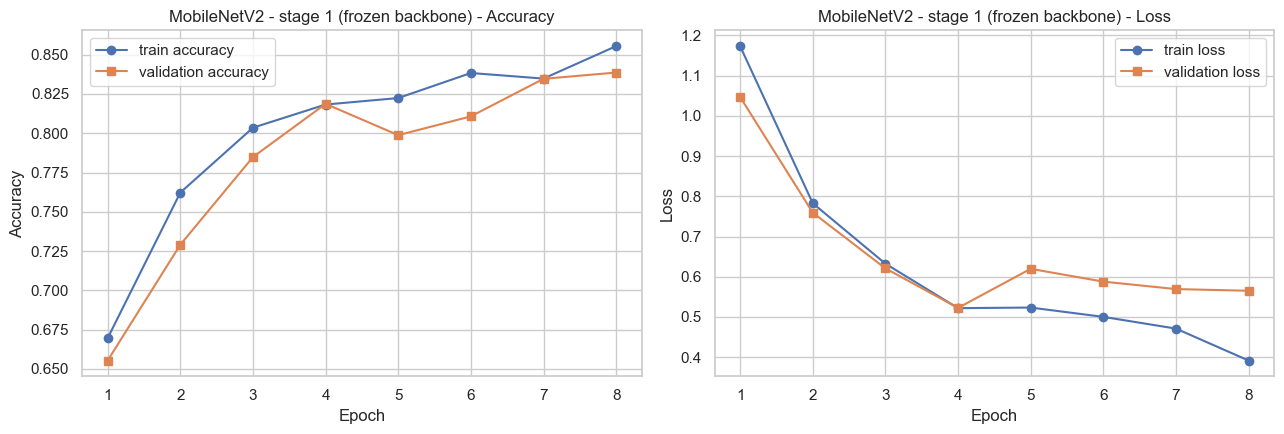

In [50]:
# ML Model - 2 Implementation  (Stage 1 : frozen backbone)
# Fit the Algorithm
# Predict on the model
NAME = "MobileNetV2"
if run_transfer_section(NAME, 2):
    model_mobilenetv2, _ = stage1_transfer(NAME)
    plot_history(HISTORIES[f"{NAME} (frozen)"], f"{NAME} - stage 1 (frozen backbone)", save_as="32_mobilenetv2_stage1_history")

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

              precision    recall  f1-score   support

      glioma     0.9028    0.8125    0.8553        80
  meningioma     0.7959    0.6190    0.6964        63
    no_tumor     0.9750    0.7959    0.8764        49
   pituitary     0.6235    0.9815    0.7626        54

    accuracy                         0.7967       246
   macro avg     0.8243    0.8022    0.7977       246
weighted avg     0.8285    0.7967    0.7985       246



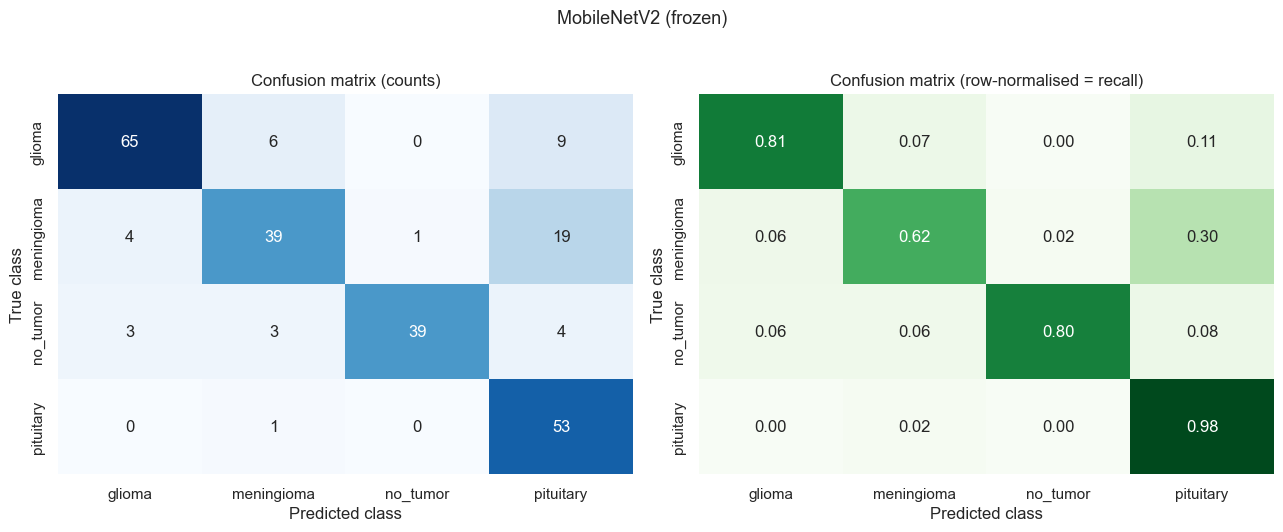

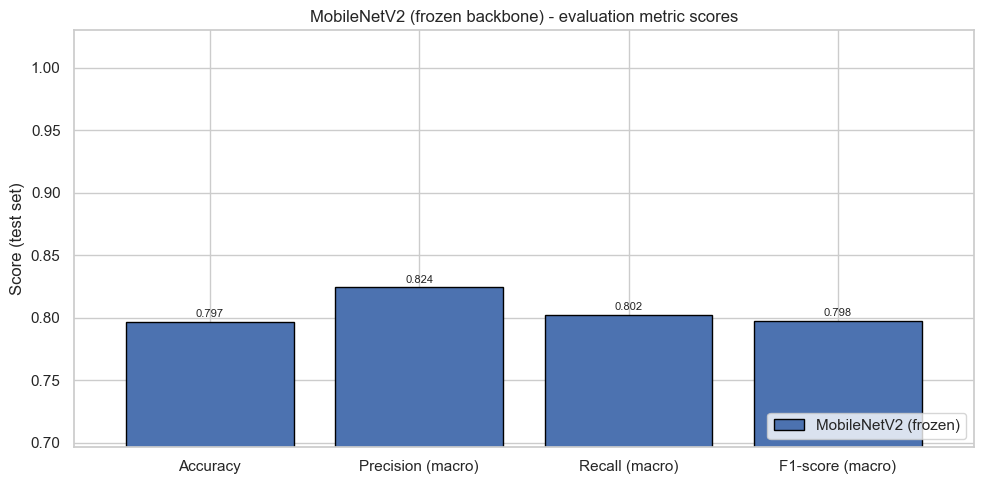

In [51]:
# Visualizing evaluation Metric Score chart
if run_transfer_section(NAME, 2):
    show_report(RESULTS[f"{NAME} (frozen)"], save_as="32_mobilenetv2_stage1_confusion")
    plot_metric_scores([f"{NAME} (frozen)"], f"{NAME} (frozen backbone) - evaluation metric scores", save_as="32_mobilenetv2_stage1_scores")

The scores above are those of the **frozen-backbone** model: the pretrained network is used as a fixed feature extractor and only the small head is trained. This already works well for medical images thanks to the generic low-level features (edges, textures) learned on ImageNet, and it is cheap because only a few hundred thousand parameters are trained.

#### 2. Cross- Validation & Hyperparameter Tuning
Hold-out validation + early stopping is used (see the cross-validation note under Model 1). The "hyper-parameters" tuned here are **how many backbone layers to unfreeze** and **the fine-tuning learning rate (1e-5)** - the two settings that matter most in transfer learning.

MobileNetV2: fine-tuning the top 30 backbone layers -> 1.84 M trainable parameters
Epoch 1/10
53/53 - 36s - loss: 0.4930 - accuracy: 0.8413 - val_loss: 0.5712 - val_accuracy: 0.8048 - lr: 1.0000e-05 - 36s/epoch - 686ms/step
Epoch 2/10
53/53 - 31s - loss: 0.5025 - accuracy: 0.8360 - val_loss: 0.5299 - val_accuracy: 0.8247 - lr: 1.0000e-05 - 31s/epoch - 583ms/step
Epoch 3/10
53/53 - 32s - loss: 0.4299 - accuracy: 0.8531 - val_loss: 0.6113 - val_accuracy: 0.8227 - lr: 1.0000e-05 - 32s/epoch - 601ms/step
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
53/53 - 45s - loss: 0.4947 - accuracy: 0.8484 - val_loss: 0.6766 - val_accuracy: 0.8048 - lr: 1.0000e-05 - 45s/epoch - 841ms/step
Epoch 5/10
53/53 - 48s - loss: 0.4535 - accuracy: 0.8324 - val_loss: 0.6232 - val_accuracy: 0.8287 - lr: 3.0000e-06 - 48s/epoch - 900ms/step
Epoch 6/10
Restoring model weights from the end of the best epoch: 2.

Epoch 6: ReduceLROnPlateau reducing learning rate to 8.99999963

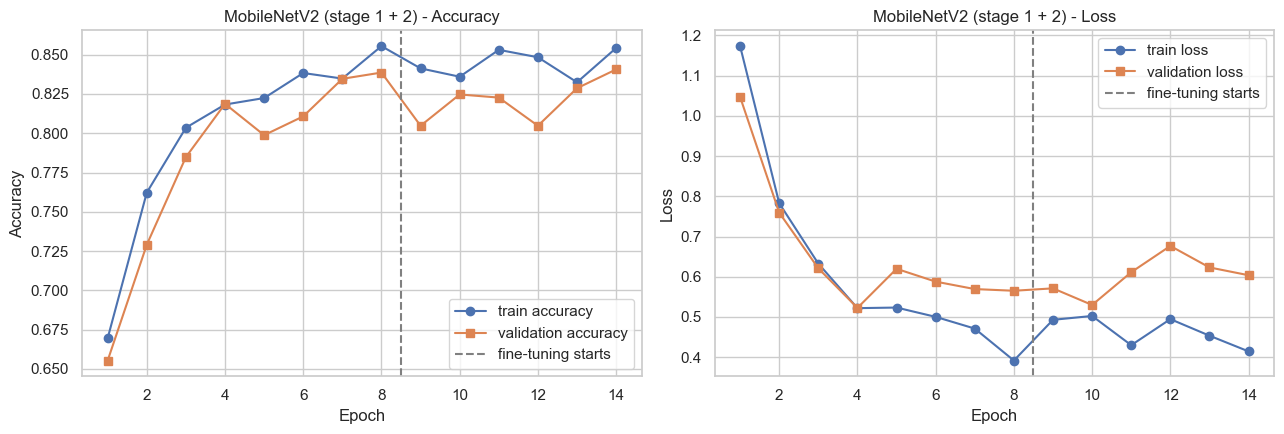

              precision    recall  f1-score   support

      glioma     0.8831    0.8500    0.8662        80
  meningioma     0.8043    0.5873    0.6789        63
    no_tumor     0.9302    0.8163    0.8696        49
   pituitary     0.6625    0.9815    0.7910        54

    accuracy                         0.8049       246
   macro avg     0.8200    0.8088    0.8014       246
weighted avg     0.8239    0.8049    0.8024       246



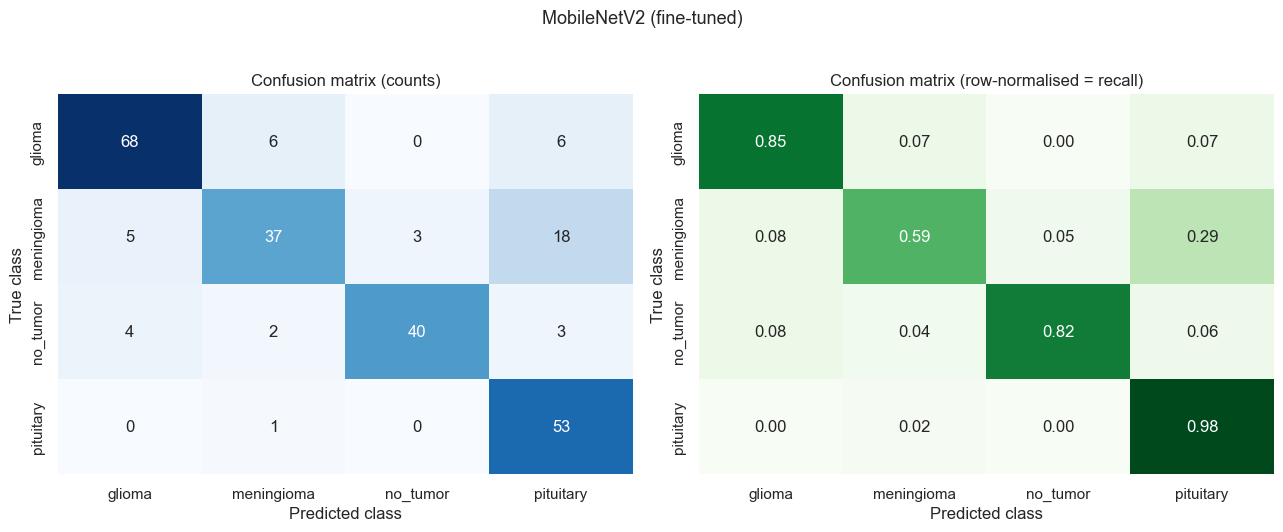

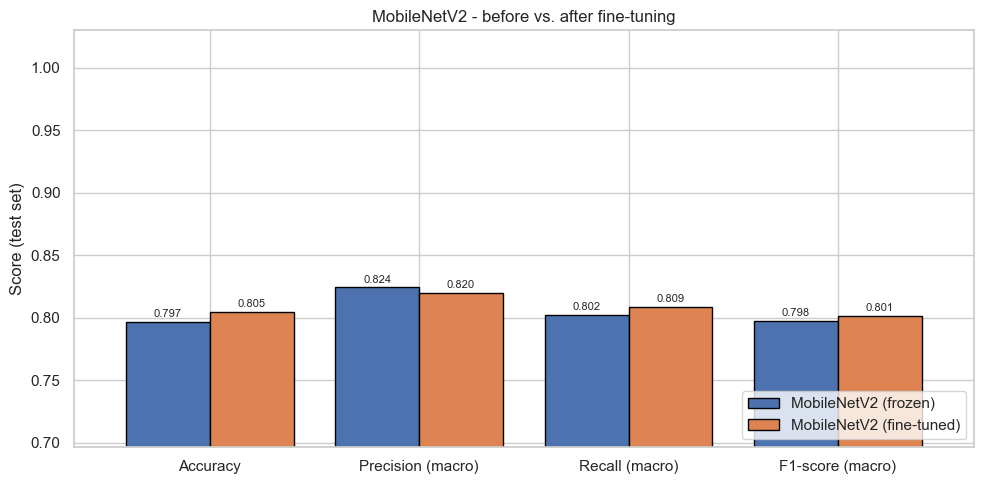

,before,after,change
metric,,,
Accuracy,0.7967,0.8049,+0.0081
Precision (macro),0.8243,0.8200,-0.0043
Recall (macro),0.8022,0.8088,+0.0065
F1-score (macro),0.7977,0.8014,+0.0038
ROC-AUC (OvR),0.9665,0.9699,+0.0034
Worst-class recall,0.6190,0.5873,-0.0317


Kept variant: MobileNetV2 (fine-tuned)  ->  mobilenetv2.h5


In [52]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (Stage 2 : fine-tuning)
# Fit the Algorithm
# Predict on the model
if run_transfer_section(NAME, 2):
    stage2_finetune(NAME)
    plot_history(merge_hist(HISTORIES[f"{NAME} (frozen)"], HISTORIES[f"{NAME} (fine-tuned)"]), f"{NAME} (stage 1 + 2)",
                 split_at=len(HISTORIES[f"{NAME} (frozen)"]["loss"]), save_as="32_mobilenetv2_full_history")
    show_report(RESULTS[f"{NAME} (fine-tuned)"], save_as="32_mobilenetv2_finetuned_confusion")
    plot_metric_scores([f"{NAME} (frozen)", f"{NAME} (fine-tuned)"], f"{NAME} - before vs. after fine-tuning",
                       save_as="32_mobilenetv2_finetuning_comparison")
    show_improvement(f"{NAME} (frozen)", f"{NAME} (fine-tuned)")
    finalize_transfer(NAME)

##### Which hyperparameter optimization technique have you used and why?

A **manual two-stage schedule**: (1) head training with a normal learning rate, (2) partial fine-tuning with a 100x smaller learning rate and frozen batch-norm layers. This is the recommended recipe for transfer learning - an automatic grid or random search would repeat expensive training runs for little extra benefit, and fine-tuning with a large learning rate would destroy the pretrained features.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

See the before / after chart and the improvement table. When the target domain (MRI) is different from ImageNet, fine-tuning normally improves recall on the harder classes. If the change is ~0 or negative, the validation-based selection automatically keeps the frozen-backbone weights, so the saved `.h5` file is always the better variant.

### ML Model - 3 : EfficientNetB0 (transfer learning)

EfficientNetB0 was found by neural architecture search and scales depth, width and resolution together (*compound scaling*) with squeeze-and-excitation blocks. It usually gives the best accuracy-per-parameter ratio of the family.

**Stage 1** keeps the ImageNet weights frozen and trains the new head (GAP - BatchNorm - Dropout - Dense(256) - Dropout - Softmax). **Stage 2** unfreezes the top backbone layers and fine-tunes them with lr = 1e-5 so the pretrained features adapt to MRI texture without being destroyed.

16705208/16705208 [==============================] - 8s 0us/step
EfficientNetB0: 4.38 M parameters, 0.33 M trainable in stage 1 (ImageNet weights loaded: True)
Epoch 1/8
53/53 - 56s - loss: 1.1302 - accuracy: 0.6584 - val_loss: 0.8243 - val_accuracy: 0.6434 - lr: 0.0010 - 56s/epoch - 1s/step
Epoch 2/8
53/53 - 41s - loss: 0.7667 - accuracy: 0.7687 - val_loss: 0.8293 - val_accuracy: 0.6434 - lr: 0.0010 - 41s/epoch - 774ms/step
Epoch 3/8
53/53 - 46s - loss: 0.6191 - accuracy: 0.7923 - val_loss: 0.7688 - val_accuracy: 0.7231 - lr: 0.0010 - 46s/epoch - 864ms/step
Epoch 4/8
53/53 - 43s - loss: 0.6026 - accuracy: 0.7994 - val_loss: 0.7737 - val_accuracy: 0.7171 - lr: 0.0010 - 43s/epoch - 805ms/step
Epoch 5/8

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
53/53 - 48s - loss: 0.5449 - accuracy: 0.8142 - val_loss: 0.7791 - val_accuracy: 0.7171 - lr: 0.0010 - 48s/epoch - 901ms/step
Epoch 6/8
53/53 - 46s - loss: 0.5186 - accuracy: 0.8301 - val_loss: 0.7638 - val_accur

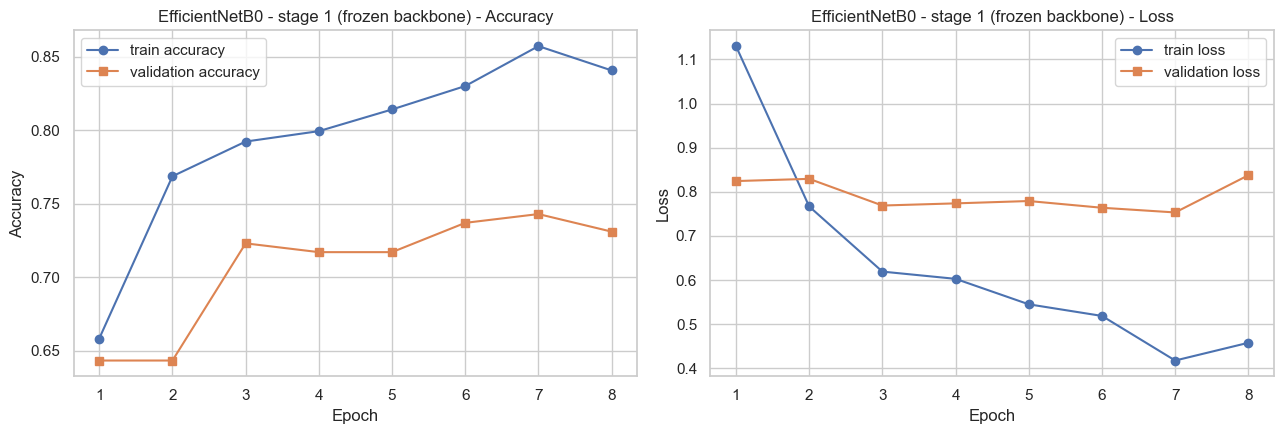

In [53]:
# ML Model - 3 Implementation  (Stage 1 : frozen backbone)
# Fit the Algorithm
# Predict on the model
NAME = "EfficientNetB0"
if run_transfer_section(NAME, 3):
    model_efficientnetb0, _ = stage1_transfer(NAME)
    plot_history(HISTORIES[f"{NAME} (frozen)"], f"{NAME} - stage 1 (frozen backbone)", save_as="33_efficientnetb0_stage1_history")

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

              precision    recall  f1-score   support

      glioma     0.9286    0.6500    0.7647        80
  meningioma     0.7561    0.4921    0.5962        63
    no_tumor     0.8043    0.7551    0.7789        49
   pituitary     0.5243    1.0000    0.6879        54

    accuracy                         0.7073       246
   macro avg     0.7533    0.7243    0.7069       246
weighted avg     0.7709    0.7073    0.7075       246



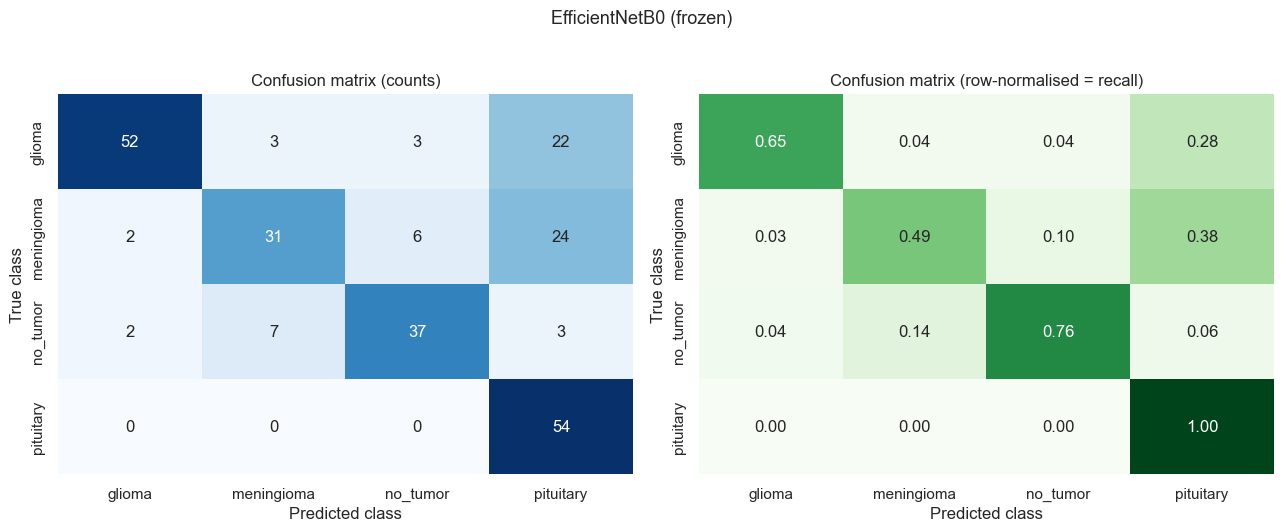

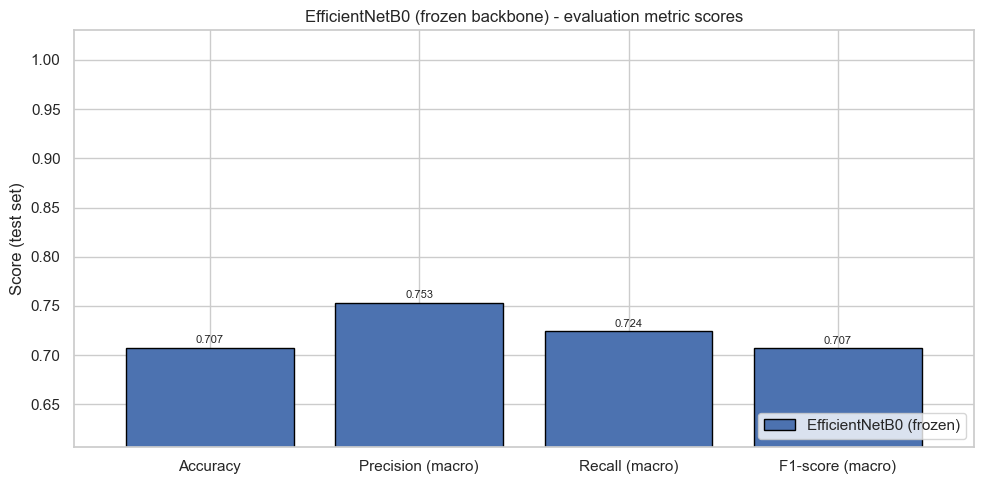

In [54]:
# Visualizing evaluation Metric Score chart
if run_transfer_section(NAME, 3):
    show_report(RESULTS[f"{NAME} (frozen)"], save_as="33_efficientnetb0_stage1_confusion")
    plot_metric_scores([f"{NAME} (frozen)"], f"{NAME} (frozen backbone) - evaluation metric scores", save_as="33_efficientnetb0_stage1_scores")

The scores above are those of the **frozen-backbone** model: the pretrained network is used as a fixed feature extractor and only the small head is trained. This already works well for medical images thanks to the generic low-level features (edges, textures) learned on ImageNet, and it is cheap because only a few hundred thousand parameters are trained.

#### 2. Cross- Validation & Hyperparameter Tuning
Hold-out validation + early stopping is used (see the cross-validation note under Model 1). The "hyper-parameters" tuned here are **how many backbone layers to unfreeze** and **the fine-tuning learning rate (1e-5)** - the two settings that matter most in transfer learning.

EfficientNetB0: fine-tuning the top 30 backbone layers -> 1.81 M trainable parameters
Epoch 1/10
53/53 - 79s - loss: 0.4290 - accuracy: 0.8531 - val_loss: 0.7625 - val_accuracy: 0.7510 - lr: 1.0000e-05 - 79s/epoch - 1s/step
Epoch 2/10
53/53 - 51s - loss: 0.4335 - accuracy: 0.8478 - val_loss: 0.7930 - val_accuracy: 0.7450 - lr: 1.0000e-05 - 51s/epoch - 968ms/step
Epoch 3/10

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
53/53 - 57s - loss: 0.4278 - accuracy: 0.8519 - val_loss: 0.8053 - val_accuracy: 0.7470 - lr: 1.0000e-05 - 57s/epoch - 1s/step
Epoch 4/10
53/53 - 55s - loss: 0.4450 - accuracy: 0.8442 - val_loss: 0.7980 - val_accuracy: 0.7470 - lr: 3.0000e-06 - 55s/epoch - 1s/step
Epoch 5/10
Restoring model weights from the end of the best epoch: 1.

Epoch 5: ReduceLROnPlateau reducing learning rate to 8.999999636216671e-07.
53/53 - 56s - loss: 0.4383 - accuracy: 0.8519 - val_loss: 0.7860 - val_accuracy: 0.7470 - lr: 3.0000e-06 - 56s/epoch - 1s/step
Epoch 5

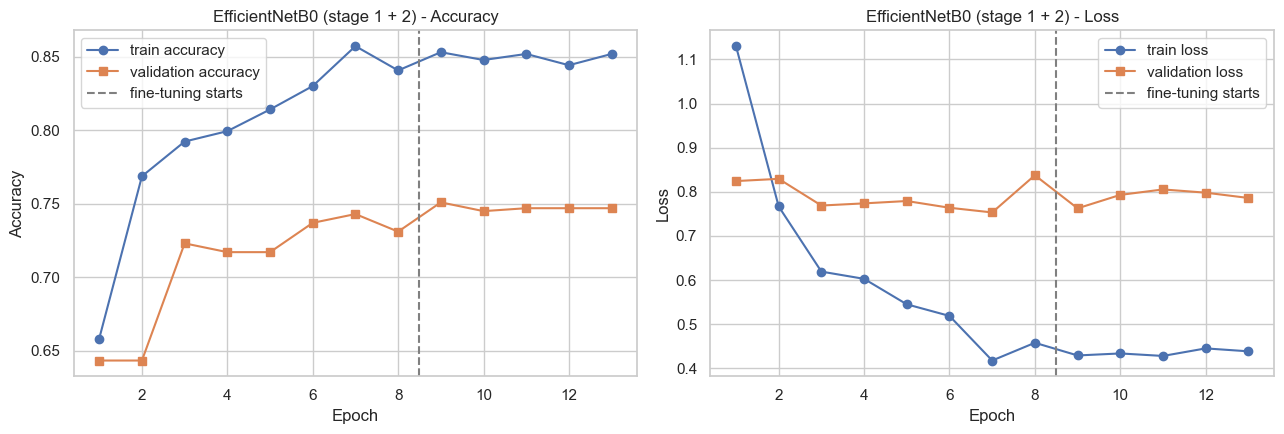

              precision    recall  f1-score   support

      glioma     0.9286    0.6500    0.7647        80
  meningioma     0.7442    0.5079    0.6038        63
    no_tumor     0.8409    0.7551    0.7957        49
   pituitary     0.5243    1.0000    0.6879        54

    accuracy                         0.7114       246
   macro avg     0.7595    0.7283    0.7130       246
weighted avg     0.7751    0.7114    0.7128       246



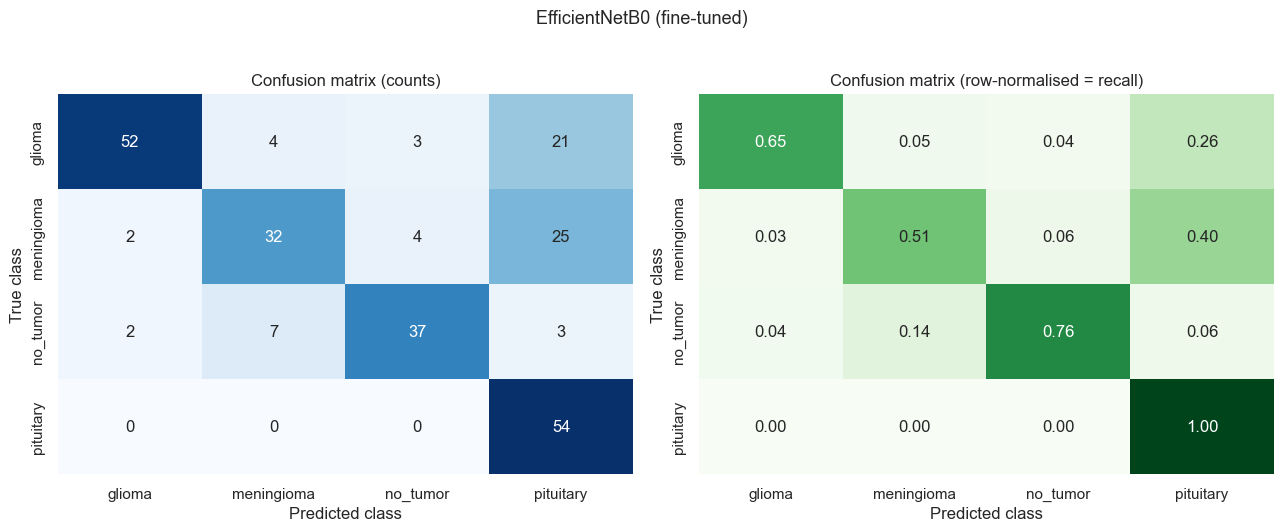

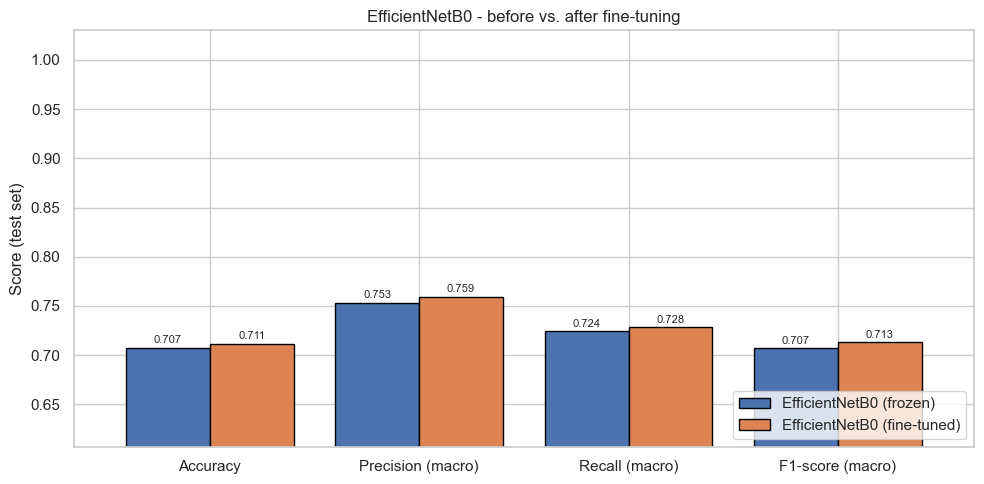

,before,after,change
metric,,,
Accuracy,0.7073,0.7114,+0.0041
Precision (macro),0.7533,0.7595,+0.0062
Recall (macro),0.7243,0.7283,+0.0040
F1-score (macro),0.7069,0.7130,+0.0061
ROC-AUC (OvR),0.9607,0.9617,+0.0010
Worst-class recall,0.4921,0.5079,+0.0159


Kept variant: EfficientNetB0 (fine-tuned)  ->  efficientnetb0.h5


In [55]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (Stage 2 : fine-tuning)
# Fit the Algorithm
# Predict on the model
if run_transfer_section(NAME, 3):
    stage2_finetune(NAME)
    plot_history(merge_hist(HISTORIES[f"{NAME} (frozen)"], HISTORIES[f"{NAME} (fine-tuned)"]), f"{NAME} (stage 1 + 2)",
                 split_at=len(HISTORIES[f"{NAME} (frozen)"]["loss"]), save_as="33_efficientnetb0_full_history")
    show_report(RESULTS[f"{NAME} (fine-tuned)"], save_as="33_efficientnetb0_finetuned_confusion")
    plot_metric_scores([f"{NAME} (frozen)", f"{NAME} (fine-tuned)"], f"{NAME} - before vs. after fine-tuning",
                       save_as="33_efficientnetb0_finetuning_comparison")
    show_improvement(f"{NAME} (frozen)", f"{NAME} (fine-tuned)")
    finalize_transfer(NAME)

##### Which hyperparameter optimization technique have you used and why?

A **manual two-stage schedule**: (1) head training with a normal learning rate, (2) partial fine-tuning with a 100x smaller learning rate and frozen batch-norm layers. This is the recommended recipe for transfer learning - an automatic grid or random search would repeat expensive training runs for little extra benefit, and fine-tuning with a large learning rate would destroy the pretrained features.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

See the before / after chart and the improvement table. When the target domain (MRI) is different from ImageNet, fine-tuning normally improves recall on the harder classes. If the change is ~0 or negative, the validation-based selection automatically keeps the frozen-backbone weights, so the saved `.h5` file is always the better variant.

### ML Model - 4 : ResNet50 (transfer learning)

ResNet50 is a 50-layer **residual network**: skip connections let gradients flow through very deep stacks, so it learns rich hierarchical features. It is larger (~23.5 M backbone parameters) and slower, but a very strong and well-understood baseline.

**Stage 1** keeps the ImageNet weights frozen and trains the new head (GAP - BatchNorm - Dropout - Dense(256) - Dropout - Softmax). **Stage 2** unfreezes the top backbone layers and fine-tunes them with lr = 1e-5 so the pretrained features adapt to MRI texture without being destroyed.

94765736/94765736 [==============================] - 36s 0us/step
ResNet50: 24.12 M parameters, 0.53 M trainable in stage 1 (ImageNet weights loaded: True)
Epoch 1/8
53/53 - 115s - loss: 1.1697 - accuracy: 0.6826 - val_loss: 1.2572 - val_accuracy: 0.6633 - lr: 0.0010 - 115s/epoch - 2s/step
Epoch 2/8
53/53 - 111s - loss: 0.8350 - accuracy: 0.7705 - val_loss: 0.5542 - val_accuracy: 0.8267 - lr: 0.0010 - 111s/epoch - 2s/step
Epoch 3/8
53/53 - 108s - loss: 0.6262 - accuracy: 0.8159 - val_loss: 0.5689 - val_accuracy: 0.8068 - lr: 0.0010 - 108s/epoch - 2s/step
Epoch 4/8
53/53 - 114s - loss: 0.5879 - accuracy: 0.8230 - val_loss: 0.5460 - val_accuracy: 0.8426 - lr: 0.0010 - 114s/epoch - 2s/step
Epoch 5/8
53/53 - 108s - loss: 0.5660 - accuracy: 0.8206 - val_loss: 0.7002 - val_accuracy: 0.7988 - lr: 0.0010 - 108s/epoch - 2s/step
Epoch 6/8
53/53 - 108s - loss: 0.5086 - accuracy: 0.8260 - val_loss: 0.5162 - val_accuracy: 0.8665 - lr: 0.0010 - 108s/epoch - 2s/step
Epoch 7/8
53/53 - 107s - loss: 0.4

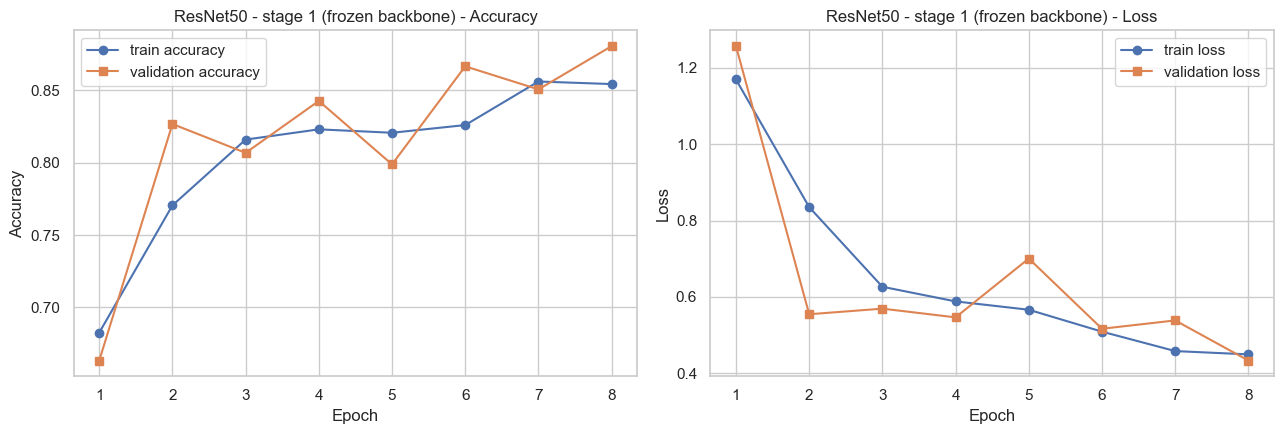

In [56]:
# ML Model - 4 Implementation  (Stage 1 : frozen backbone)
# Fit the Algorithm
# Predict on the model
NAME = "ResNet50"
if run_transfer_section(NAME, 4):
    model_resnet50, _ = stage1_transfer(NAME)
    plot_history(HISTORIES[f"{NAME} (frozen)"], f"{NAME} - stage 1 (frozen backbone)", save_as="34_resnet50_stage1_history")

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

              precision    recall  f1-score   support

      glioma     0.8605    0.9250    0.8916        80
  meningioma     0.7857    0.5238    0.6286        63
    no_tumor     0.8723    0.8367    0.8542        49
   pituitary     0.7465    0.9815    0.8480        54

    accuracy                         0.8171       246
   macro avg     0.8162    0.8168    0.8056       246
weighted avg     0.8187    0.8171    0.8072       246



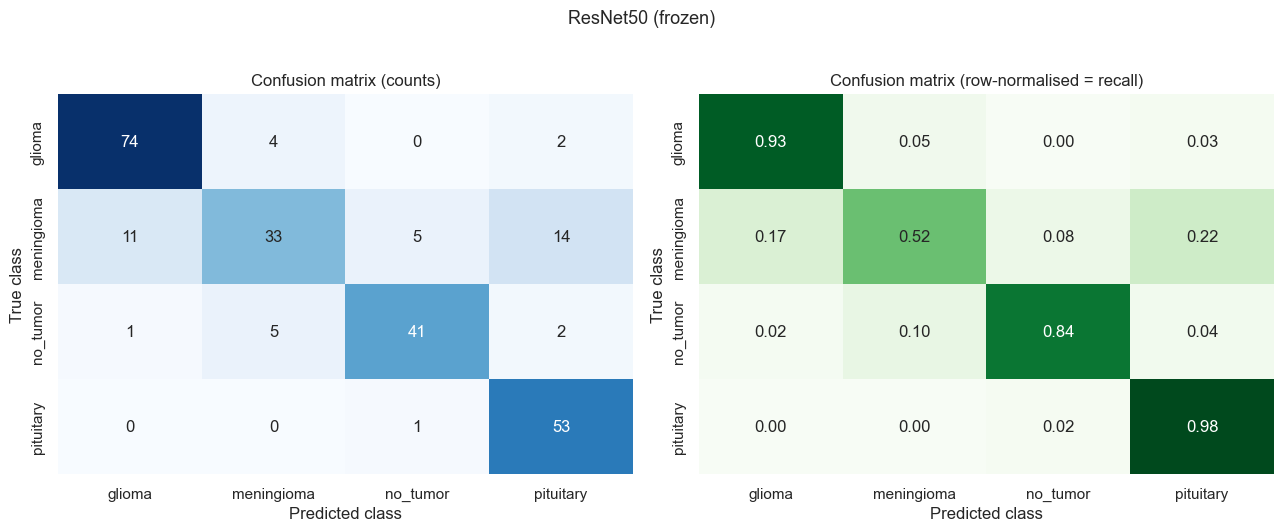

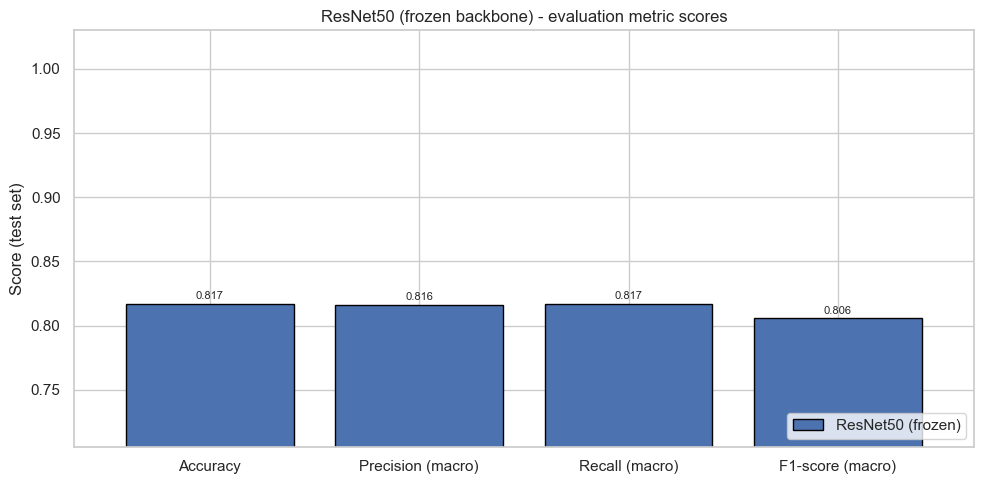

In [57]:
# Visualizing evaluation Metric Score chart
if run_transfer_section(NAME, 4):
    show_report(RESULTS[f"{NAME} (frozen)"], save_as="34_resnet50_stage1_confusion")
    plot_metric_scores([f"{NAME} (frozen)"], f"{NAME} (frozen backbone) - evaluation metric scores", save_as="34_resnet50_stage1_scores")

The scores above are those of the **frozen-backbone** model: the pretrained network is used as a fixed feature extractor and only the small head is trained. This already works well for medical images thanks to the generic low-level features (edges, textures) learned on ImageNet, and it is cheap because only a few hundred thousand parameters are trained.

#### 2. Cross- Validation & Hyperparameter Tuning
Hold-out validation + early stopping is used (see the cross-validation note under Model 1). The "hyper-parameters" tuned here are **how many backbone layers to unfreeze** and **the fine-tuning learning rate (1e-5)** - the two settings that matter most in transfer learning.

ResNet50: fine-tuning the top 30 backbone layers -> 14.96 M trainable parameters
Epoch 1/10
53/53 - 170s - loss: 0.3787 - accuracy: 0.8673 - val_loss: 0.4395 - val_accuracy: 0.8825 - lr: 1.0000e-05 - 170s/epoch - 3s/step
Epoch 2/10
53/53 - 157s - loss: 0.3988 - accuracy: 0.8761 - val_loss: 0.4716 - val_accuracy: 0.8845 - lr: 1.0000e-05 - 157s/epoch - 3s/step
Epoch 3/10

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
53/53 - 171s - loss: 0.3409 - accuracy: 0.8855 - val_loss: 0.4479 - val_accuracy: 0.8785 - lr: 1.0000e-05 - 171s/epoch - 3s/step
Epoch 4/10
53/53 - 168s - loss: 0.3250 - accuracy: 0.8926 - val_loss: 0.4374 - val_accuracy: 0.8904 - lr: 3.0000e-06 - 168s/epoch - 3s/step
Epoch 5/10
53/53 - 154s - loss: 0.3353 - accuracy: 0.8861 - val_loss: 0.4409 - val_accuracy: 0.8865 - lr: 3.0000e-06 - 154s/epoch - 3s/step
Epoch 6/10
53/53 - 166s - loss: 0.3089 - accuracy: 0.8950 - val_loss: 0.4370 - val_accuracy: 0.8924 - lr: 3.0000e-06 - 166s/epoch - 3s/step
E

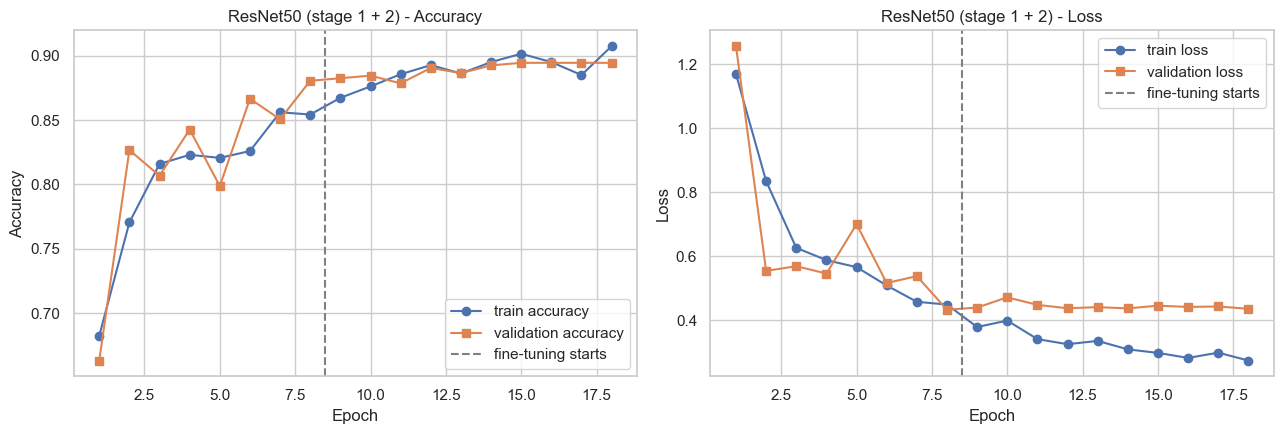

              precision    recall  f1-score   support

      glioma     0.9367    0.9250    0.9308        80
  meningioma     0.8298    0.6190    0.7091        63
    no_tumor     0.8750    0.8571    0.8660        49
   pituitary     0.7500    1.0000    0.8571        54

    accuracy                         0.8496       246
   macro avg     0.8479    0.8503    0.8408       246
weighted avg     0.8561    0.8496    0.8449       246



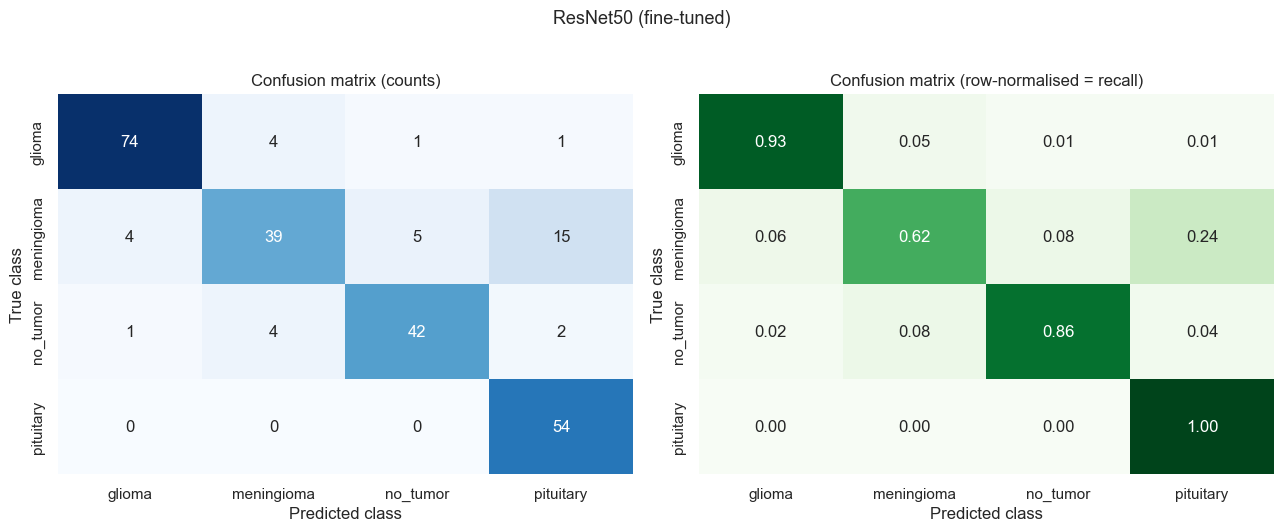

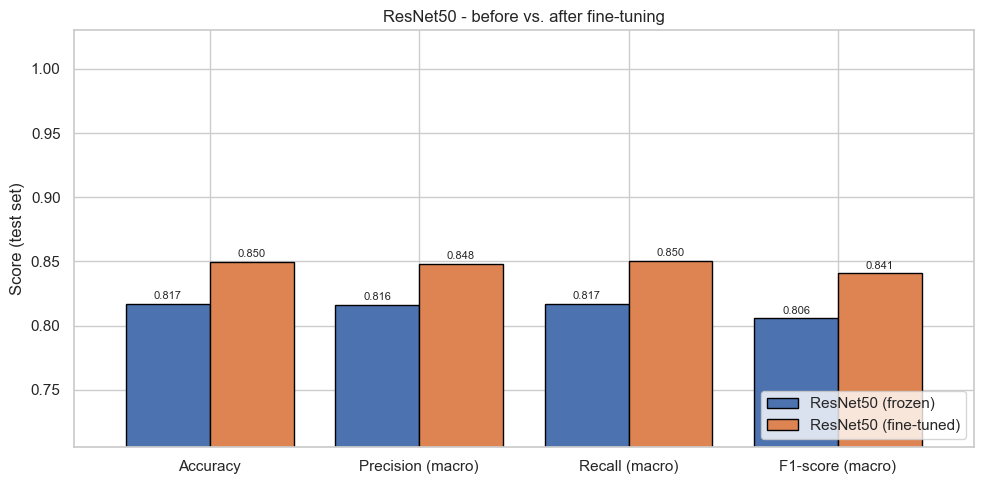

,before,after,change
metric,,,
Accuracy,0.8171,0.8496,+0.0325
Precision (macro),0.8162,0.8479,+0.0316
Recall (macro),0.8168,0.8503,+0.0335
F1-score (macro),0.8056,0.8408,+0.0352
ROC-AUC (OvR),0.9690,0.9770,+0.0080
Worst-class recall,0.5238,0.6190,+0.0952


Kept variant: ResNet50 (fine-tuned)  ->  resnet50.h5


In [58]:
# ML Model - 4 Implementation with hyperparameter optimization techniques (Stage 2 : fine-tuning)
# Fit the Algorithm
# Predict on the model
if run_transfer_section(NAME, 4):
    stage2_finetune(NAME)
    plot_history(merge_hist(HISTORIES[f"{NAME} (frozen)"], HISTORIES[f"{NAME} (fine-tuned)"]), f"{NAME} (stage 1 + 2)",
                 split_at=len(HISTORIES[f"{NAME} (frozen)"]["loss"]), save_as="34_resnet50_full_history")
    show_report(RESULTS[f"{NAME} (fine-tuned)"], save_as="34_resnet50_finetuned_confusion")
    plot_metric_scores([f"{NAME} (frozen)", f"{NAME} (fine-tuned)"], f"{NAME} - before vs. after fine-tuning",
                       save_as="34_resnet50_finetuning_comparison")
    show_improvement(f"{NAME} (frozen)", f"{NAME} (fine-tuned)")
    finalize_transfer(NAME)

##### Which hyperparameter optimization technique have you used and why?

A **manual two-stage schedule**: (1) head training with a normal learning rate, (2) partial fine-tuning with a 100x smaller learning rate and frozen batch-norm layers. This is the recommended recipe for transfer learning - an automatic grid or random search would repeat expensive training runs for little extra benefit, and fine-tuning with a large learning rate would destroy the pretrained features.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

See the before / after chart and the improvement table. When the target domain (MRI) is different from ImageNet, fine-tuning normally improves recall on the harder classes. If the change is ~0 or negative, the validation-based selection automatically keeps the frozen-backbone weights, so the saved `.h5` file is always the better variant.

### 7.5 Model Comparison - custom CNN vs. pretrained models

All four models are compared on the **same untouched test set**. Besides the quality metrics we also compare *efficiency* (parameters, file size, inference time per image) and *reliability* (the recall of the worst class - the model that misses a tumour type completely is not reliable, even with a good average).

,Model,Kept variant,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC,Worst-class recall,Val F1 (selection),Params (M),File size (MB),Inference (ms/img),Train time (min)
0,ResNet50,ResNet50 (fine-tuned),0.8496,0.8479,0.8503,0.8408,0.9770,0.6190,0.8890,24.1215,216.5530,51.5880,44.1969
1,MobileNetV2,MobileNetV2 (fine-tuned),0.8049,0.8200,0.8088,0.8014,0.9699,0.5873,0.8160,2.5921,25.4831,14.0230,7.7330
2,EfficientNetB0,EfficientNetB0 (fine-tuned),0.7114,0.7595,0.7283,0.7130,0.9617,0.5079,0.7522,4.3837,32.5147,19.9442,11.6202
3,Custom CNN,Custom CNN (baseline),0.3252,0.0813,0.2500,0.1227,0.6572,0.0000,0.1214,1.2427,15.0790,30.7293,29.3279


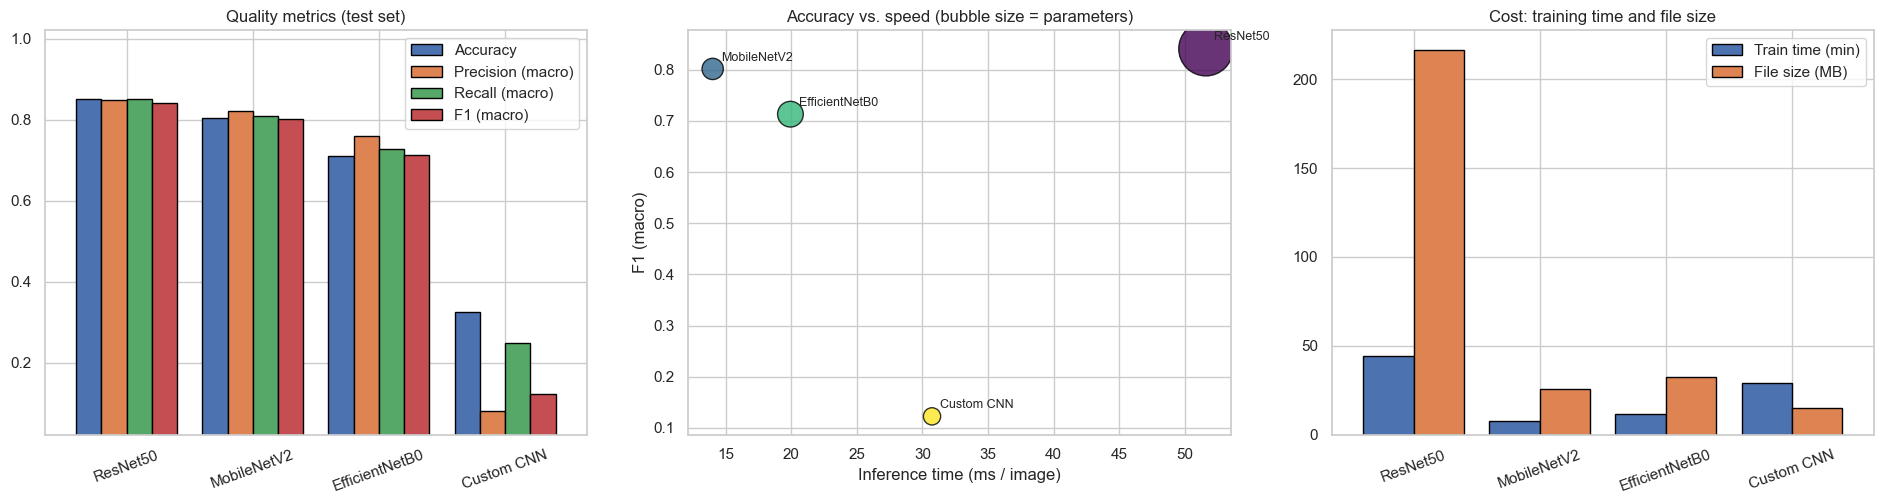

In [59]:
# Build the comparison table from the kept variant of every architecture
rows = []
for arch, item in FINAL.items():
    r = item["result"]
    rows.append({"Model": arch, "Kept variant": item["variant"],
                 "Accuracy": r["accuracy"], "Precision (macro)": r["precision_macro"], "Recall (macro)": r["recall_macro"],
                 "F1 (macro)": r["f1_macro"], "ROC-AUC": r["roc_auc"], "Worst-class recall": r["min_class_recall"],
                 "Val F1 (selection)": r["val_f1_macro"], "Params (M)": r["params_m"],
                 "File size (MB)": Path(item["path"]).stat().st_size / 1e6,
                 "Inference (ms/img)": r["inference_ms"], "Train time (min)": r["train_minutes"]})
comparison = pd.DataFrame(rows).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

# ---- charts ----
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
comparison.set_index("Model")[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot(kind="bar", ax=axes[0], width=0.8, edgecolor="black")
axes[0].set_ylim(max(0, comparison[["Accuracy", "F1 (macro)"]].values.min() - 0.1), 1.02)
axes[0].set_title("Quality metrics (test set)"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=20)
sc = axes[1].scatter(comparison["Inference (ms/img)"], comparison["F1 (macro)"], s=comparison["Params (M)"] * 60 + 80,
                     c=range(len(comparison)), cmap="viridis", alpha=0.8, edgecolor="black")
for _, r in comparison.iterrows():
    axes[1].annotate(r["Model"], (r["Inference (ms/img)"], r["F1 (macro)"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
axes[1].set_title("Accuracy vs. speed (bubble size = parameters)"); axes[1].set_xlabel("Inference time (ms / image)"); axes[1].set_ylabel("F1 (macro)")
comparison.set_index("Model")[["Train time (min)", "File size (MB)"]].plot(kind="bar", ax=axes[2], width=0.8, edgecolor="black")
axes[2].set_title("Cost: training time and file size"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=20)
finish_plot("40_model_comparison")

FINAL MODEL: ResNet50  (ResNet50 (fine-tuned))
  test accuracy = 0.8496 | macro-F1 = 0.8408 | worst-class recall = 0.6190 | 51.6 ms / image
              precision    recall  f1-score   support

      glioma     0.9367    0.9250    0.9308        80
  meningioma     0.8298    0.6190    0.7091        63
    no_tumor     0.8750    0.8571    0.8660        49
   pituitary     0.7500    1.0000    0.8571        54

    accuracy                         0.8496       246
   macro avg     0.8479    0.8503    0.8408       246
weighted avg     0.8561    0.8496    0.8449       246



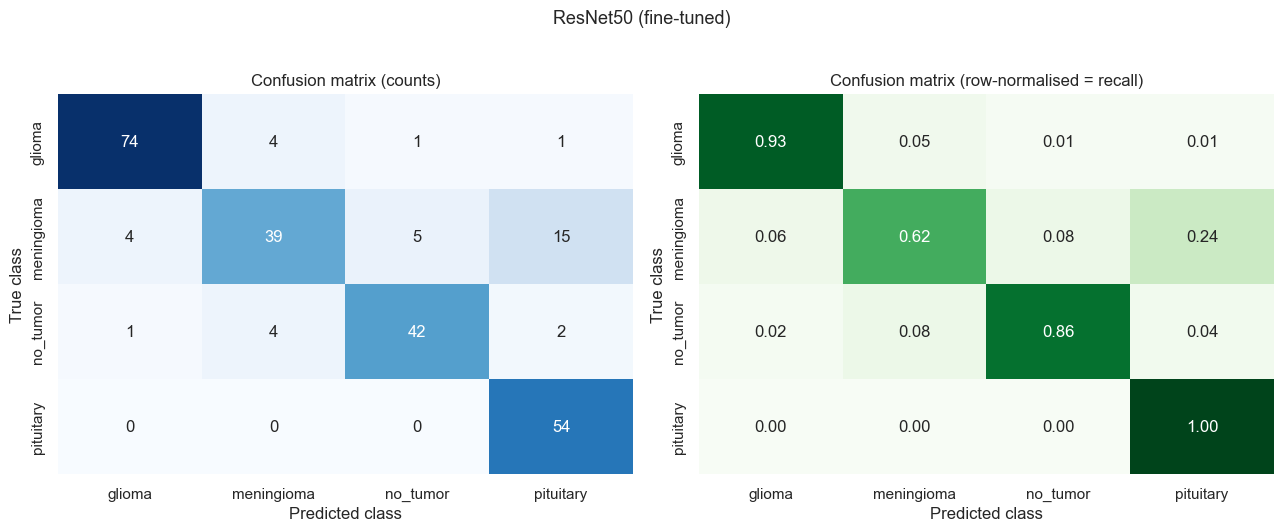

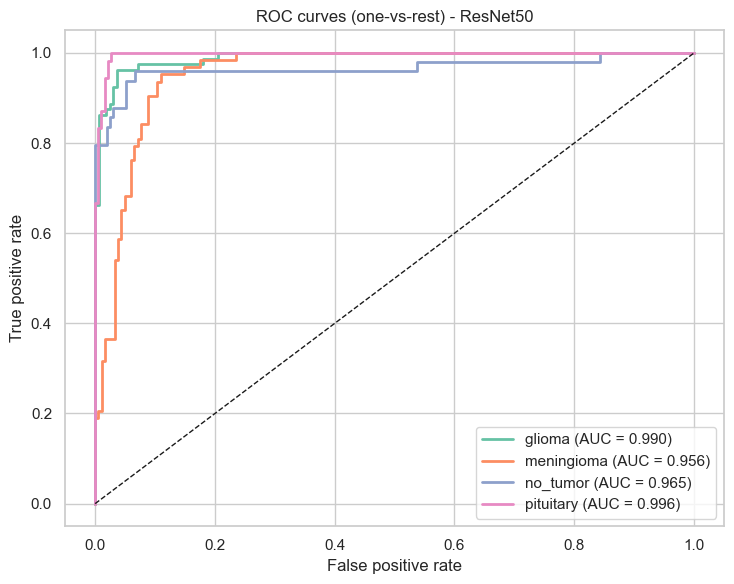

In [60]:
# Choose the final model: highest VALIDATION macro-F1 (rounded to 3 decimals), ties broken by the faster model
def rank_key(item):
    r = item[1]["result"]
    return (round(r["val_f1_macro"], 3), -r["inference_ms"])

best_arch = max(FINAL.items(), key=rank_key)[0]
best = FINAL[best_arch]
print(f"FINAL MODEL: {best_arch}  ({best['variant']})")
print(f"  test accuracy = {best['result']['accuracy']:.4f} | macro-F1 = {best['result']['f1_macro']:.4f} | "
      f"worst-class recall = {best['result']['min_class_recall']:.4f} | {best['result']['inference_ms']:.1f} ms / image")
show_report(best["result"], save_as="41_best_model_confusion")

# ROC curves (one-vs-rest) of the final model
fig, ax = plt.subplots(figsize=(7.5, 6))
y_onehot = np.eye(NUM_CLASSES)[best["result"]["y_true"]]
for i, c in enumerate(class_names):
    if y_onehot[:, i].sum() > 0:
        fpr, tpr, _ = roc_curve(y_onehot[:, i], best["result"]["y_prob"][:, i])
        ax.plot(fpr, tpr, lw=2, color=palette[c], label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curves (one-vs-rest) - {best_arch}"); ax.legend(loc="lower right")
finish_plot("42_best_model_roc")

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* **Recall (sensitivity) per class - the most important metric.** A *false negative* is a tumour that the AI overlooks; in a triage setting that can delay treatment, so recall (especially the **worst-class recall**) is the primary safety metric.
* **Precision.** A *false positive* sends a healthy / different case to specialist review. Low precision wastes radiologist time and erodes trust in the tool, so it determines the operational cost.
* **F1-score (macro).** The harmonic mean of precision and recall, averaged over classes so that small classes count as much as large ones. It is our main ranking metric.
* **Accuracy.** Easy to communicate to managers, but misleading on imbalanced data, so it is reported but never used alone.
* **ROC-AUC (one-vs-rest).** Shows how well the model's *confidence* ranks cases independently of a threshold - useful for deciding the confidence threshold above which a prediction is shown without a warning.
* **Confusion matrix.** Shows *which* tumour types are confused (e.g. glioma vs. meningioma), which matters clinically more than a single number.
* **Efficiency metrics** (inference time, size) determine the hosting cost and whether the tool can run in real time in a small clinic.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The final model is the architecture printed above (**highest validation macro-F1, ties broken by speed**). Selection on the *validation* set - not the test set - keeps the test score an honest estimate. It is chosen because it delivers the best balance of quality (macro-F1 and worst-class recall) and cost. If two models are statistically indistinguishable on quality, the smaller / faster one is preferable for deployment; the comparison table lets you make that trade-off explicitly (e.g. choosing MobileNetV2 for a CPU-only server).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

A CNN has no tabular "feature importance". The equivalent is **where in the image the model looks**. We use **occlusion sensitivity**, a model-agnostic explainability technique: a grey square is slid over the scan and the drop in the predicted-class probability is recorded - regions whose occlusion hurts the prediction most are the regions the model relies on.

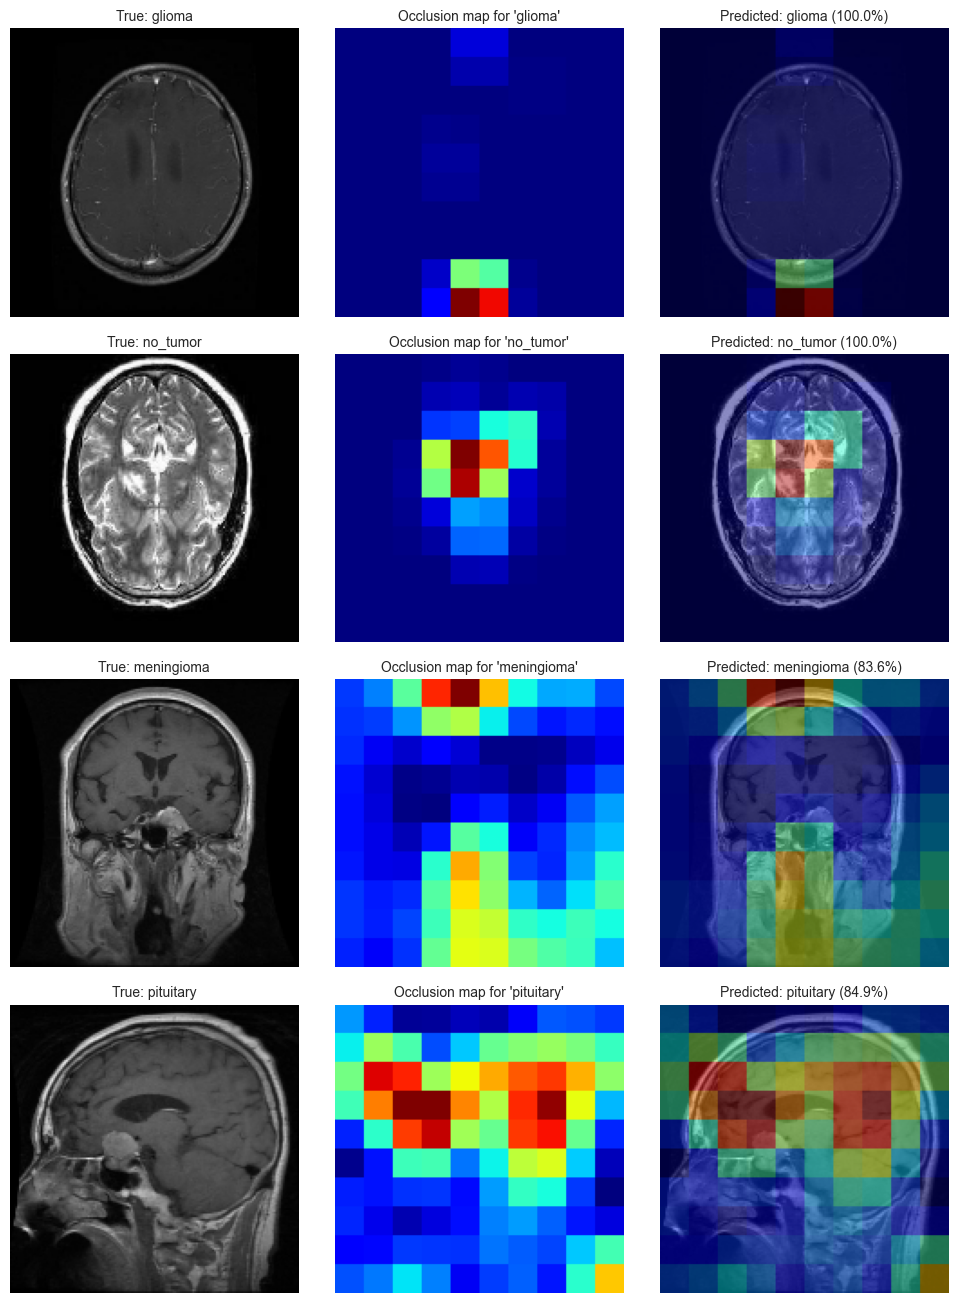

In [61]:
# Explainability: occlusion-sensitivity maps of the final model
final_model = best["model"]

def occlusion_map(model, img, class_idx, patch=32, stride=16):
    """Probability drop of `class_idx` when a patch x patch square is hidden at every position."""
    H, W, _ = img.shape
    base_p = float(model.predict(img[None], verbose=0)[0][class_idx])
    fill = float(img.mean())
    batch, coords = [], []
    for y in range(0, H - patch + 1, stride):
        for x in range(0, W - patch + 1, stride):
            im = img.copy(); im[y:y + patch, x:x + patch, :] = fill
            batch.append(im); coords.append((y, x))
    probs = model.predict(np.stack(batch), batch_size=64, verbose=0)[:, class_idx]
    heat, cnt = np.zeros((H, W)), np.zeros((H, W))
    for (y, x), p in zip(coords, probs):
        heat[y:y + patch, x:x + patch] += base_p - p
        cnt[y:y + patch, x:x + patch] += 1
    return heat / np.maximum(cnt, 1), base_p

picked = test_df.sample(frac=1, random_state=SEED).drop_duplicates("label").head(4).reset_index(drop=True)   # one test scan per class
fig, axes = plt.subplots(len(picked), 3, figsize=(10, 3.3 * len(picked)), squeeze=False)
for i, row in picked.iterrows():
    img = preprocess_bytes(tf.io.read_file(row["filepath"])).numpy()
    probs = final_model.predict(img[None], verbose=0)[0]
    k = int(probs.argmax())
    heat, _ = occlusion_map(final_model, img, k)
    axes[i, 0].imshow(img); axes[i, 0].set_title(f"True: {row['label']}", fontsize=10)
    axes[i, 1].imshow(heat, cmap="jet"); axes[i, 1].set_title(f"Occlusion map for '{class_names[k]}'", fontsize=10)
    axes[i, 2].imshow(img); axes[i, 2].imshow(heat, cmap="jet", alpha=0.45)
    axes[i, 2].set_title(f"Predicted: {class_names[k]} ({probs[k]:.1%})", fontsize=10)
    for ax in axes[i]:
        ax.axis("off")
finish_plot("43_occlusion_explainability")

**How to read the maps:** red / yellow areas are the regions that matter most for the prediction. A trustworthy model concentrates on the tumour and surrounding tissue; if the map highlights the image corners, borders or burnt-in text, the model would be using irrelevant shortcuts and should not be deployed. In a clinical roll-out, a stronger tool such as Grad-CAM combined with radiologist review should complement this analysis.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.
Deep-learning models are not pickled; the Keras `.h5` format is the standard (and the one the project requires). Every kept model was already saved as `.h5`; below the best one is copied to `best_model.h5` and a **JSON configuration** with the class names, preprocessing and metrics is written - the Streamlit app reads exactly these files.

In [62]:
# Save the File
best_src = Path(best["path"])
best_dst = MODEL_DIR / f"best_model{best_src.suffix}"
shutil.copy(best_src, best_dst)

def clean_metrics(r):
    return {k: (None if (isinstance(r[k], float) and np.isnan(r[k])) else round(float(r[k]), 4))
            for k in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc", "min_class_recall", "inference_ms", "params_m"]}

config = {
    "class_names": class_names,
    "img_size": list(IMG_SIZE),
    "preprocessing": "decode -> RGB -> bilinear resize to img_size -> divide by 255 (range 0-1). Same function as preprocess_bytes() in the notebook.",
    "best_model": best_arch,
    "best_model_file": best_dst.name,
    "models": {arch: {"file": Path(item["path"]).name, "variant": item["variant"], "metrics": clean_metrics(item["result"])}
               for arch, item in FINAL.items()},
}
with open(MODEL_DIR / "model_config.json", "w") as fh:
    json.dump(config, fh, indent=2)
with open(MODEL_DIR / "class_names.json", "w") as fh:
    json.dump(class_names, fh, indent=2)

# keep the results next to the metadata in the SQLite database
with sqlite3.connect(DB_PATH) as con:
    comparison.to_sql("model_results", con, if_exists="replace", index=False)

print("Saved files:")
for p in sorted(MODEL_DIR.iterdir()):
    print(f"  {p.name:<28} {p.stat().st_size / 1e6:8.2f} MB")

Saved files:
  best_model.h5                  216.55 MB
  class_names.json                 0.00 MB
  custom_cnn.h5                   15.08 MB
  efficientnetb0.h5               32.51 MB
  mobilenetv2.h5                  25.48 MB
  model_config.json                0.00 MB
  resnet50.h5                    216.55 MB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

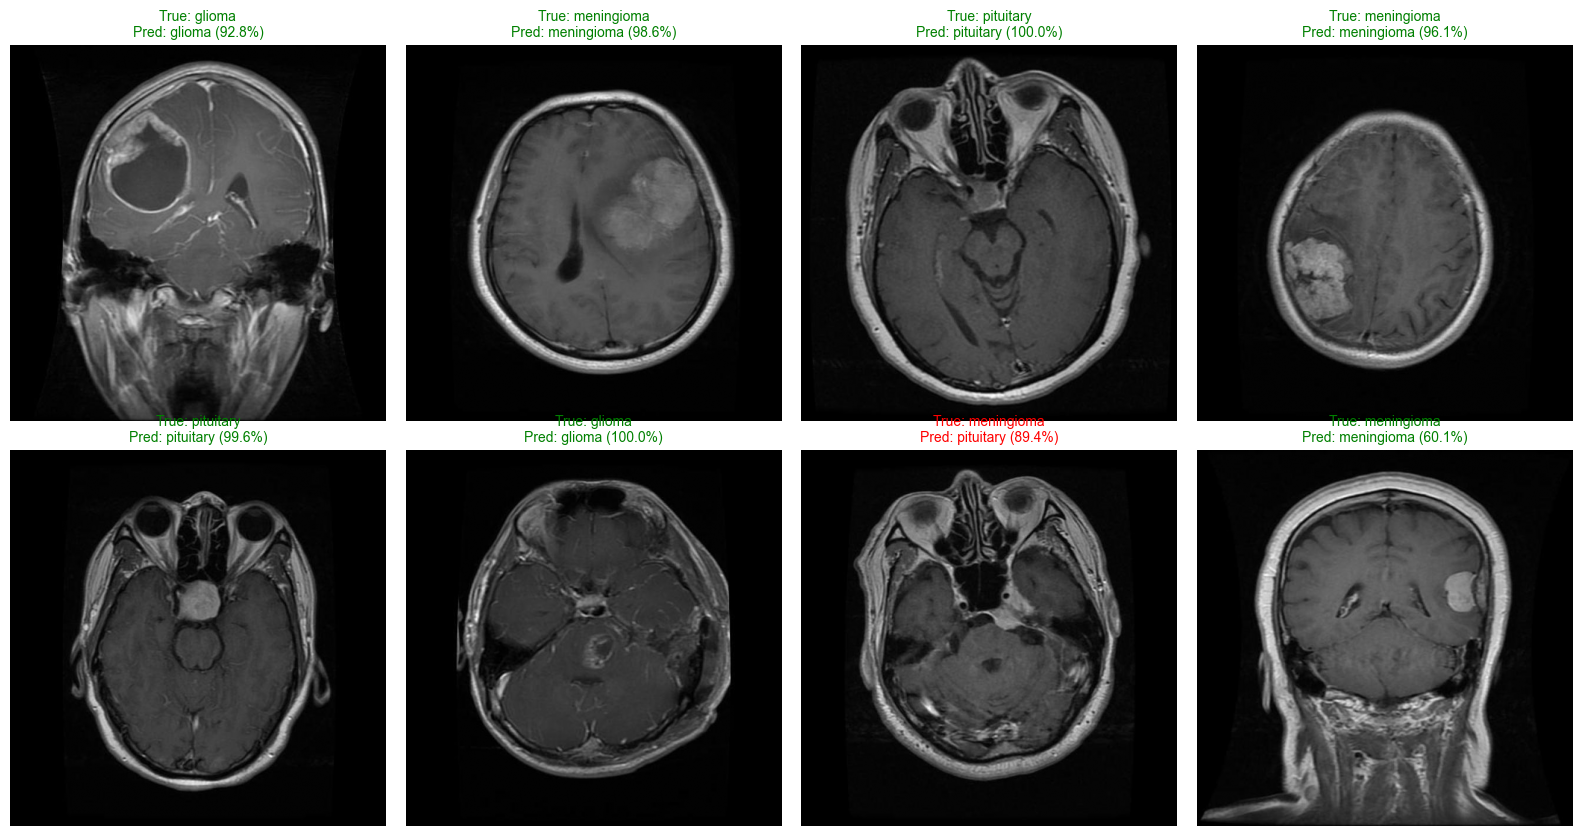

Sanity check: 7/8 correct | max difference between saved and in-memory model probabilities = 0.00e+00


In [63]:
# Load the File and predict unseen data.
try:
    loaded = keras.models.load_model(str(best_dst), compile=False)
except Exception as exc:
    alt = best_dst.with_suffix(".keras")
    print(f"Loading {best_dst.name} failed ({exc}); trying {alt.name}")
    final_model.save(str(alt)); loaded = keras.models.load_model(str(alt), compile=False)

def predict_image(path_or_bytes, model=loaded):
    """Predict one image: the same pipeline as the Streamlit app."""
    raw = bytes(path_or_bytes) if isinstance(path_or_bytes, (bytes, bytearray)) else tf.io.read_file(str(path_or_bytes))
    probs = model.predict(preprocess_bytes(raw).numpy()[None], verbose=0)[0]
    k = int(probs.argmax())
    return {"class": class_names[k], "confidence": float(probs[k]), "probabilities": dict(zip(class_names, probs.tolist()))}

sample = test_df.sample(min(8, len(test_df)), random_state=7).reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
n_ok, max_diff = 0, 0.0
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    out = predict_image(row["filepath"])
    ref = final_model.predict(preprocess_bytes(tf.io.read_file(row["filepath"])).numpy()[None], verbose=0)[0]
    max_diff = max(max_diff, float(np.abs(ref - np.array(list(out["probabilities"].values()))).max()))
    ok = out["class"] == row["label"]; n_ok += ok
    ax.imshow(Image.open(row["filepath"]).convert("L"), cmap="gray"); ax.axis("off")
    ax.set_title(f"True: {row['label']}\nPred: {out['class']} ({out['confidence']:.1%})", color="green" if ok else "red", fontsize=10)
for ax in axes.ravel()[len(sample):]:
    ax.axis("off")
finish_plot("44_sanity_check_predictions")
print(f"Sanity check: {n_ok}/{len(sample)} correct | max difference between saved and in-memory model probabilities = {max_diff:.2e}")
if max_diff > 1e-3:
    print("WARNING: the reloaded model differs from the in-memory model - re-run the save cell or use the .keras file.")

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

**Next step:** open `Streamlit_Deployment.ipynb` (or run `streamlit run app.py` in a terminal) to start the web application.

# **Conclusion**

* A full pipeline for **brain-MRI tumour-type classification** was built: data discovery and cleaning (corrupted files, duplicates and train/test leakage removed), a metadata table stored as CSV + SQLite, 15 UBM charts, 3 hypothesis tests, a leakage-safe train / validation / test split and an augmented `tf.data` input pipeline.
* A **custom CNN** (tuned with random search) and three **transfer-learning models** (MobileNetV2, EfficientNetB0, ResNet50 - frozen then fine-tuned) were trained with EarlyStopping, ModelCheckpoint and ReduceLROnPlateau, and compared with accuracy, precision, recall, F1-score, ROC-AUC, worst-class recall, confusion matrices, size and speed.
* The final model was selected on the **validation** set so that the **test** scores remain unbiased; the pretrained models normally outperform the from-scratch CNN on this small medical dataset, and the comparison table shows by how much and at what cost.
* Occlusion-sensitivity maps check that the model looks at brain tissue and not at irrelevant image borders.
* All models, the class list and a JSON configuration are saved in `models/`, and the Streamlit application uses them to deliver **real-time predictions with confidence scores**.
* **Limitations / future work:** one public dataset (no external hospital validation), 2-D slices only, no patient-level split information, no probability calibration. Before any clinical use the model needs prospective validation, calibration, Grad-CAM / radiologist review and regulatory approval. It is a **decision-support prototype, not a diagnostic device**.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***